# Honours Research: Full Pipeline in One Notebook
**BIC score trees vs SHAP (XGBoost) trees for Bayesian-network structure learning on ALARM**

This notebook brings together all ten of the original notebooks, in the order the experiments were run. Every heading collapses, so press the arrow next to a heading to open or close that part.

**How to use it**
1. Edit **only** the configuration cell in *0.3 Configuration* (the paths, seeds, and which steps to run).
2. Run *0. Setup* and *1. Shared functions* first. Every later cell needs them.
3. After that, run any section top to bottom. Each step reads what the earlier steps saved to disk, so you can re-run just the graphs (for example *4.2*) without re-running the slow model training.

| Part | What it does | Output folders |
|---|---|---|
| 2 | Builds the 10 synthetic ground truths from ALARM | `1.ALARM` … `8.SyntheticSamples` |
| 3 | RQ1 structure learning (BIC trees, SHAP trees) and parameter learning | `9` … `12` |
| 4 | RQ1 results: KL divergence, SHD, DoF explanation | `13`, `14` |
| 5 | RQ2: learning the real ALARM network (10 seeds) and the DoF explanation | `16. New Samples` |
| Appendix | What was merged or removed, and the graphs whose code was not in the notebooks | none |

# 0. Setup

## 0.1 Install (run once)

Graphviz is used only for the `dot` layouts (the original ALARM picture and the tree pictures). If it is missing, the code falls back to the fixed ALARM node positions, so the experiment results are unaffected.

In [ ]:
# Uncomment and run once if a package is missing.
# %pip install pgmpy shap xgboost networkx pandas numpy scikit-learn matplotlib
# %pip install pygraphviz      # optional, for the Graphviz "dot" layouts

## 0.2 Imports and library versions

In [ ]:
import os, re, csv, glob, json, random, warnings, itertools
from math import log
from collections import defaultdict

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import shap
import pgmpy
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mutual_info_score, accuracy_score, f1_score, confusion_matrix, r2_score

from pgmpy.readwrite import BIFReader, BIFWriter
from pgmpy.sampling import BayesianModelSampling
from pgmpy.factors.discrete import TabularCPD
from pgmpy.estimators import BayesianEstimator
try:
    from pgmpy.models import DiscreteBayesianNetwork as BNClass
except ImportError:                      # older pgmpy
    from pgmpy.models import BayesianNetwork as BNClass

warnings.filterwarnings("ignore", category=FutureWarning)

import sys, sklearn, xgboost, matplotlib
print("python    ", sys.version.split()[0])
for _m in (pgmpy, shap, xgboost, sklearn, np, pd, nx, matplotlib):
    print(f"{_m.__name__:10s}", _m.__version__)
# Record these versions in your report: results (especially SHAP/XGBoost) can shift between versions.

## 0.3 Configuration

This is the only cell you need to edit. The default values reproduce the original runs.

The `RUN` switches turn each step on or off. They are **all off** to start with, because the graphs from your original runs are already saved in the cells below. A switched-off step just prints `skipped`, so **Run All** is safe and only defines the functions. Switch on only the steps you want to re-run. The slow ones are the SHAP trees (3.3, 5.1) and the RQ1 KL values (4.1). The graph-only steps (4.2, 4.3, 4.4, 5.1.5, 5.2) take seconds, because they read the CSVs and graphs already saved on disk.

In [ ]:
# =====================================================================
# PATHS
# =====================================================================
ROOT = r"C:\Users\keevo\OneDrive\Documents\Keevon Jacobs Wits\Honors year\Research Program"
EXP  = os.path.join(ROOT, "Experiments")     # tip: point at a NEW folder for a clean, from-scratch re-run
ALARM_BIF = os.path.join(ROOT, "alarm.bif", "alarm.bif")

DIRS = {
    "alarm":       os.path.join(EXP, "1.ALARM"),
    "gt_samples":  os.path.join(EXP, "2.Ground Truth Samples"),
    "mi":          os.path.join(EXP, "3.MI_Matrices"),
    "gt_trees":    os.path.join(EXP, "4.Ground_Truth_Trees"),
    "gt_directed": os.path.join(EXP, "5.Directed_Ground_Truths"),
    "gt_compare":  os.path.join(EXP, "6.Comparisons"),
    "tabular":     os.path.join(EXP, "7.TabularCPD"),
    "synth":       os.path.join(EXP, "8.SyntheticSamples"),
    "bic":         os.path.join(EXP, "9.BIC Score Structures"),
    "bic_cpd":     os.path.join(EXP, "10.BIC CPD"),
    "shap":        os.path.join(EXP, "11.SHAPLY"),
    "shap_cpd":    os.path.join(EXP, "12.SHAPLY CPD"),
    "kl_rq1":      os.path.join(EXP, "13.KL Divergence XGBoost VS BIC"),
    "shd_rq1":     os.path.join(EXP, "14.Stuctural Hamming distance"),
    "new":         os.path.join(EXP, "16. New Samples"),
}
DIRS["results"] = os.path.join(DIRS["new"], "Results")

# =====================================================================
# EXPERIMENT GRID
# =====================================================================
GT_IDS             = list(range(1, 11))              # synthetic ground truths 1..10 (GT i <-> Directed_GT_{i}000)
ALARM_SAMPLE_SIZES = list(range(1000, 10001, 1000))  # ALARM samples used to build GT i (= size/1000)
SAMPLE_SIZES       = [50, 100, 500, 1000, 2000, 3000, 5000, 6000]
SEEDS              = [42, 43, 44, 45, 46, 47, 48, 49, 50, 51]   # RQ2 repeated experiment

# =====================================================================
# SEEDS AND CONSTANTS  (these are the values used in the original runs)
# =====================================================================
SEED_ALARM_SAMPLES = 42      # forward sampling ALARM -> ground_truth_{n}.csv
SEED_GT_ROOT       = 42      # random root when orienting each MI tree
SEED_GT_CPD        = 42      # Dirichlet draws for each ground-truth CPD (reset for every GT)
SEED_SYNTH_SAMPLES = 42      # forward sampling each synthetic GT
SEED_SHAP          = 100     # XGBoost + train/val/test splits (RQ1)
# RQ2 10 seeds: the ALARM sample of size n for seed s uses seed s + n, and XGBoost uses seed s

KL_RQ1_N_SAMPLES = 500_000   # Monte-Carlo samples for KL(GT || learned) in RQ1
KL_RQ1_BATCH     = 50_000
KL_RQ1_SEED      = 1
KL_REF_N         = 20_000    # reference samples from the real ALARM for RQ2 KL
KL_REF_SEED      = 42
PSEUDO_COUNT     = 1.0       # Dirichlet prior (+1 per CPT cell)
EPS              = 1e-300

XGB_PARAMS = dict(n_estimators=200, max_depth=6, learning_rate=0.05,
                  subsample=0.8, colsample_bytree=0.8, n_jobs=-1)

# =====================================================================
# OPTIONS THAT CHANGE RESULTS  (defaults = exactly what the originals did)
# =====================================================================
BIC_COMPARE_AGAINST  = "MST"                 # 3.2: "MST" (original: undirected 4.Ground_Truth_Trees) or "DIRECTED_GT"
DOF_RQ1_SOURCE       = "comparison_graphml"  # 4.4: "comparison_graphml" (original) or "learned_dag"
DOF_TRUE_CARDINALITY = False                 # 4.4/5.2: False = original (every node counted as 2 states)

# =====================================================================
# WHICH STEPS TO RUN  (all off: the saved graphs from your original runs are already in the cells;
#                      switch on only the steps you want to re-run)
# =====================================================================
RUN = {
    # Part 2: ground truths
    "2.1_alarm_graph": False, "2.2_alarm_samples": False, "2.3_mi": False, "2.4_mi_trees": False,
    "2.5_orient_gt": False, "2.6_gt_vs_alarm": False, "2.7_tabular_cpd": False, "2.8_synth_samples": False,
    # Part 3: RQ1 structure + parameter learning
    "3.1_bic_trees": False, "3.2_bic_compare": False, "3.3_shap_trees": False,
    "3.4_shap_compare": False, "3.5_param_learning": False,
    # Part 4: RQ1 results
    "4.1_kl_values": False, "4.2_kl_graphs": False, "4.3_shd": False, "4.4_dof": False,
    # Part 5: RQ2
    "5.1_ten_seeds": False,
    "5.2_dof": False,
}

# =====================================================================
# FILE-NAME HELPERS (match the existing folder structure)
# =====================================================================
ORIGINAL_ALARM_GRAPHML = os.path.join(DIRS["alarm"], "Original_ALARM.graphml")
def gt_n(i):              return i * 1000
def alarm_sample_csv(n):  return os.path.join(DIRS["gt_samples"], f"ground_truth_{n}.csv")
def mi_csv(n):            return os.path.join(DIRS["mi"], f"MI_matrix_{n}.csv")
def mst_graphml(n):       return os.path.join(DIRS["gt_trees"], f"MST_{n}.graphml")
def directed_gt(n):       return os.path.join(DIRS["gt_directed"], f"Directed_GT_{n}.graphml")
def tabular_bif(i):       return os.path.join(DIRS["tabular"], str(i), f"Directed_GT_{gt_n(i)}_with_CPDS.bif")
def synth_csv(i, j):      return os.path.join(DIRS["synth"], f"GroundTruth{i}", f"GT_1000_samples_{j}.csv")  # "GT_1000" kept for every GT, as in the originals
def bic_dir(i, j):        return os.path.join(DIRS["bic"], str(i), f"sample{j}")
def bic_graph(i, j, alg="Kruskal"): return os.path.join(bic_dir(i, j), f"GT{i}_N{j}_BIC_{alg}.graphml")
def shap_dir(i, j):       return os.path.join(DIRS["shap"], str(i), f"sample{j}")
def shap_dag(i, j):       return os.path.join(shap_dir(i, j), "SHAP_Oriented_DAG.graphml")
def shap_cmp_graphml(i, j): return os.path.join(shap_dir(i, j), "Comparisons", "SHAP_DAG_vs_GT_comparison.graphml")
def bic_cpd_bif(i, j):    return os.path.join(DIRS["bic_cpd"], str(i), f"sample{j}", "BIC_with_CPDS.bif")
def shap_cpd_bif(i, j):   return os.path.join(DIRS["shap_cpd"], str(i), f"sample{j}", "SHAPLY_with_CPDS.bif")
def kl_rq1_csv(i, j):     return os.path.join(DIRS["kl_rq1"], str(i), f"sample{j}", "kl_divergence.csv")
def new_sample_csv(n, seed=None):
    return os.path.join(DIRS["new"], f"ground_truth_{n}.csv" if seed is None else f"ground_truth_{n}_seed{seed}.csv")

print("EXP folder :", EXP)
print("alarm.bif  :", ALARM_BIF, "| exists:", os.path.exists(ALARM_BIF))

# 1. Shared functions

Each function in this part is defined once and reused everywhere below. In the original notebooks, functions such as the BIC score, the SHAP tree, the edge comparison, the CPD learner, and the KL code were copied into five to ten different cells.

## 1.1 General helpers

In [ ]:
def ensure_dir(path):
    os.makedirs(path, exist_ok=True)
    return path

def banner(text, width=70):
    print("=" * width); print(text); print("=" * width)

def run_step(key, fn):
    """Run one pipeline step if RUN[key] is True."""
    if not RUN.get(key, False):
        print(f"[skipped] {key}  (set RUN['{key}'] = True to run it)")
        return None
    banner(f"STEP {key}")
    return fn()

def read_graph(path, to_directed=False):
    """Read a GraphML file with string node ids (optionally forcing a DiGraph)."""
    G = nx.read_graphml(path)
    if to_directed and not G.is_directed():
        G = G.to_directed()
    return nx.relabel_nodes(G, {n: str(n) for n in G.nodes()})

def load_alarm():
    return BIFReader(ALARM_BIF).get_model()

def load_bn(path):
    return BIFReader(path).get_model()

def load_samples_str(path):
    """CSV with every column as a string (used for CPD learning and the RQ2 BIC trees)."""
    df = pd.read_csv(path)
    for col in df.columns:
        df[col] = df[col].astype(str)
    return df

def save_bn(bn, path):
    try:
        bn.save(path, filetype="bif")
    except Exception:
        BIFWriter(bn).write_bif(path)
    return path

def write_cpds_txt(cpds, path):
    with open(path, "w") as f:
        for cpd in cpds:
            f.write("=" * 80 + "\n" + f"CPD: {cpd.variable}\n" + "=" * 80 + "\n" + str(cpd) + "\n\n")
    return path

def save_fig(path, show=True, dpi=300):
    plt.savefig(path, dpi=dpi, bbox_inches="tight")
    plt.show() if show else plt.close()
    print("Saved:", path)

## 1.2 ALARM states and fixed node positions

In [ ]:
# State names used to generate the synthetic ground-truth CPDs (2.7). Order matters for reproducibility.
ALARM_STATES = {
    "CVP": ["LOW", "NORMAL", "HIGH"], "PCWP": ["LOW", "NORMAL", "HIGH"], "HISTORY": ["TRUE", "FALSE"],
    "TPR": ["LOW", "NORMAL", "HIGH"], "BP": ["LOW", "NORMAL", "HIGH"], "CO": ["LOW", "NORMAL", "HIGH"],
    "HRBP": ["LOW", "NORMAL", "HIGH"], "HREKG": ["LOW", "NORMAL", "HIGH"], "HREK": ["LOW", "NORMAL", "HIGH"],
    "HRSAT": ["LOW", "NORMAL", "HIGH"], "PAP": ["LOW", "NORMAL", "HIGH"], "PVSAT": ["LOW", "NORMAL", "HIGH"],
    "SAO2": ["LOW", "NORMAL", "HIGH"], "FIO2": ["LOW", "NORMAL"], "PRESS": ["ZERO", "LOW", "NORMAL", "HIGH"],
    "EXPCO2": ["ZERO", "LOW", "NORMAL", "HIGH"], "MINVOL": ["ZERO", "LOW", "NORMAL", "HIGH"],
    "MINVOLSET": ["LOW", "NORMAL", "HIGH"], "HYPOVOLEMIA": ["TRUE", "FALSE"], "LVFAILURE": ["TRUE", "FALSE"],
    "ANAPHYLAXIS": ["TRUE", "FALSE"], "INSUFFANESTH": ["TRUE", "FALSE"], "PULMEMBOLUS": ["TRUE", "FALSE"],
    "INTUBATION": ["NORMAL", "ESOPHAGEAL", "ONESIDED"], "KINKEDTUBE": ["TRUE", "FALSE"],
    "DISCONNECT": ["TRUE", "FALSE"], "LVEDVOLUME": ["LOW", "NORMAL", "HIGH"],
    "STROKEVOLUME": ["LOW", "NORMAL", "HIGH"], "CATECHOL": ["NORMAL", "HIGH"], "ERRLOWOUTPUT": ["TRUE", "FALSE"],
    "HR": ["LOW", "NORMAL", "HIGH"], "ERRCAUTER": ["TRUE", "FALSE"], "SHUNT": ["NORMAL", "HIGH"],
    "PVS": ["LOW", "NORMAL", "HIGH"], "ARTCO2": ["LOW", "NORMAL", "HIGH"],
    "VENTALV": ["ZERO", "LOW", "NORMAL", "HIGH"], "VENTLUNG": ["ZERO", "LOW", "NORMAL", "HIGH"],
    "VENTTUBE": ["ZERO", "LOW", "NORMAL", "HIGH"], "VENTMACH": ["ZERO", "LOW", "NORMAL", "HIGH"],
}

# Graphviz "dot" layout of the original ALARM network (used for every comparison picture).
ALARM_POS = {
    'ANAPHYLAXIS': (76.43, 378.0), 'ARTCO2': (669.43, 378.0), 'BP': (134.43, 18.0),
    'CATECHOL': (566.43, 234.0), 'CO': (276.43, 90.0), 'CVP': (160.43, 90.0),
    'DISCONNECT': (883.43, 666.0), 'ERRCAUTER': (829.43, 162.0), 'ERRLOWOUTPUT': (586.43, 162.0),
    'EXPCO2': (789.43, 306.0), 'FIO2': (557.43, 450.0), 'HISTORY': (431.43, 162.0),
    'HR': (718.43, 162.0), 'HRBP': (605.43, 90.0), 'HREKG': (720.43, 90.0), 'HRSAT': (826.43, 90.0),
    'HYPOVOLEMIA': (109.43, 234.0), 'INSUFFANESTH': (436.43, 306.0), 'INTUBATION': (656.43, 594.0),
    'KINKEDTUBE': (811.43, 594.0), 'LVEDVOLUME': (96.43, 162.0), 'LVFAILURE': (276.43, 234.0),
    'MINVOL': (779.43, 450.0), 'MINVOLSET': (1034.4, 738.0), 'PAP': (430.43, 522.0),
    'PCWP': (77.43, 90.0), 'PRESS': (900.43, 522.0), 'PULMEMBOLUS': (470.43, 594.0),
    'PVSAT': (566.43, 378.0), 'SAO2': (566.43, 306.0), 'SHUNT': (517.43, 522.0),
    'STROKEVOLUME': (276.43, 162.0), 'TPR': (76.43, 306.0), 'VENTALV': (659.43, 450.0),
    'VENTLUNG': (783.43, 522.0), 'VENTMACH': (1034.4, 666.0), 'VENTTUBE': (959.43, 594.0),
}

def layout(G, prog="dot", fallback="alarm", seed=42):
    """Graphviz layout if pygraphviz is installed, else fixed ALARM positions (or spring layout)."""
    try:
        from networkx.drawing.nx_agraph import graphviz_layout
        return graphviz_layout(G, prog=prog)
    except Exception:
        if fallback == "alarm" and all(n in ALARM_POS for n in G.nodes()):
            return dict(ALARM_POS)
        return nx.spring_layout(G, seed=seed)

def save_positions(pos, json_path=None, txt_path=None):
    if json_path:
        with open(json_path, "w") as f:
            json.dump({str(k): [float(v[0]), float(v[1])] for k, v in pos.items()}, f, indent=4)
    if txt_path:
        with open(txt_path, "w") as f:
            f.write("NODE POSITIONS\n" + "=" * 60 + "\n" + f"Total nodes: {len(pos)}\n" + "-" * 40 + "\n")
            f.write(f"{'Node':15} {'X':>12} {'Y':>12}\n" + "-" * 40 + "\n")
            for node in sorted(pos):
                f.write(f"{node:15} {pos[node][0]:12.4f} {pos[node][1]:12.4f}\n")
            f.write("-" * 40 + "\n")

## 1.3 Drawing networks

In [ ]:
def draw_network(G, pos, path, title, figsize=(18, 14), node_size=1200, node_color="lightblue",
                 font_size=8, arrows=None, arrowsize=20, width=1.0, edge_label_attr=None,
                 edge_label_size=7, highlight=None, show=True):
    """One drawing routine for every tree / DAG picture."""
    plt.figure(figsize=figsize)
    nx.draw(G, pos, with_labels=True, node_size=node_size, node_color=node_color,
            font_size=font_size, arrows=G.is_directed() if arrows is None else arrows,
            arrowsize=arrowsize, width=width)
    if highlight:
        nx.draw_networkx_nodes(G, pos, nodelist=list(highlight), node_color="red", node_size=node_size + 400)
    if edge_label_attr:
        labels = {(u, v): f"{d[edge_label_attr]:.2f}" for u, v, d in G.edges(data=True) if edge_label_attr in d}
        nx.draw_networkx_edge_labels(G, pos, edge_labels=labels, font_size=edge_label_size)
    plt.title(title)
    plt.tight_layout()
    save_fig(path, show=show)

## 1.4 Edge comparison and SHD

`classify_edges` is the single edge classifier behind every comparison picture, every recovery %, and every SHD value:
* **correct**: same directed edge in both graphs
* **reversal**: the reference has u→v, the learned graph has v→u
* **deletion**: a reference edge missing from the learned graph (in either direction)
* **addition**: a learned edge not in the reference (in either direction)

**SHD** = reversals + deletions + additions. **Skeleton SHD** (orientation ignored) = deletions + additions.

In [ ]:
def classify_edges(ref_edges, cand_edges):
    ref_edges, cand_edges = set(ref_edges), set(cand_edges)
    correct  = ref_edges & cand_edges
    reversed_ = {(u, v) for (u, v) in ref_edges if (v, u) in cand_edges}
    deleted  = {(u, v) for (u, v) in ref_edges if (u, v) not in cand_edges and (v, u) not in cand_edges}
    added    = {(u, v) for (u, v) in cand_edges if (u, v) not in ref_edges and (v, u) not in ref_edges}
    ref_skel  = {frozenset(e) for e in ref_edges}
    cand_skel = {frozenset(e) for e in cand_edges}
    return dict(
        correct=correct, reversed=reversed_, deleted=deleted, added=added,
        ref_count=len(ref_edges), cand_count=len(cand_edges),
        directed_recovery=len(correct) / len(ref_edges) * 100 if ref_edges else 0.0,
        skeleton_recovery=len(ref_skel & cand_skel) / len(ref_skel) * 100 if ref_skel else 0.0,
    )

def shd_counts(ref_edges, cand_edges):
    r = classify_edges(ref_edges, cand_edges)
    return {"edges": r["cand_count"], "correct": len(r["correct"]), "reversed": len(r["reversed"]),
            "added": len(r["added"]), "deleted": len(r["deleted"]),
            "SHD": len(r["reversed"]) + len(r["added"]) + len(r["deleted"]),
            "SHD_skeleton": len(r["added"]) + len(r["deleted"])}

def print_comparison(res, list_edges=True):
    print(f"Correct directed edges : {len(res['correct'])}")
    print(f"Reversed edges         : {len(res['reversed'])}")
    print(f"Deleted edges          : {len(res['deleted'])}")
    print(f"Added edges            : {len(res['added'])}")
    print(f"Directed recovery      : {res['directed_recovery']:.2f}%")
    print(f"Skeleton recovery      : {res['skeleton_recovery']:.2f}%")
    if list_edges:
        for name in ("correct", "reversed", "deleted", "added"):
            print(f"\n{name.upper()} EDGES\n" + "-" * 40)
            for u, v in sorted(res[name]):
                print(f"{u} -> {v}" + (f"  becomes  {v} -> {u}" if name == "reversed" else ""))

def comparison_records(res):
    rows = [{"source": u, "target": v, "classification": "correct"} for u, v in res["correct"]]
    rows += [{"source": u, "target": v, "classification": "reversal", "comparison_source": v,
              "comparison_target": u} for u, v in res["reversed"]]
    rows += [{"source": u, "target": v, "classification": "deletion"} for u, v in res["deleted"]]
    rows += [{"source": u, "target": v, "classification": "addition"} for u, v in res["added"]]
    return pd.DataFrame(rows)

def comparison_summary(res, **extra):
    return pd.DataFrame([{**extra,
        "Reference_Edges": res["ref_count"], "Learned_Edges": res["cand_count"],
        "Correct_Directed_Edges": len(res["correct"]), "Reversed_Edges": len(res["reversed"]),
        "Deleted_Edges": len(res["deleted"]), "Added_Edges": len(res["added"]),
        "SHD": len(res["reversed"]) + len(res["deleted"]) + len(res["added"]),
        "Directed_Recovery_Percent": res["directed_recovery"],
        "Skeleton_Recovery_Percent": res["skeleton_recovery"]}])

def comparison_graph(res, nodes):
    """Combined graph: correct, reversal (drawn in learned direction), deletion, addition."""
    g = nx.DiGraph(); g.add_nodes_from(nodes)
    for u, v in res["correct"]:  g.add_edge(u, v, classification="correct")
    for u, v in res["reversed"]: g.add_edge(v, u, classification="reversal")
    for u, v in res["deleted"]:  g.add_edge(u, v, classification="deletion")
    for u, v in res["added"]:    g.add_edge(u, v, classification="addition")
    return g

LEGEND = [Line2D([0], [0], color="green", lw=3, label="Correct / overlapping edge"),
          Line2D([0], [0], color="red", lw=3, label="Edge reversal"),
          Line2D([0], [0], color="black", lw=2, linestyle=":", label="Edge deletion"),
          Line2D([0], [0], color="blue", lw=3, label="Edge addition")]

def draw_comparison(ax, nodes, pos, res, title, small=False, show_shd=False):
    ns, fs, rad = (700, 6, "arc3,rad=0.05") if small else (900, 8, "arc3,rad=0.0")
    nodes = [n for n in nodes if n in pos]
    G = nx.DiGraph(); G.add_nodes_from(nodes)
    nx.draw_networkx_nodes(G, pos, ax=ax, nodelist=nodes, node_color="white", edgecolors="black",
                           node_size=ns, linewidths=1.5)
    nx.draw_networkx_labels(G, pos, ax=ax, labels={n: n for n in nodes}, font_size=fs, font_weight="bold")
    styles = [("correct", "green", 2.5, "solid", 18, 1.0, False),
              ("reversed", "red", 3.0, "solid", 20, 1.0, True),
              ("deleted", "black", 2.0, "dotted", 16, 0.8, False),
              ("added", "blue", 2.5, "solid", 18, 0.9, False)]
    for key, color, w, style, asz, alpha, flip in styles:
        edges = [(v, u) for u, v in res[key]] if flip else list(res[key])
        if edges:
            nx.draw_networkx_edges(G, pos, ax=ax, edgelist=edges, edge_color=color, width=w, style=style,
                                   arrows=True, arrowsize=asz, alpha=alpha, connectionstyle=rad)
    text = (f"Correct: {len(res['correct'])}\nReversals: {len(res['reversed'])}\n"
            f"Deletions: {len(res['deleted'])}\nAdditions: {len(res['added'])}\n")
    if show_shd:
        text += f"SHD: {len(res['reversed']) + len(res['deleted']) + len(res['added'])}\n"
    text += f"Skeleton recovery: {res['skeleton_recovery']:.2f}%\nDirected recovery: {res['directed_recovery']:.2f}%"
    ax.text(0.01, 0.01, text, transform=ax.transAxes, fontsize=10 if small else 11, verticalalignment="bottom",
            bbox=dict(boxstyle="round", facecolor="white", edgecolor="black", alpha=0.9))
    ax.set_title(title, fontsize=15 if small else 18, fontweight="bold")

def compare_and_save(ref_G, cand_G, out_dir, title, files, pos=None, extra=None, show=False, list_edges=True):
    """Classify edges of cand_G against ref_G and save the requested files.
    files: dict with any of summary / edges / png / graphml / pos_json / pos_txt (file names in out_dir)."""
    ensure_dir(out_dir)
    pos = pos or ALARM_POS
    missing, extra_nodes = set(ref_G) - set(cand_G), set(cand_G) - set(ref_G)
    if missing:     print("WARNING: nodes missing from learned graph:", missing)
    if extra_nodes: print("WARNING: extra nodes in learned graph:", extra_nodes)
    res = classify_edges(ref_G.edges(), cand_G.edges())
    print_comparison(res, list_edges=list_edges)
    j = lambda k: os.path.join(out_dir, files[k])
    summary = comparison_summary(res, **(extra or {}))
    if files.get("summary"): summary.to_csv(j("summary"), index=False)
    if files.get("edges"):   comparison_records(res).to_csv(j("edges"), index=False)
    if files.get("pos_json") or files.get("pos_txt"):
        save_positions(pos, files.get("pos_json") and j("pos_json"), files.get("pos_txt") and j("pos_txt"))
    if files.get("png"):
        fig, ax = plt.subplots(figsize=(22, 18))
        draw_comparison(ax, list(ref_G.nodes()), pos, res, title)
        ax.legend(handles=LEGEND, loc="upper left", fontsize=11)
        save_fig(j("png"), show=show)
    if files.get("graphml"): nx.write_graphml(comparison_graph(res, ref_G.nodes()), j("graphml"))
    return res, summary

## 1.5 BIC score and BIC trees (Prim / Kruskal)

In [ ]:
def bic_local_score(data, child, parents, N):
    """Discrete BIC family score: log-likelihood - 0.5 * (r-1) * q * log(N)."""
    r = len(data[child].dropna().unique())
    if len(parents) == 0:
        ll = sum(c * log(c / N) for c in data[child].value_counts() if c > 0)
        return ll - 0.5 * (r - 1) * log(N)
    grouped = data.groupby(parents + [child], dropna=False).size()
    parent_counts = data.groupby(parents, dropna=False).size()
    ll = 0.0
    for index, count in grouped.items():
        pc = index[:-1]
        if len(parents) == 1 and len(pc) == 1:
            pc = pc[0]
        if count > 0:
            ll += count * log(count / parent_counts.loc[pc])
    q = 1
    for p in parents:
        q *= data[p].nunique()
    return ll - 0.5 * (r - 1) * q * log(N)

def bic_weight_matrix(df):
    """Asymmetric matrix: M[child, parent] = BIC(child | parent) - BIC(child)."""
    variables, N = list(df.columns), len(df)
    M = pd.DataFrame(np.zeros((len(variables), len(variables))), index=variables, columns=variables)
    for child in variables:
        base = bic_local_score(df, child, [], N)
        for parent in variables:
            if parent != child:
                M.loc[child, parent] = bic_local_score(df, child, [parent], N) - base
    return M

def bic_weighted_graph(df, M=None):
    """Undirected complete graph; weight = max of the two asymmetric BIC gains."""
    M = bic_weight_matrix(df) if M is None else M
    variables = list(df.columns)
    G = nx.Graph(); G.add_nodes_from(variables)
    for a in range(len(variables)):
        for b in range(a + 1, len(variables)):
            vi, vj = variables[a], variables[b]
            s_ij, s_ji = M.loc[vi, vj], M.loc[vj, vi]
            G.add_edge(vi, vj, weight=max(s_ij, s_ji), bic_i_to_j=s_ij, bic_j_to_i=s_ji)
    return G

def prim_mwst(graph):
    nodes = list(graph.nodes()); start = nodes[0]
    tree = nx.Graph(); tree.add_node(start); visited = {start}
    while len(visited) < len(nodes):
        best_edge, best_w = None, -np.inf
        for u in visited:
            for v in graph.neighbors(u):
                if v not in visited and graph[u][v]["weight"] > best_w:
                    best_w, best_edge = graph[u][v]["weight"], (u, v)
        if best_edge is None:
            break
        u, v = best_edge
        tree.add_edge(u, v, **graph[u][v]); visited.add(v)
    return tree

def kruskal_mwst(graph):
    tree = nx.Graph(); tree.add_nodes_from(graph.nodes())
    for u, v, data in sorted(graph.edges(data=True), key=lambda x: x[2]["weight"], reverse=True):
        tree.add_edge(u, v, **data)
        if not nx.is_forest(tree):
            tree.remove_edge(u, v)
        if len(tree.edges()) == len(tree.nodes()) - 1:
            break
    return tree

def orient_tree_by_bic(tree):
    """Orient every tree edge in the direction with the larger asymmetric BIC gain."""
    d = nx.DiGraph(); d.add_nodes_from(tree.nodes())
    for u, v, data in tree.edges(data=True):
        f, b, w = float(data["bic_i_to_j"]), float(data["bic_j_to_i"]), float(data["weight"])
        if f >= b: d.add_edge(u, v, weight=w, bic_score=f, reverse_bic_score=b)
        else:      d.add_edge(v, u, weight=w, bic_score=b, reverse_bic_score=f)
    return d

def learn_bic_trees(df, algorithms=("Prim", "Kruskal")):
    """Returns {"Prim": DiGraph, "Kruskal": DiGraph} oriented BIC maximum weight spanning trees."""
    G = bic_weighted_graph(df)
    fns = {"Prim": prim_mwst, "Kruskal": kruskal_mwst}
    return {alg: orient_tree_by_bic(fns[alg](G)) for alg in algorithms}

## 1.6 SHAP trees (one XGBoost model per variable)

For each variable, the method trains an XGBoost model that predicts it from all the other variables. The SHAP importance of predictor j for target i is the mean |SHAP|. The two directions are then averaged, W[i, j] = (S[i][j] + S[j][i]) / 2, and the maximum weight spanning tree of W is taken. Each edge is oriented by **SHAP discrepancy**, Δ = 1 − R²(actual, SHAP contribution), and the lower Δ wins.

This single function replaces the four copies in the original notebooks. It includes the later safety fixes: skipping a target with one class and re-encoding labels when a rare state is missing from the training split. On data where the original version ran without errors, these fixes do not change any result.

In [ ]:
def xgb_model(n_classes, seed):
    if n_classes == 2:
        return XGBClassifier(objective="binary:logistic", random_state=seed, eval_metric="logloss", **XGB_PARAMS)
    return XGBClassifier(objective="multi:softprob", num_class=n_classes, random_state=seed,
                         eval_metric="mlogloss", **XGB_PARAMS)

def encode_features(X):
    X = X.copy()
    for col in X.columns:
        if not pd.api.types.is_numeric_dtype(X[col]):
            X[col] = X[col].astype("category").cat.codes
    return X

def encode_target(y):
    return np.asarray(y) if pd.api.types.is_numeric_dtype(y) else np.asarray(y.astype("category").cat.codes)

def numeric_frame(df):
    out = pd.DataFrame(index=df.index)
    for col in df.columns:
        out[col] = (df[col].astype(float) if pd.api.types.is_numeric_dtype(df[col])
                    else df[col].astype("category").cat.codes.astype(float))
    return out

def shap_to_2d(shap_values, n_classes):
    """Canonical (samples x predictors) SHAP array: classes summed."""
    if isinstance(shap_values, list):
        return np.sum(np.stack(shap_values, axis=0), axis=0)
    sa = np.asarray(shap_values)
    if sa.ndim == 2:
        return sa
    if sa.ndim == 3 and sa.shape[2] == n_classes:
        return np.sum(sa, axis=2)
    if sa.ndim == 3 and sa.shape[0] == n_classes:
        return np.sum(sa, axis=0)
    raise ValueError(f"Unexpected SHAP shape {sa.shape}")

def r2_or_zero(actual, contrib):
    return 0.0 if (np.std(contrib) < 1e-12 or np.std(actual) < 1e-12) else r2_score(actual, contrib)

def break_cycles(dag, verbose=True):
    """Flip the least-confident edge (|delta_fwd - delta_bwd|) of each cycle until acyclic."""
    it = 0
    while not nx.is_directed_acyclic_graph(dag):
        it += 1
        if it > 1000:
            raise RuntimeError("Cycle breaking exceeded limit")
        try:
            cycle = nx.find_cycle(dag)
        except nx.NetworkXNoCycle:
            break
        least, lv = None, None
        for u, v, *_ in cycle:
            c = abs(dag[u][v]["delta_forward"] - dag[u][v]["delta_backward"])
            if lv is None or c < lv:
                lv, least = c, (u, v)
        u, v = least
        a = dict(dag[u][v]); dag.remove_edge(u, v)
        dag.add_edge(v, u, weight=a["weight"], delta_forward=a["delta_backward"], delta_backward=a["delta_forward"])
        if verbose:
            print(f"[Cycle-break] Flipped {u} -> {v} to {v} -> {u} (confidence={lv:.6f})")
    return dag

def learn_shap_tree(df, seed, evaluate=False, verbose=True):
    """SHAP-weighted maximum spanning tree + SHAP-discrepancy orientation.
    Returns dict: variables, target_scores, model_results, W, MWST, DAG, oriented_edges."""
    random.seed(seed); np.random.seed(seed)
    variables = df.columns.tolist(); n_vars = len(variables)
    df_num = numeric_frame(df)
    scores, shap_vals, preds, model_results = {}, {}, {}, {}

    for target in variables:
        X = encode_features(df.drop(columns=[target]))
        predictors = X.columns.tolist()
        y = encode_target(df[target])

        def skip(reason):
            print(f"  [SKIP] {target}: {reason}")
            scores[target] = {p: 0.0 for p in predictors}
            shap_vals[target] = np.zeros((len(df), len(predictors)))
            preds[target] = predictors

        if len(np.unique(y)) < 2:
            skip("only 1 class"); continue
        cc = pd.Series(y).value_counts()
        X_train, X_temp, y_train, y_temp = train_test_split(
            X, y, test_size=0.40, random_state=seed, stratify=y if cc.min() >= 2 else None)
        tc = pd.Series(y_temp).value_counts()
        X_val, X_test, y_val, y_test = train_test_split(
            X_temp, y_temp, test_size=0.50, random_state=seed,
            stratify=y_temp if (len(tc) > 1 and tc.min() >= 2) else None)

        # XGBoost needs labels 0..k-1 that all appear in the training split
        le = LabelEncoder().fit(y_train)
        n_classes = len(le.classes_)
        if n_classes < 2:
            skip("only 1 class in training split"); continue
        val_mask = np.isin(y_val, le.classes_)
        eval_set = [(X_val[val_mask], le.transform(y_val[val_mask]))] if val_mask.any() else None

        model = xgb_model(n_classes, seed)
        model.fit(X_train, le.transform(y_train), eval_set=eval_set, verbose=False)

        if evaluate:
            m = np.isin(y_test, le.classes_)
            y_true, y_pred = le.transform(y_test[m]), model.predict(X_test[m])
            model_results[target] = {"accuracy": accuracy_score(y_true, y_pred),
                                     "f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
                                     "confusion_matrix": confusion_matrix(y_true, y_pred)}

        s2d = shap_to_2d(shap.TreeExplainer(model).shap_values(X.copy()), n_classes)
        assert s2d.shape == (len(df), len(predictors)), f"SHAP shape mismatch for {target}"
        imp = np.mean(np.abs(s2d), axis=0)
        scores[target] = {p: float(s) for p, s in zip(predictors, imp)}
        shap_vals[target], preds[target] = s2d, predictors
        if verbose:
            extra = f" | acc={model_results[target]['accuracy']:.3f}" if evaluate else ""
            print(f"  {target}: {n_classes} classes OK{extra}")

    # Symmetric weight matrix + maximum weight spanning tree
    W = np.zeros((n_vars, n_vars))
    for a in range(n_vars):
        for b in range(a + 1, n_vars):
            va, vb = variables[a], variables[b]
            W[a, b] = W[b, a] = (scores[va][vb] + scores[vb][va]) / 2.0
    G = nx.Graph(); G.add_nodes_from(variables)
    for a in range(n_vars):
        for b in range(a + 1, n_vars):
            G.add_edge(variables[a], variables[b], weight=W[a, b])
    MWST = nx.maximum_spanning_tree(G, weight="weight")

    # Orientation via SHAP discrepancy
    oriented = []
    for u, v, data in MWST.edges(data=True):
        r2f = r2_or_zero(df_num[v].values.astype(float), shap_vals[v][:, preds[v].index(u)]) if u in preds[v] else 0.0
        r2b = r2_or_zero(df_num[u].values.astype(float), shap_vals[u][:, preds[u].index(v)]) if v in preds[u] else 0.0
        d_f, d_b = 1.0 - r2f, 1.0 - r2b          # u->v and v->u discrepancies
        src, dst, fw, bw = (u, v, d_f, d_b) if d_f < d_b else (v, u, d_b, d_f)
        oriented.append({"Source": src, "Target": dst, "Weight": float(data["weight"]),
                         "Delta_Forward": float(fw), "Delta_Backward": float(bw),
                         "Direction_Chosen": f"{src}->{dst}"})

    DAG = nx.DiGraph(); DAG.add_nodes_from(variables)
    for e in oriented:
        DAG.add_edge(e["Source"], e["Target"], weight=e["Weight"],
                     delta_forward=e["Delta_Forward"], delta_backward=e["Delta_Backward"])
    DAG = break_cycles(DAG, verbose=verbose)
    if verbose:
        print(f"MWST: {MWST.number_of_edges()} edges | DAG: {DAG.number_of_edges()} edges, "
              f"is_dag={nx.is_directed_acyclic_graph(DAG)}")
    return dict(variables=variables, target_scores=scores, model_results=model_results,
                W=W, MWST=MWST, DAG=DAG, oriented_edges=oriented)

## 1.7 Parameter learning (CPDs)

In [ ]:
def learn_cpds_pgmpy(structure, data):
    """RQ1 (3.5): pgmpy BayesianEstimator, uniform Dirichlet prior alpha=1, states as observed in data."""
    model = BNClass(); model.add_nodes_from(structure.nodes()); model.add_edges_from(structure.edges())
    est = BayesianEstimator(model, data)
    cpds = []
    for node in model.nodes():
        parents = list(model.get_parents(node))
        r = len(est.state_names[node])
        q = int(np.prod([len(est.state_names[p]) for p in parents])) if parents else 1
        cpds.append(est.estimate_cpd(node=node, prior_type="dirichlet", pseudo_counts=np.ones((r, q))))
    model.add_cpds(*cpds)
    if not model.check_model():
        raise ValueError("Learned Bayesian Network is invalid.")
    return model, cpds

def learn_cpd(node, parents, df, state_names, alpha=PSEUDO_COUNT):
    """RQ2: (count + alpha) / sum(count + alpha) over a FIXED state space (rare states still get a cell)."""
    states = state_names[node]
    if parents:
        pstates = [state_names[p] for p in parents]
        row_index = (pd.Index(pstates[0], name=parents[0]) if len(parents) == 1
                     else pd.MultiIndex.from_product(pstates, names=parents))
        counts = df.groupby(parents + [node]).size().unstack(node, fill_value=0)
        values = counts.reindex(index=row_index, columns=states, fill_value=0).values.T.astype(float)
        evidence, evidence_card = parents, [len(s) for s in pstates]
        sn = {node: states, **{p: state_names[p] for p in parents}}
    else:
        values = df[node].value_counts().reindex(states, fill_value=0).values.reshape(-1, 1).astype(float)
        evidence, evidence_card, sn = None, None, {node: states}
    values = values + alpha
    values = values / values.sum(axis=0, keepdims=True)
    return TabularCPD(variable=node, variable_card=len(states), values=values,
                      evidence=evidence, evidence_card=evidence_card, state_names=sn)

def fit_bn(dag, df_str, state_names, alpha=PSEUDO_COUNT):
    bn = BNClass(); bn.add_nodes_from(dag.nodes()); bn.add_edges_from(dag.edges())
    bn.add_cpds(*[learn_cpd(n, list(bn.get_parents(n)), df_str, state_names, alpha) for n in bn.nodes()])
    bn.check_model()
    return bn

def alarm_state_names(csv_paths, og=None):
    """ALARM's own state order; falls back to observed labels if the CSV labels differ (used in 5.1)."""
    og = load_alarm() if og is None else og
    observed = {}
    for p in csv_paths:
        if os.path.exists(p):
            for col, vals in load_samples_str(p).items():
                observed.setdefault(col, set()).update(vals.unique())
    names = {}
    for node, obs in observed.items():
        og_states = [str(s) for s in og.get_cpds(node).state_names[node]] if node in og.nodes() else []
        if og_states and obs <= set(og_states):
            names[node] = og_states
        else:
            print(f"[WARN] {node}: sample labels {sorted(obs)} don't match alarm.bif {og_states}; using observed labels")
            names[node] = sorted(obs)
    return names

## 1.8 KL divergence

In [ ]:
def compute_log_prob(bn, df):
    """log P(row) under bn for every row (vectorised). Returns (log_probs, n_floor)."""
    n = len(df); log_probs = np.zeros(n); n_floor = 0
    for node in bn.nodes():
        cpd = bn.get_cpds(node)
        if cpd is None:
            raise ValueError(f"No CPD for node {node}")
        parents = list(cpd.variables[1:])            # the CPD's own parent order
        node_states = [str(s) for s in cpd.state_names[node]]
        vals = np.asarray(cpd.values, dtype=float).reshape(len(node_states), -1)
        node_idx = df[node].astype(str).map({s: k for k, s in enumerate(node_states)}).fillna(-1).astype(int).values
        col = np.zeros(n, dtype=int)
        if parents:
            pstates = [[str(s) for s in cpd.state_names[p]] for p in parents]
            p_idx = np.vstack([df[p].astype(str).map({s: k for k, s in enumerate(ps)}).fillna(-1).astype(int).values
                               for p, ps in zip(parents, pstates)])
            valid = (node_idx >= 0) & (p_idx >= 0).all(axis=0)
            if valid.any():
                col[valid] = np.ravel_multi_index(p_idx[:, valid], tuple(len(s) for s in pstates))
        else:
            valid = node_idx >= 0
        probs = np.full(n, EPS)
        probs[valid] = np.maximum(vals[node_idx[valid], col[valid]], EPS)
        n_floor += int((~valid).sum() + (probs[valid] <= EPS).sum())
        log_probs += np.log(probs)
    return log_probs, n_floor

def kl_divergence_mc(P, Q, n_samples=KL_RQ1_N_SAMPLES, batch=KL_RQ1_BATCH, seed=KL_RQ1_SEED):
    """RQ1: Monte-Carlo D_KL(P || Q), sampling from P. Returns (kl, standard_error)."""
    if set(P.nodes()) != set(Q.nodes()):
        raise ValueError("P and Q must be defined over the same variables.")
    common = sorted(P.nodes())
    rng = np.random.default_rng(seed)
    s1 = s2 = n = 0
    for start in range(0, n_samples, batch):
        m = min(batch, n_samples - start)
        samples = P.simulate(n_samples=m, seed=int(rng.integers(1 << 31)))[common]
        r = compute_log_prob(P, samples)[0] - compute_log_prob(Q, samples)[0]
        s1 += r.sum(); s2 += (r * r).sum(); n += m
    kl = s1 / n
    return kl, np.sqrt((s2 / n - kl * kl) / n)

def build_relabel(og, learned):
    """Map ALARM state labels -> learned-model labels (identity, case-insensitive, or 0..k-1 codes)."""
    if set(og.nodes()) != set(learned.nodes()):
        raise ValueError("Node sets differ between OG and learned model")
    maps, used = {}, set()
    for node in og.nodes():
        a = [str(s) for s in og.get_cpds(node).state_names[node]]
        b = [str(s) for s in learned.get_cpds(node).state_names[node]]
        if set(a) == set(b):
            maps[node] = {s: s for s in a}; used.add("identity")
        elif {s.lower() for s in a} == {s.lower() for s in b} and len(set(a)) == len(set(b)):
            l2b = {s.lower(): s for s in b}; maps[node] = {s: l2b[s.lower()] for s in a}; used.add("case-insensitive")
        elif len(a) == len(b) and set(b) == {str(k) for k in range(len(a))}:
            maps[node] = {s: str(k) for k, s in enumerate(a)}; used.add("index-code")
        else:
            raise ValueError(f"Cannot reconcile states for {node}: OG={a} learned={b}")
    return maps, used

def relabel(df, maps):
    out = df.copy()
    for node, m in maps.items():
        out[node] = out[node].map(m)
    return out

def alarm_reference(og=None, n=KL_REF_N, seed=KL_REF_SEED):
    """RQ2: reference samples drawn from the real ALARM and their log-probabilities."""
    og = load_alarm() if og is None else og
    ref = BayesianModelSampling(og).forward_sample(size=n, seed=seed).astype(str)
    log_ref, floor = compute_log_prob(og, ref)
    print(f"Reference: {n} samples (seed={seed}) | mean log P_ref = {log_ref.mean():.4f} | floor hits: {floor}")
    return og, ref, log_ref

def kl_to_alarm(bif_path, og, ref, log_ref, label=""):
    """RQ2: KL(ALARM || learned) estimated on the shared reference samples."""
    if not os.path.exists(bif_path):
        print(f"  [SKIP] {label}: {bif_path}"); return np.nan
    try:
        learned = load_bn(bif_path)
        maps, used = build_relabel(og, learned)
        log_learned, n_floor = compute_log_prob(learned, relabel(ref, maps))
        kl = float(np.mean(log_ref - log_learned))
        print(f"  {label}: KL = {kl:.4f}  [labels: {', '.join(sorted(used))}; floor hits: {n_floor}]"
              + ("  WARNING: EPS floor hit, KL inflated" if n_floor else ""))
        return kl
    except Exception as e:
        print(f"  [ERROR] {label}: {e}"); return np.nan

## 1.9 Plot helpers

In [ ]:
METHOD_STYLE = {"BIC": ("tab:blue", "o"), "SHAPLEY": ("tab:orange", "s"), "SHAP": ("tab:orange", "s"),
                "HC": ("tab:green", "^"), "BIC tree (Kruskal)": ("tab:blue", "o"),
                "SHAPLEY tree": ("tab:orange", "s"), "BIC hill climbing": ("tab:green", "^")}

def plot_mean_std_over_seeds(df, metric, methods, path, ylabel, title):
    """RQ2 10-seed plots: mean +/- std per sample size, plus every seed as a faint dot."""
    plt.figure(figsize=(12, 7))
    n_seeds = df["seed"].nunique()
    for method in methods:
        color, marker = METHOD_STYLE[method]
        sub = df[df["method"] == method]
        means = sub.groupby("sample_size")[metric].mean().reindex(SAMPLE_SIZES)
        stds = sub.groupby("sample_size")[metric].std().reindex(SAMPLE_SIZES)
        plt.errorbar(SAMPLE_SIZES, means.values, yerr=stds.values, color=color, marker=marker,
                     linewidth=2.0, markersize=8, capsize=5, label=f"{method} (mean ± std over {n_seeds} seeds)")
        for x in SAMPLE_SIZES:
            ys = sub[sub["sample_size"] == x][metric].dropna().values
            jitter = (np.random.RandomState(0).rand(len(ys)) - 0.5) * (SAMPLE_SIZES[1] - SAMPLE_SIZES[0]) * 0.05
            plt.scatter(np.full(len(ys), x) + jitter, ys, color=color, alpha=0.35, s=25, edgecolor="none")
    plt.xlabel("Sample size"); plt.ylabel(ylabel); plt.title(title)
    plt.xticks(SAMPLE_SIZES, rotation=45); plt.grid(True, alpha=0.3)
    plt.legend(title="Method", fontsize=10); plt.tight_layout()
    save_fig(path)

## 1.10 CPT degrees of freedom (used by 4.4 and 5.2)

In [ ]:
def node_cardinality(G, node):
    """Original behaviour: read a cardinality attribute from the GraphML, else assume 2 states.
    (The GraphML files have no such attribute, so every node counts as binary unless DOF_TRUE_CARDINALITY.)"""
    if DOF_TRUE_CARDINALITY and node in ALARM_STATES:
        return len(ALARM_STATES[node])
    attrs = G.nodes[node]
    for key in ["cardinality", "states", "state_names", "num_states"]:
        if key in attrs:
            val = attrs[key]
            if isinstance(val, (int, float)): return int(val)
            if isinstance(val, str):
                if "," in val: return len(val.split(","))
                try: return int(val)
                except ValueError: pass
    return 2

def cpt_dof(G):
    """Total DoF = sum over nodes of (card - 1) * prod(parent cards); details for nodes with >= 2 parents."""
    total, details = 0, []
    for node in G.nodes():
        parents = list(G.predecessors(node))
        card = node_cardinality(G, node)
        combos = int(np.prod([node_cardinality(G, p) for p in parents])) if parents else 1
        dof = (card - 1) * combos
        total += dof
        if len(parents) >= 2:
            details.append({"node": node, "cardinality": card, "parents": len(parents), "cpt_dof": dof})
    return total, details

def dof_row(G, **keys):
    total, details = cpt_dof(G)
    return {**keys, "total_cpt_dof": total, "num_multi_parent_nodes": len(details),
            "max_single_cpt_dof": max([d["cpt_dof"] for d in details]) if details else 0}

def plot_dof(df_agg, kl_bic, kl_shap, title_dof, title_max, out_dof, out_max, kl_label):
    fig, ax1 = plt.subplots(figsize=(10, 6))
    for m in ("BIC", "SHAP"):
        color, marker = METHOD_STYLE[m]
        d = df_agg[df_agg["method"] == m].sort_values("n")
        ax1.errorbar(d["n"], d["mean_total_dof"], yerr=d["std_total_dof"], label=f"{m} Tree (Total CPT DoF)",
                     color=color, marker=marker, capsize=4, lw=2, ms=7)
    ax1.set_xscale("log"); ax1.set_xticks(SAMPLE_SIZES); ax1.set_xticklabels([str(s) for s in SAMPLE_SIZES])
    ax1.set_xlabel("Sample Size n"); ax1.set_ylabel("Total CPT Degrees of Freedom (Model Complexity)", fontsize=11)
    ax1.grid(alpha=0.3, which="both"); ax1.set_title(title_dof)
    ax2 = ax1.twinx()
    for m, kl in (("BIC", kl_bic), ("SHAP", kl_shap)):
        ax2.plot(list(kl.keys()), list(kl.values()), color=METHOD_STYLE[m][0], ls="--", lw=1.5, alpha=0.6,
                 label=f"{m} KL Divergence")
    ax2.set_xscale("log"); ax2.set_ylabel(kl_label, fontsize=11)
    h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=9); fig.tight_layout()
    save_fig(out_dof, dpi=200)

    fig2, ax3 = plt.subplots(figsize=(8, 5))
    for m in ("BIC", "SHAP"):
        color, marker = METHOD_STYLE[m]
        d = df_agg[df_agg["method"] == m].sort_values("n")
        ax3.plot(d["n"], d["mean_max_cpt"], label=f"{m} Tree (Max Single CPT DoF)", color=color,
                 marker=marker, lw=2, ms=7)
    ax3.set_xscale("log"); ax3.set_xticks(SAMPLE_SIZES); ax3.set_xticklabels([str(s) for s in SAMPLE_SIZES])
    ax3.set_xlabel("Sample Size n"); ax3.set_ylabel("Max Degrees of Freedom (Single Node)")
    ax3.grid(alpha=0.3, which="both"); ax3.set_title(title_max); ax3.legend(); fig2.tight_layout()
    save_fig(out_max, dpi=200)

def mean_kl_by_size(df, method, size_col, method_col="method", kl_col="KL"):
    sub = df[df[method_col].str.upper() == method]
    return {int(k): float(v) for k, v in sub.groupby(size_col)[kl_col].mean().items()}

# 2. Ground-truth generation (RQ1 data)

The 10 synthetic ground truths are built as follows. The real ALARM network is sampled with n = 1000…10000 rows. Each sample gives a mutual-information matrix, which gives a maximum weight spanning tree. Each tree is oriented from a random root, given random Dirichlet CPDs, and forward-sampled at 8 sample sizes.

## 2.1 Original ALARM network

[Saved graph from the original run: '1. GT generations' notebook, cell 6]


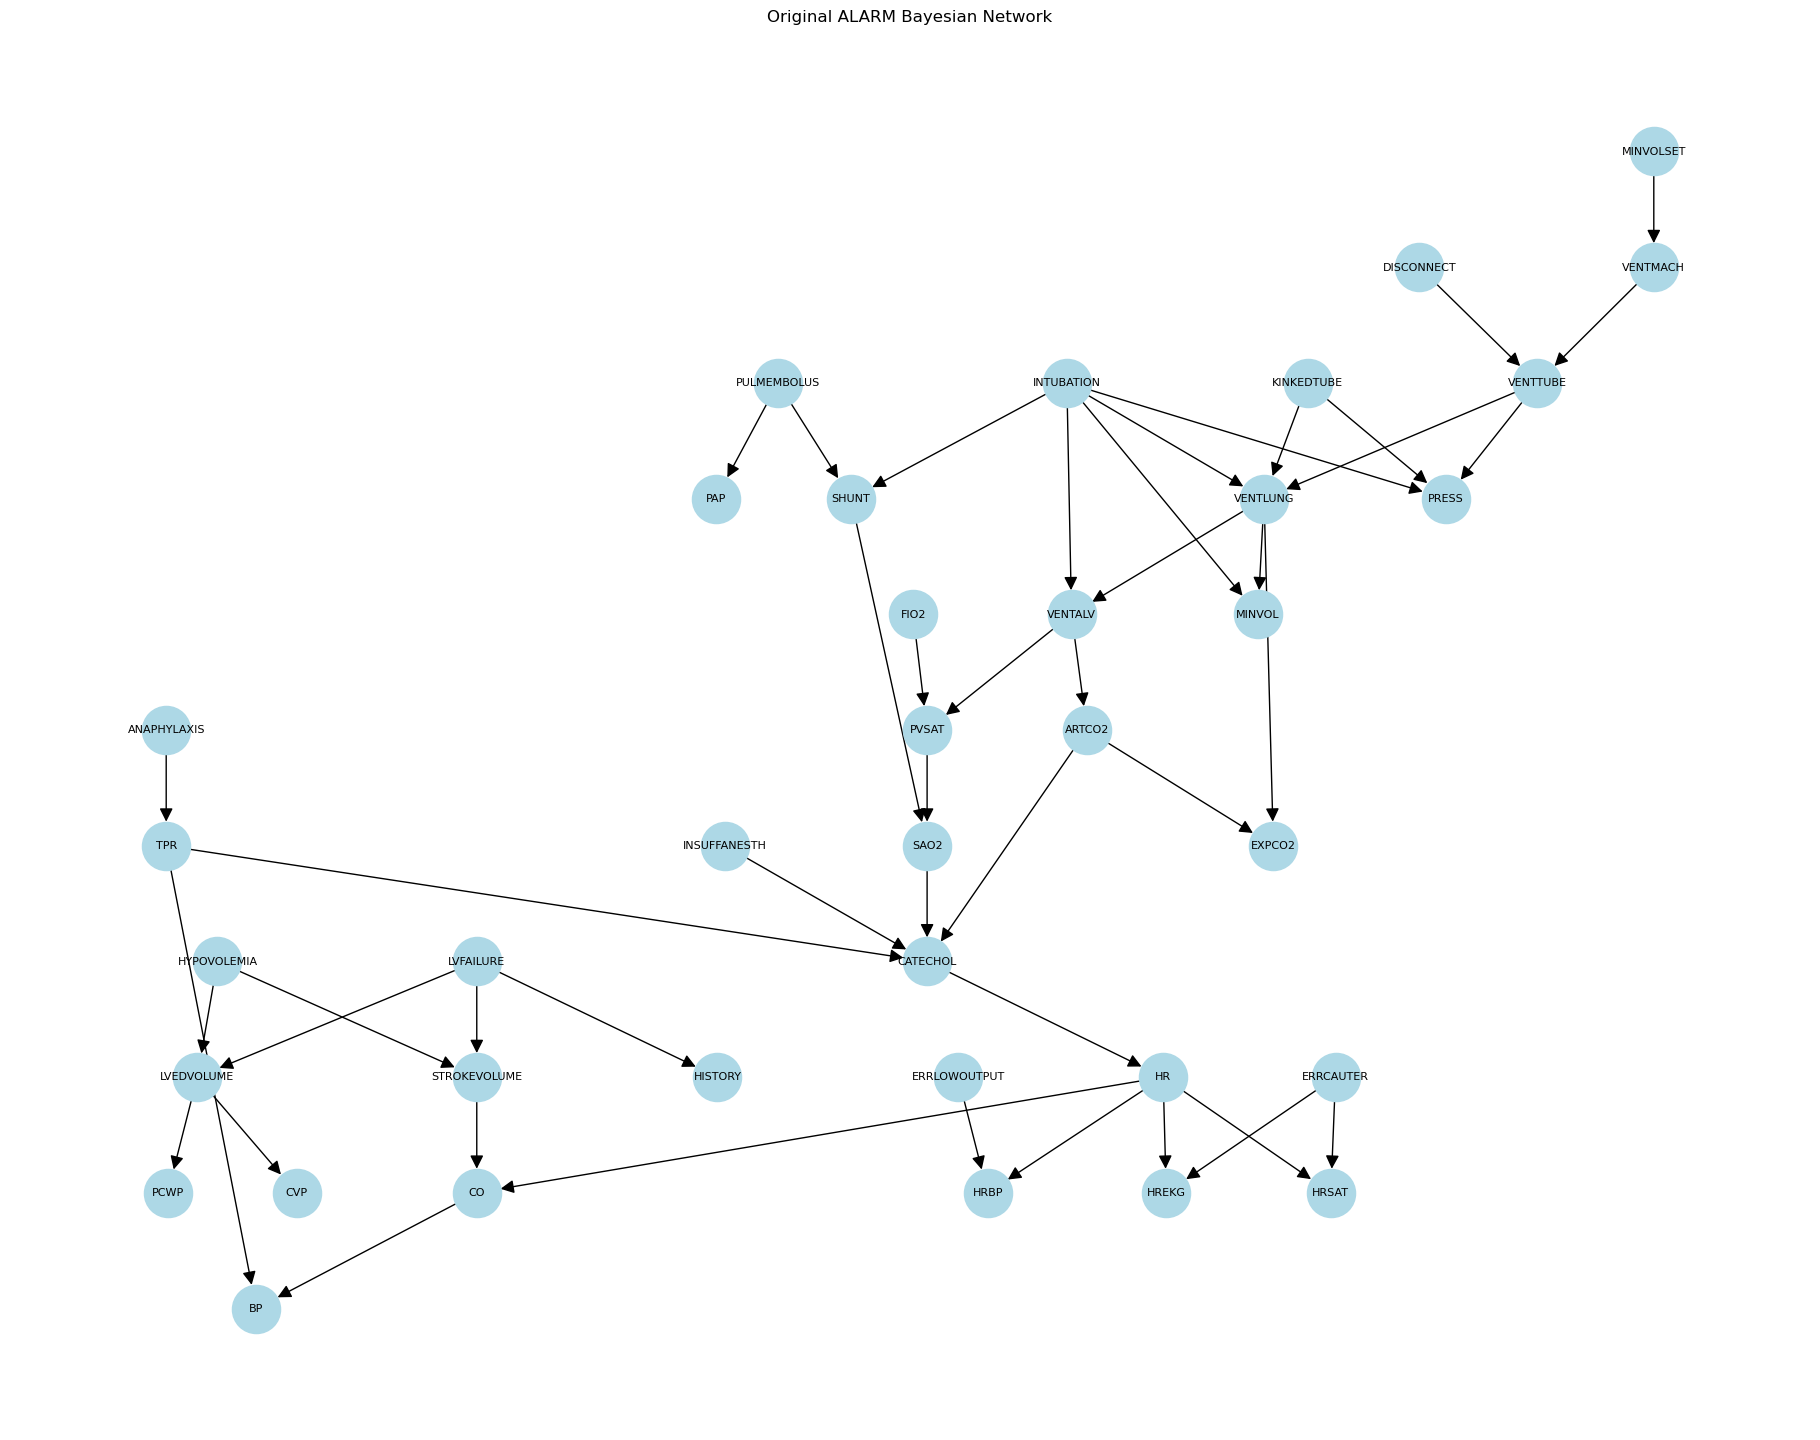

In [ ]:
def step_alarm_graph():
    og = load_alarm()
    print("Number of variables:", len(og.nodes()), "| Number of edges:", len(og.edges()))
    ensure_dir(DIRS["alarm"])
    G = nx.DiGraph(og.edges())
    nx.write_graphml(G, ORIGINAL_ALARM_GRAPHML)
    print("GraphML:", ORIGINAL_ALARM_GRAPHML)
    draw_network(G, layout(G), os.path.join(DIRS["alarm"], "Original_ALARM.png"),
                 "Original ALARM Bayesian Network")

run_step("2.1_alarm_graph", step_alarm_graph)

## 2.2 Sample the original ALARM (ground_truth_{n}.csv)

In [ ]:
def step_alarm_samples():
    sampler = BayesianModelSampling(load_alarm())
    ensure_dir(DIRS["gt_samples"])
    for n in ALARM_SAMPLE_SIZES:
        sampler.forward_sample(size=n, seed=SEED_ALARM_SAMPLES).to_csv(alarm_sample_csv(n), index=False)
        print("Saved:", alarm_sample_csv(n))

run_step("2.2_alarm_samples", step_alarm_samples)

## 2.3 Mutual-information matrices

In [ ]:
def step_mi():
    ensure_dir(DIRS["mi"])
    for n in ALARM_SAMPLE_SIZES:
        df = pd.read_csv(alarm_sample_csv(n))
        cols = df.columns
        mi = pd.DataFrame(np.zeros((len(cols), len(cols))), index=cols, columns=cols)
        for a in cols:
            for b in cols:
                mi.loc[a, b] = mutual_info_score(df[a], df[b])
        mi.to_csv(mi_csv(n))
        print("Saved:", mi_csv(n))

run_step("2.3_mi", step_mi)

## 2.4 Ground-truth trees: MI maximum weight spanning trees

One loop replaces the ten copies of this cell (one per sample size) in the original GT notebook.

[Saved graph from the original run: '1. GT generations' notebook, cell 11]


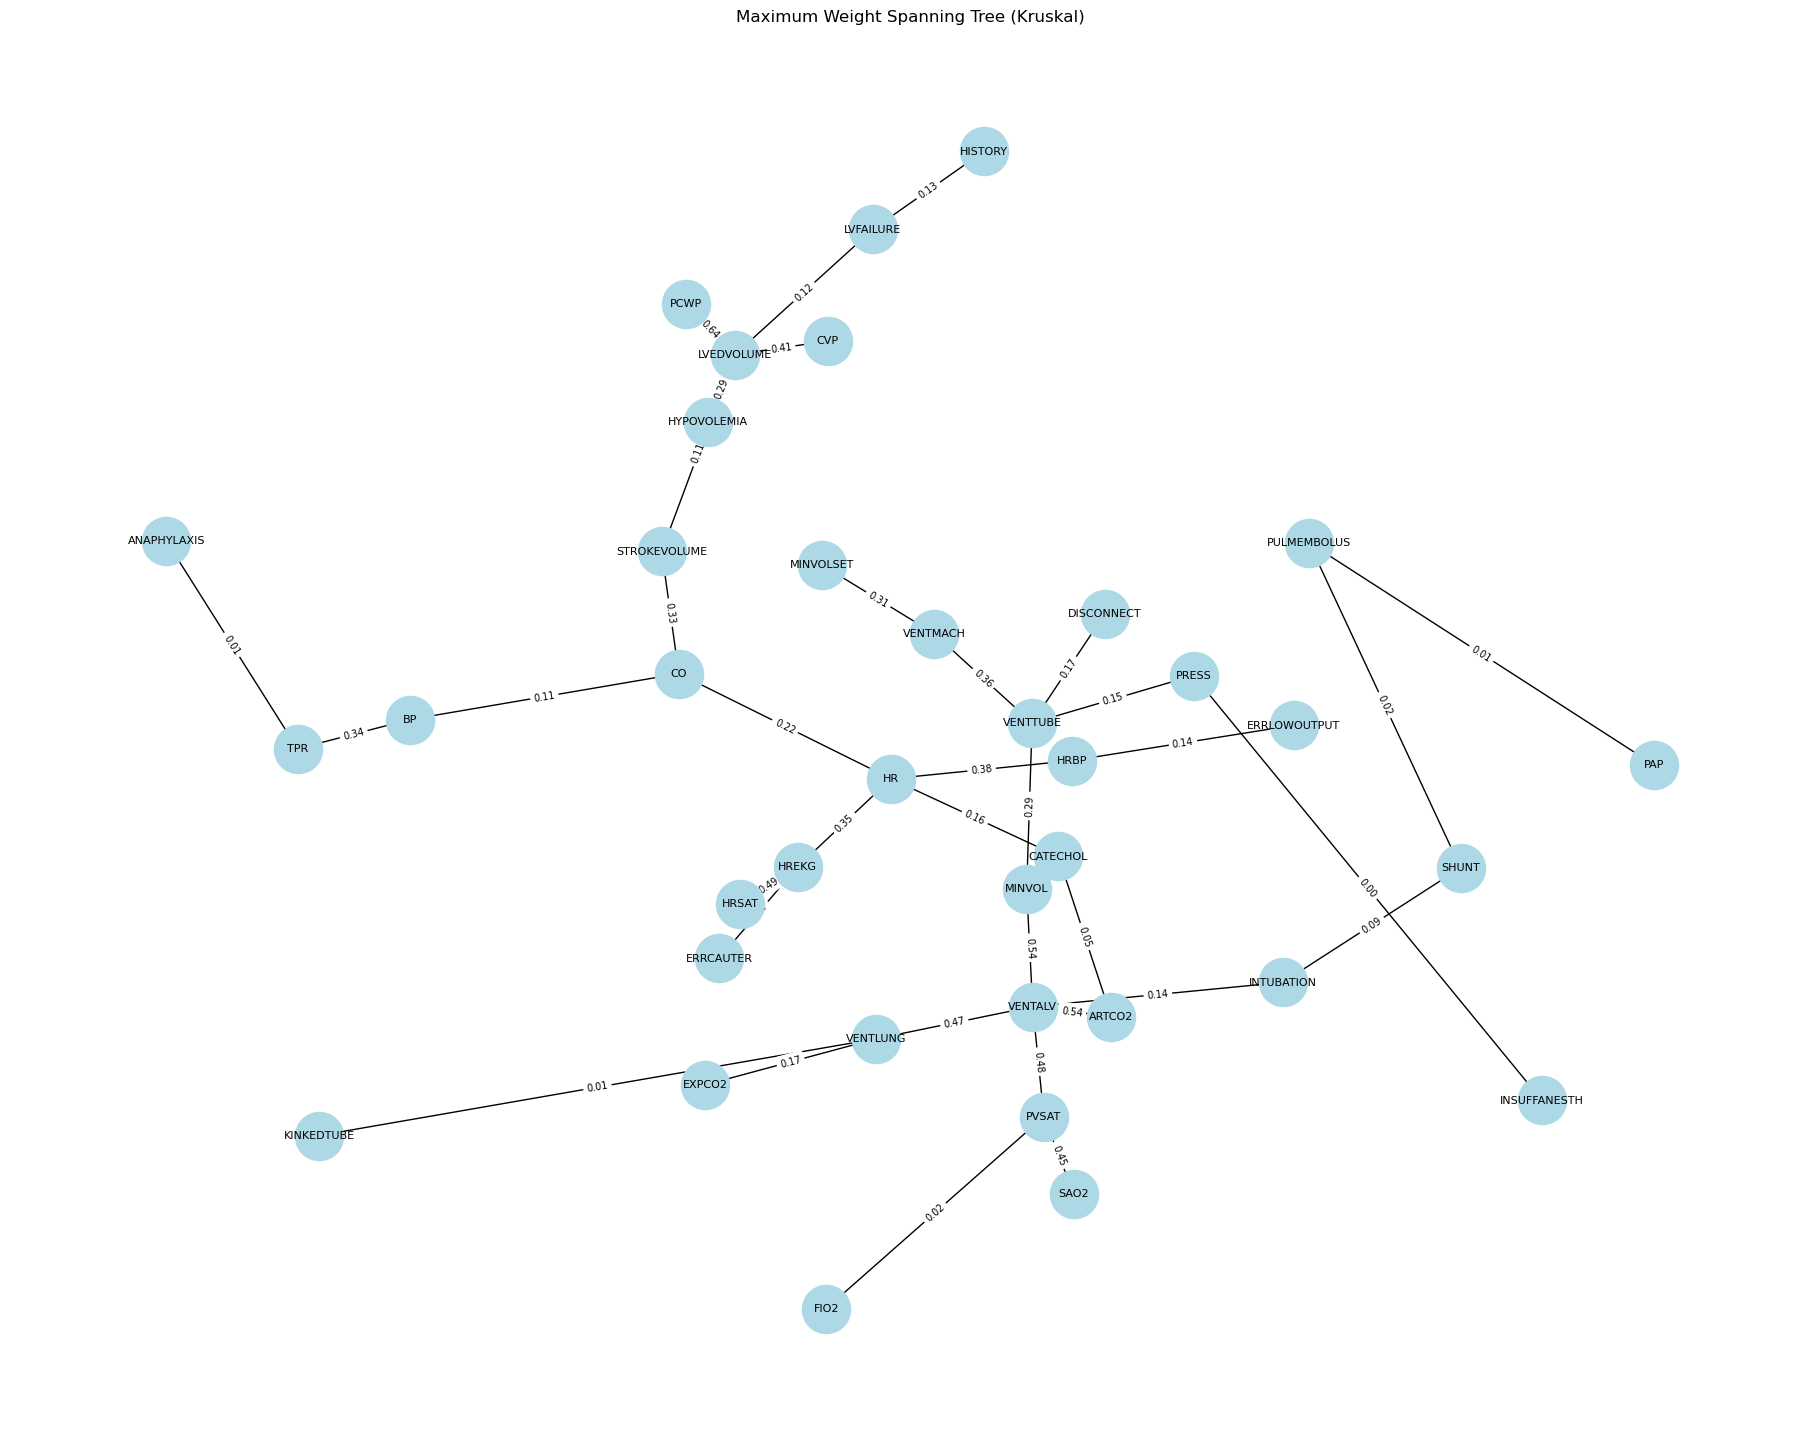

[Saved graph from the original run: '1. GT generations' notebook, cell 13]


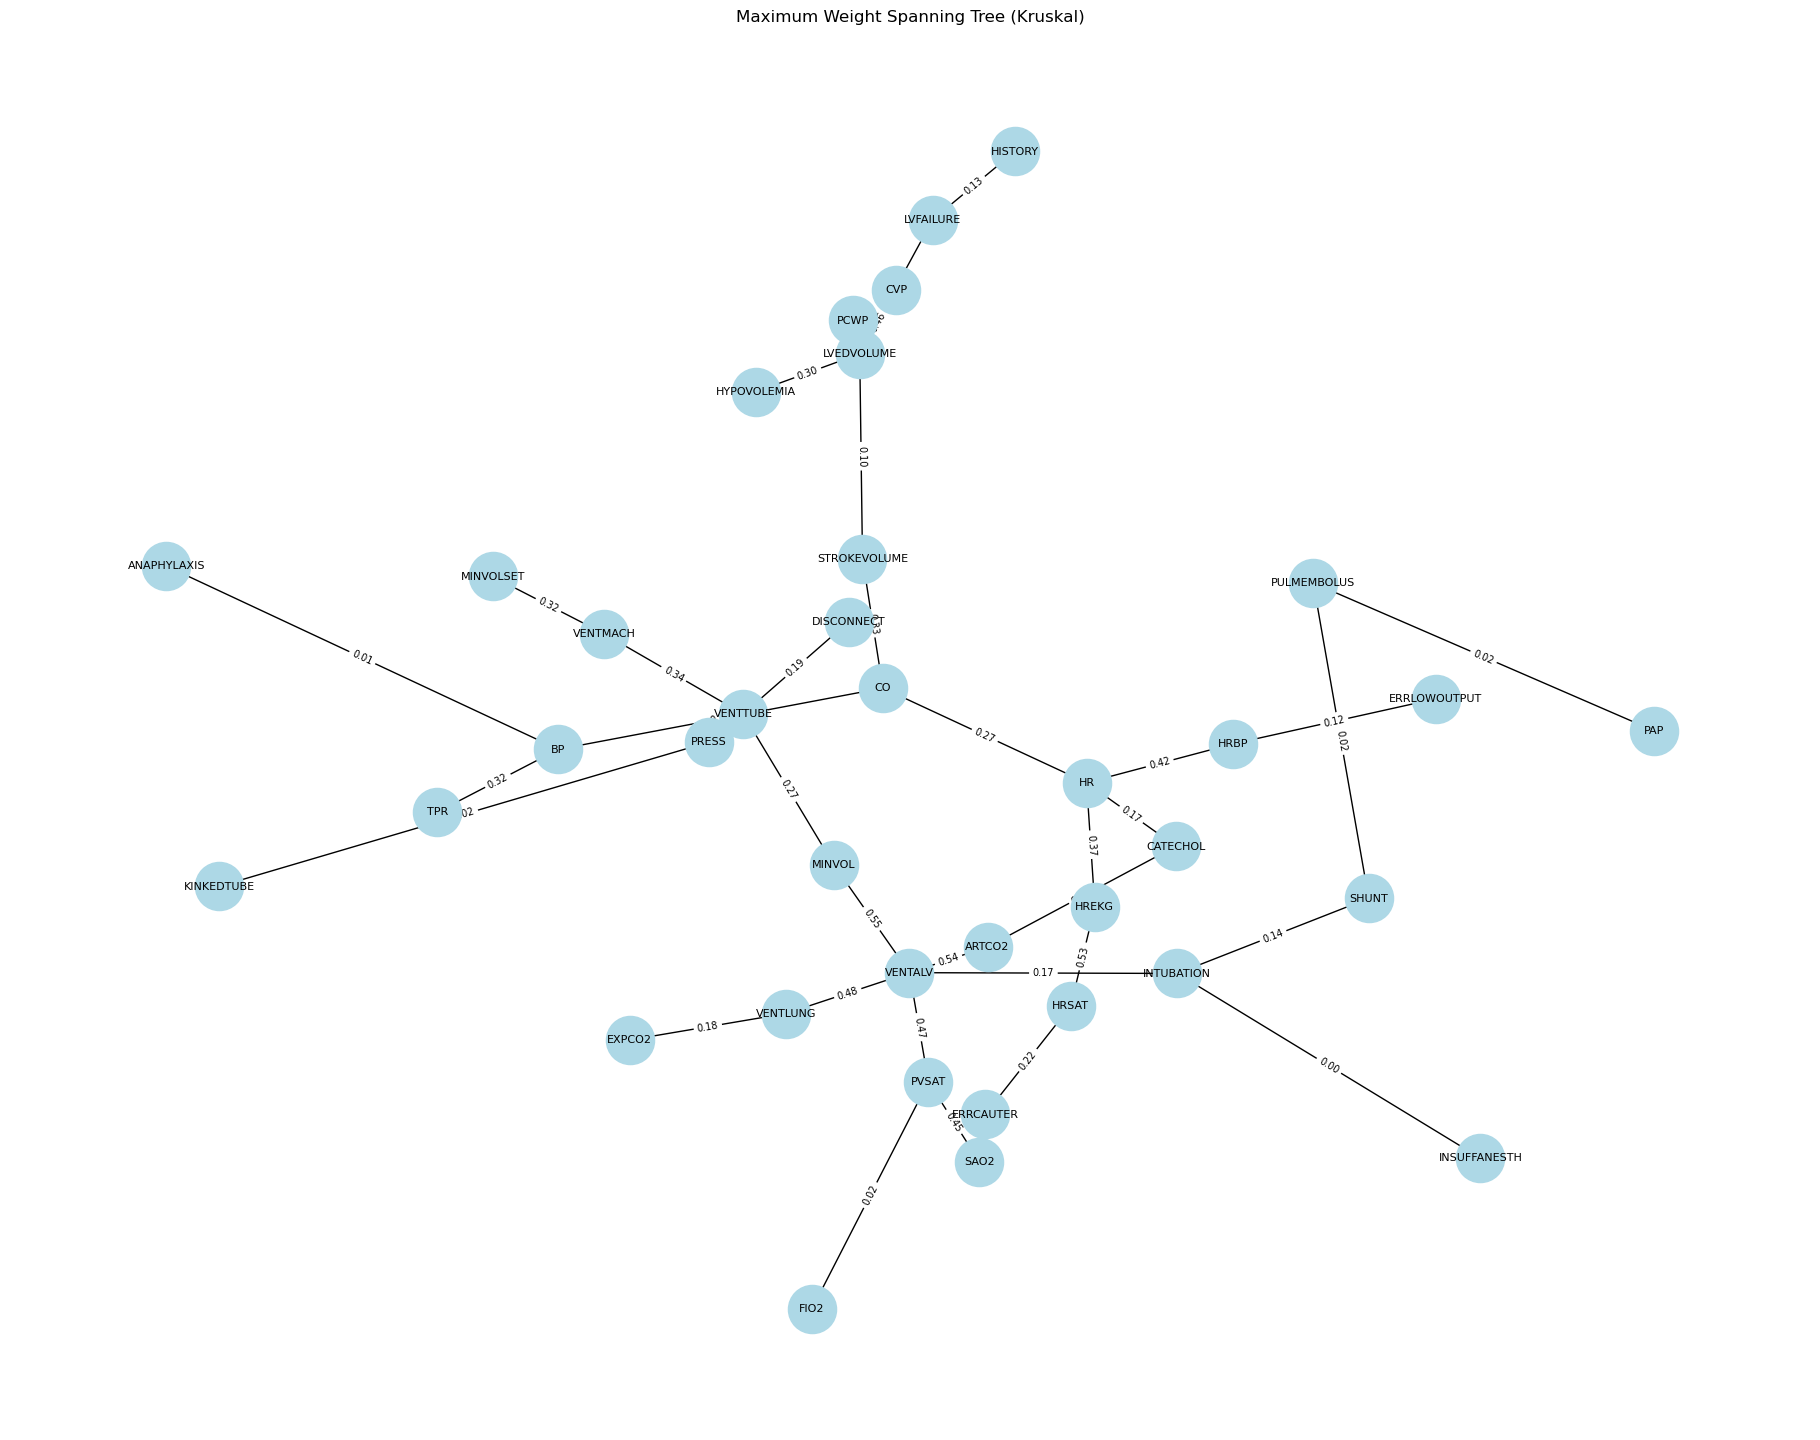

[Saved graph from the original run: '1. GT generations' notebook, cell 15]


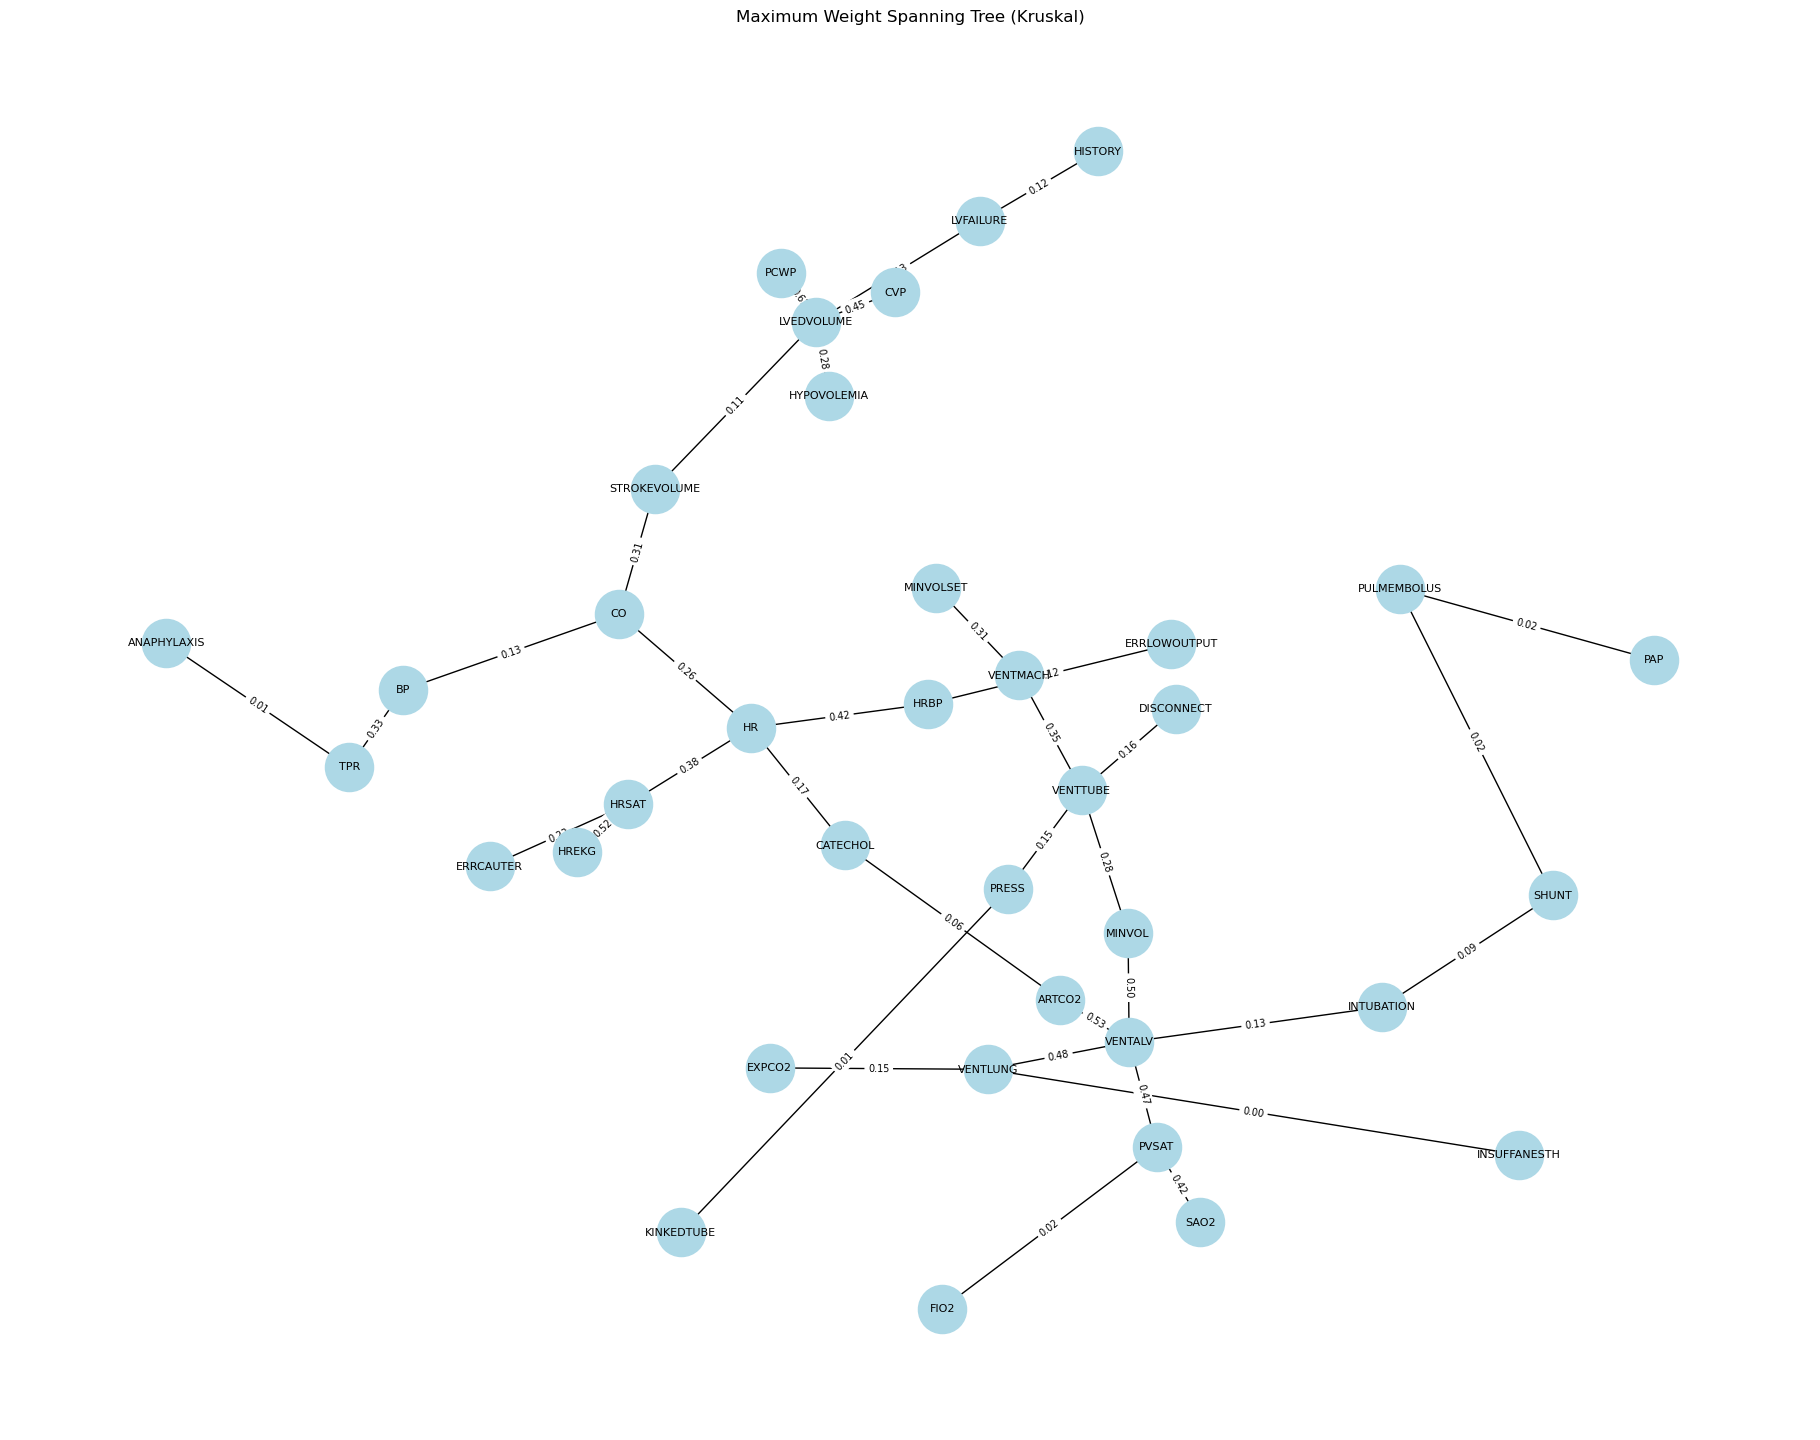

[Saved graph from the original run: '1. GT generations' notebook, cell 17]


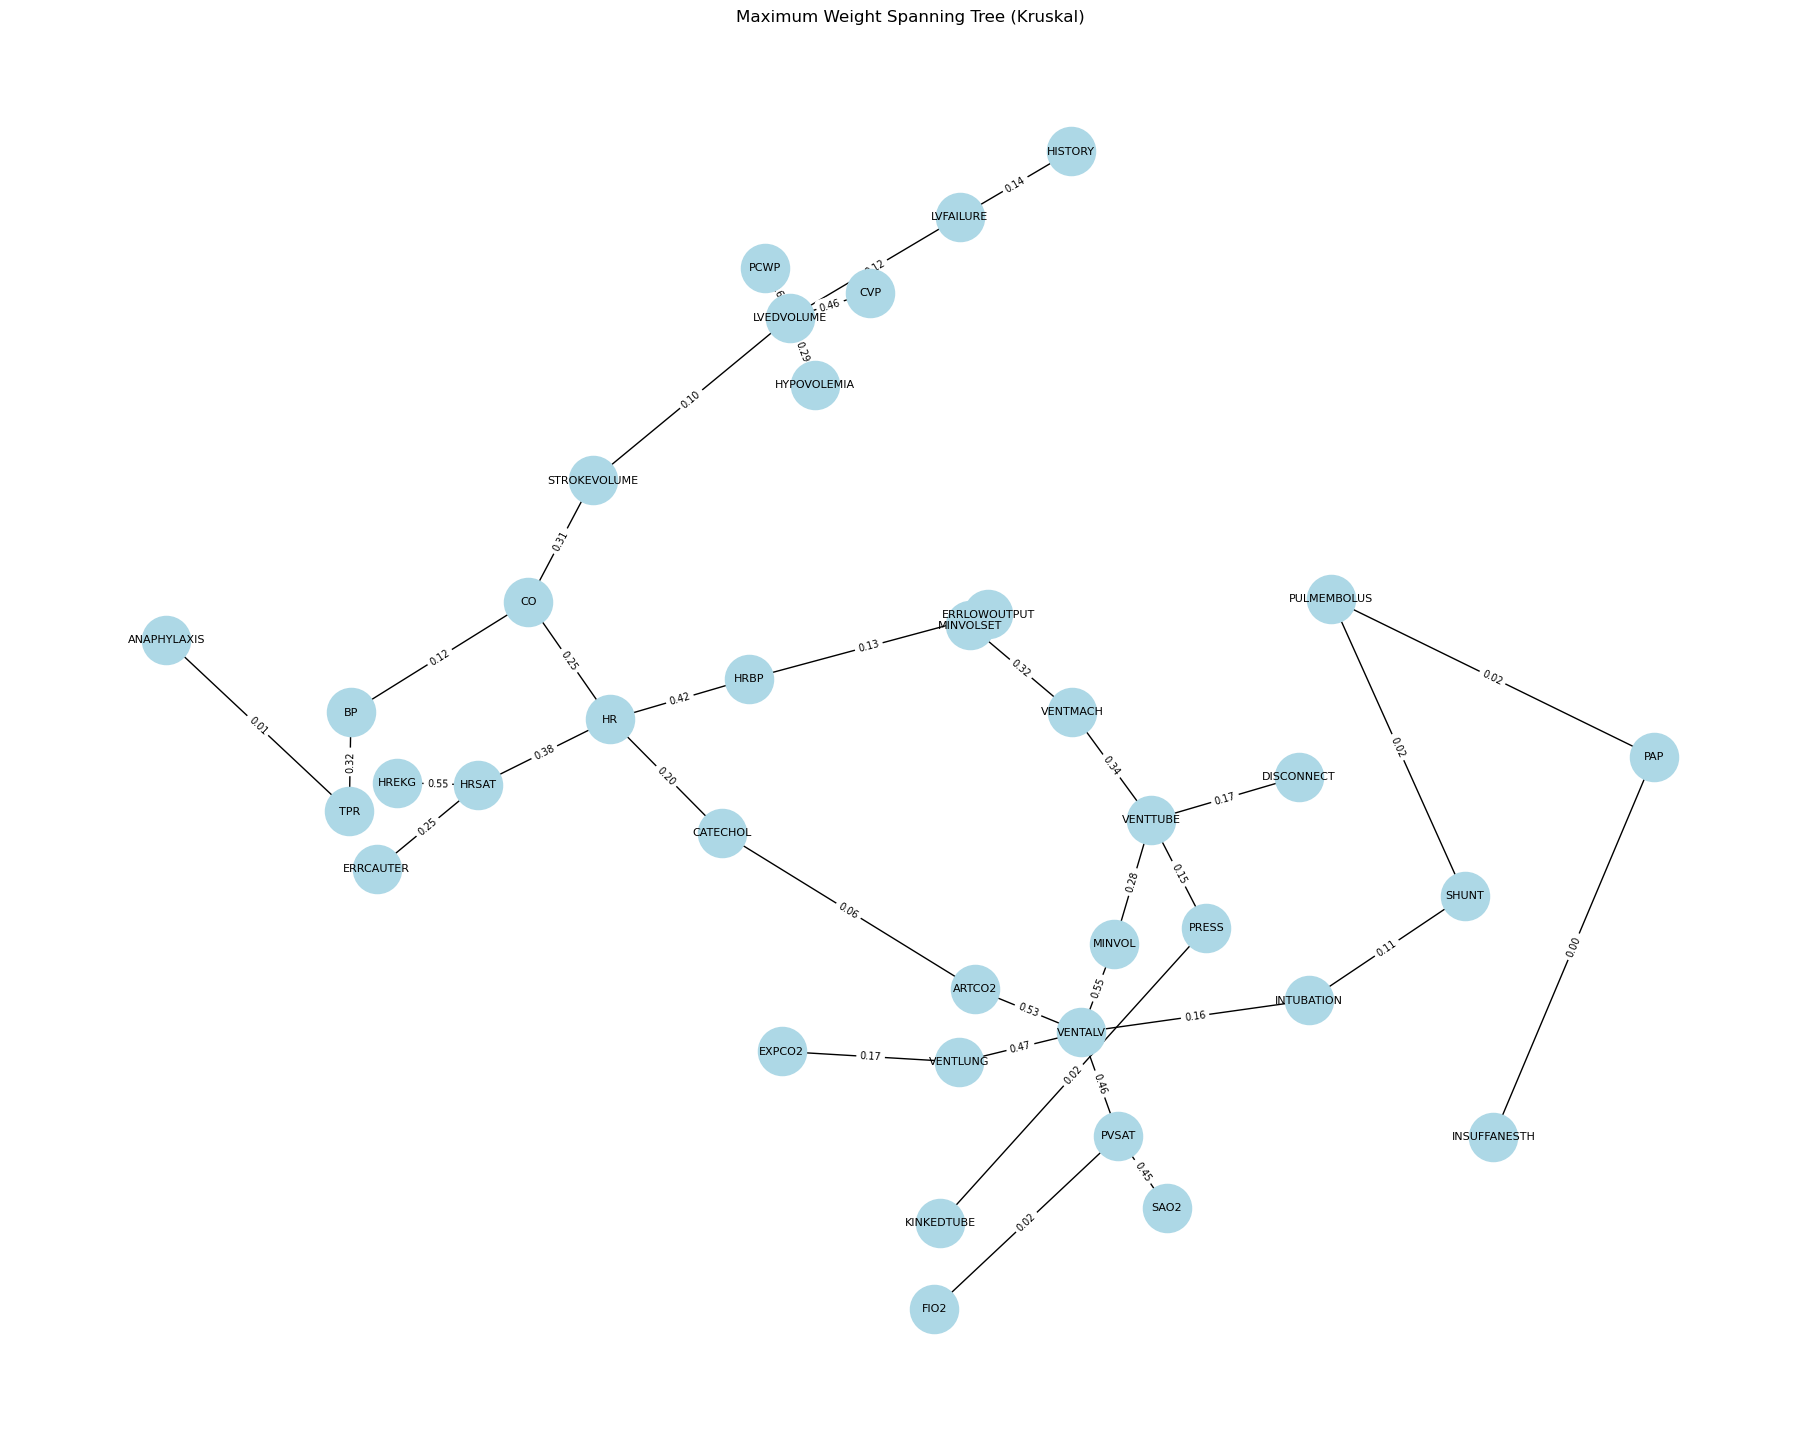

[Saved graph from the original run: '1. GT generations' notebook, cell 19]


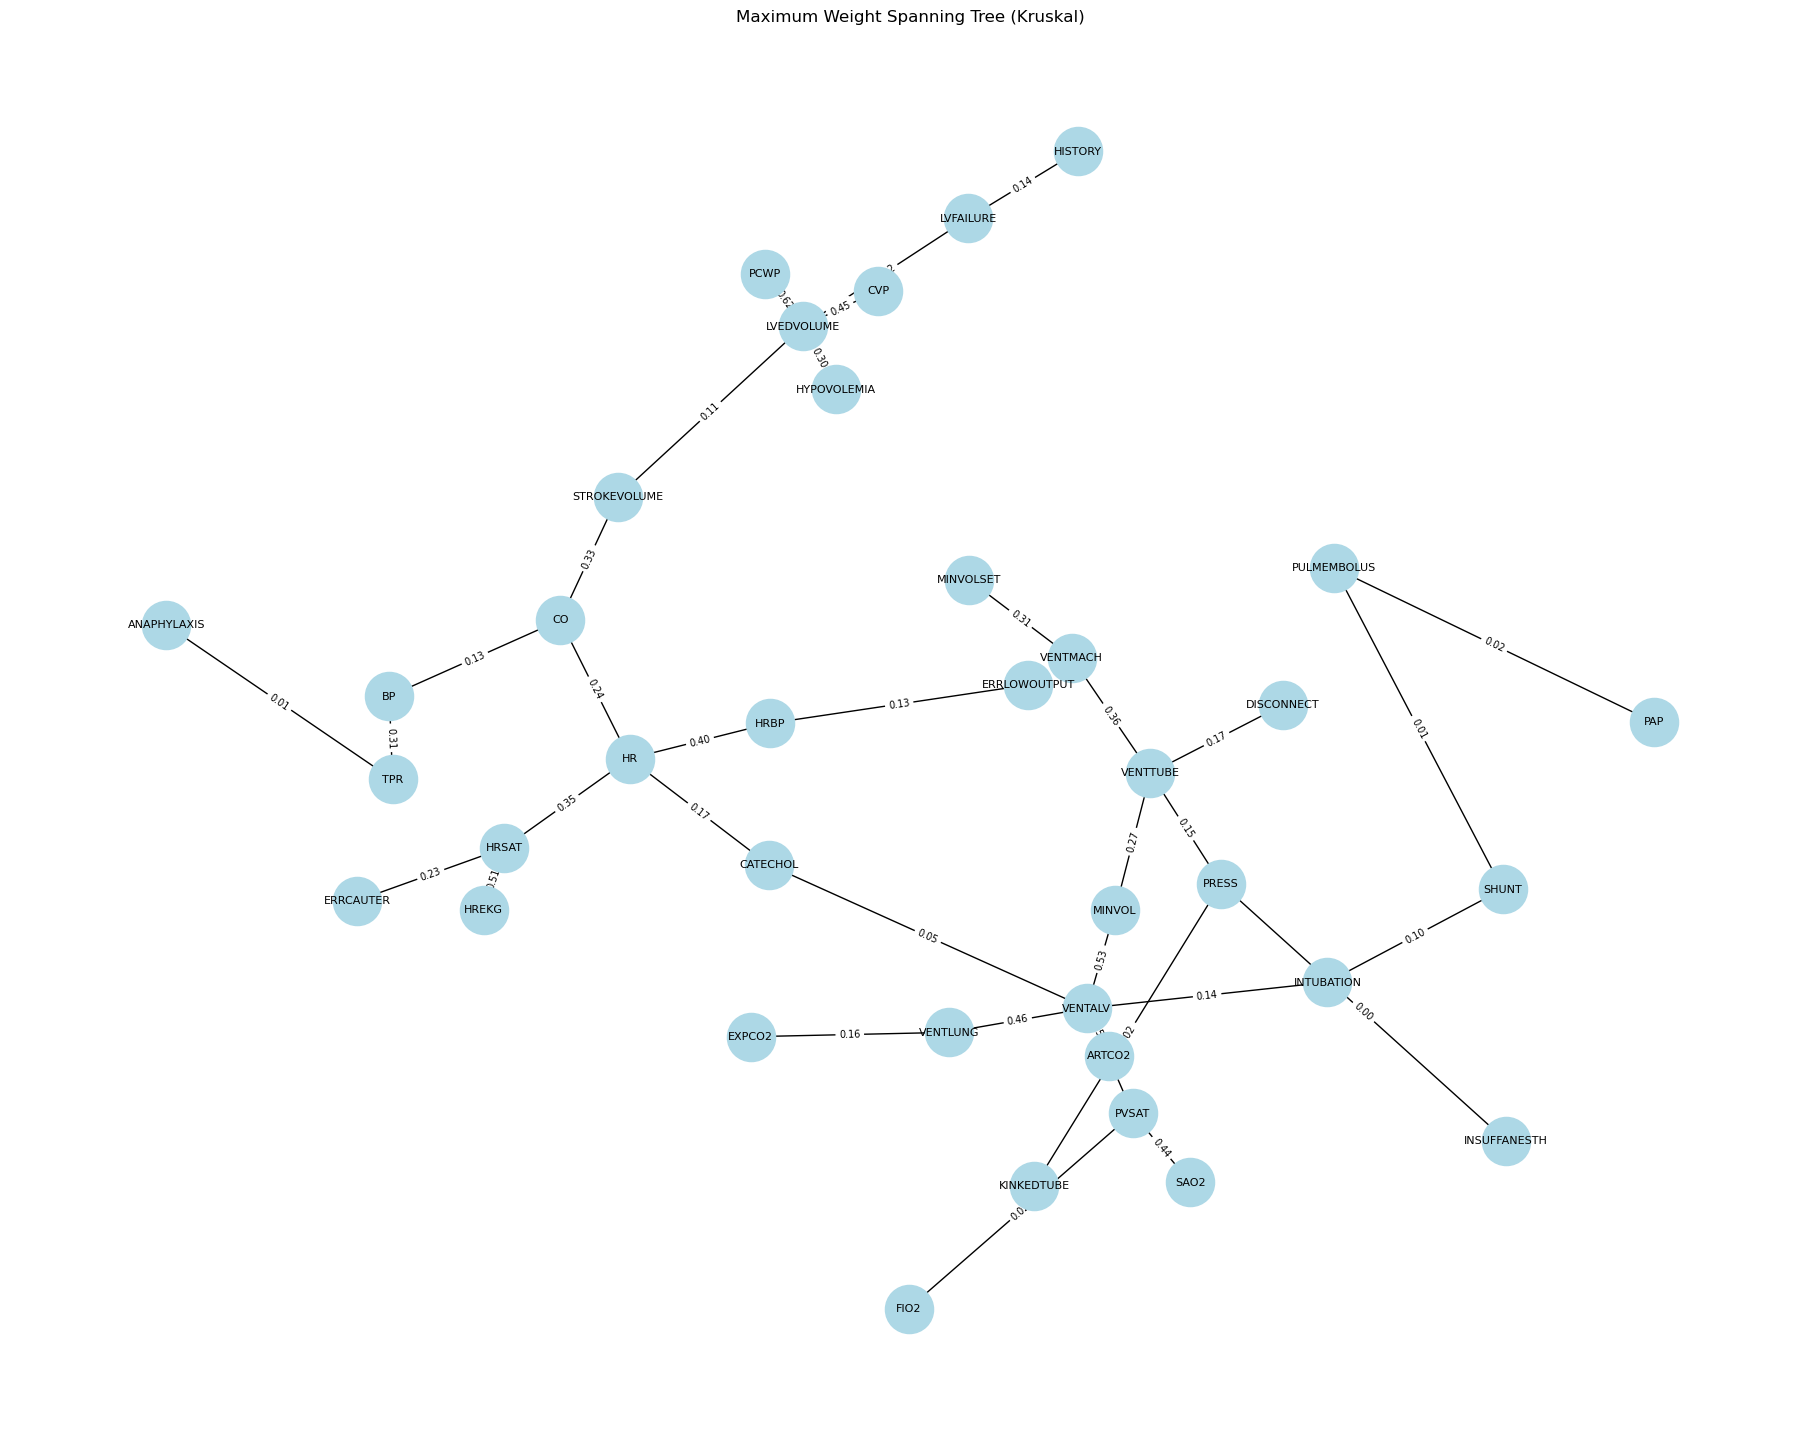

[Saved graph from the original run: '1. GT generations' notebook, cell 21]


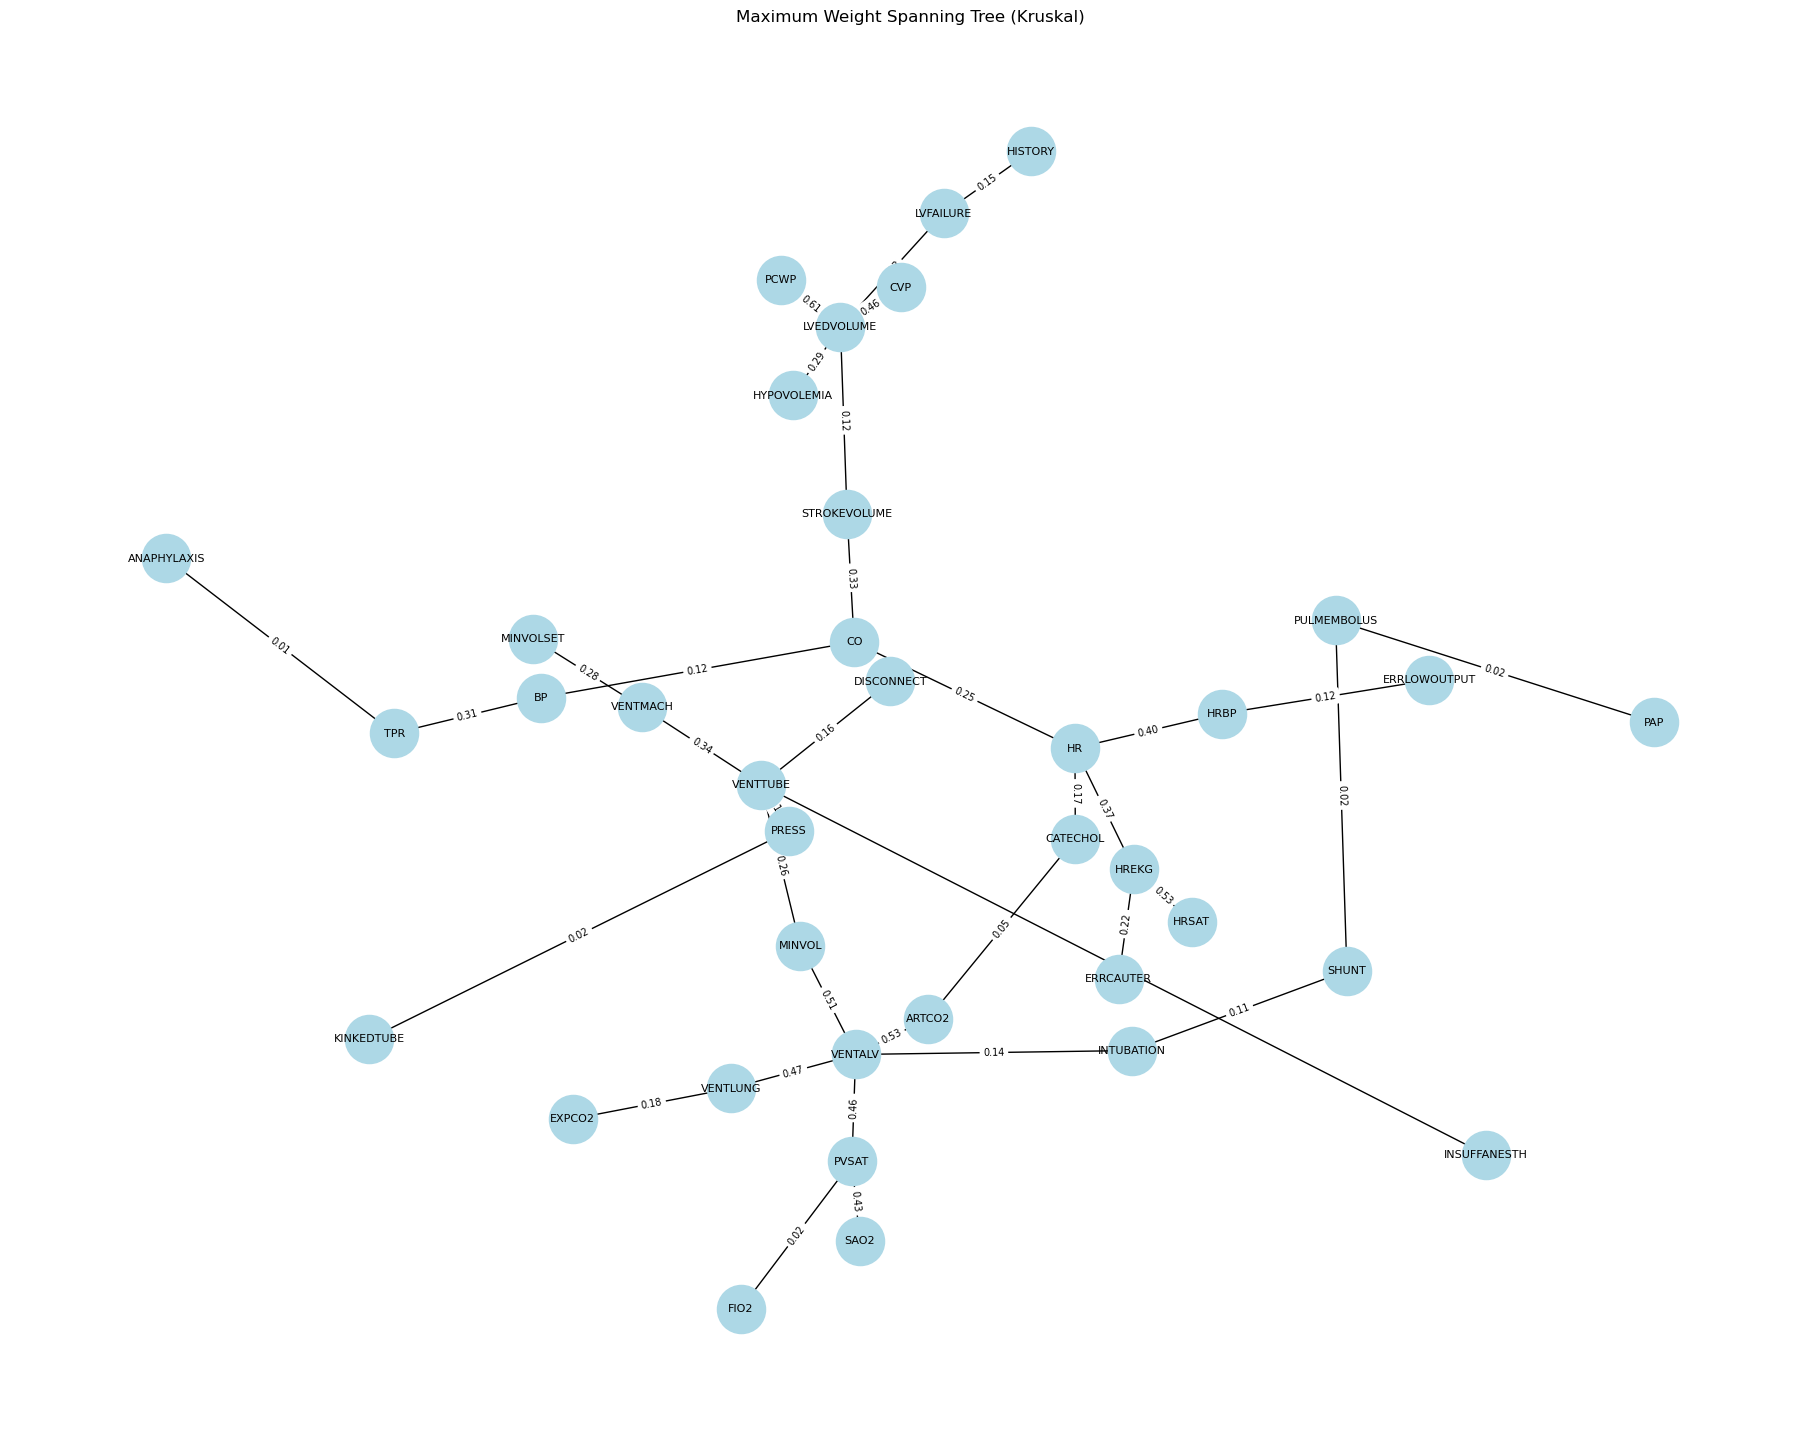

[Saved graph from the original run: '1. GT generations' notebook, cell 23]


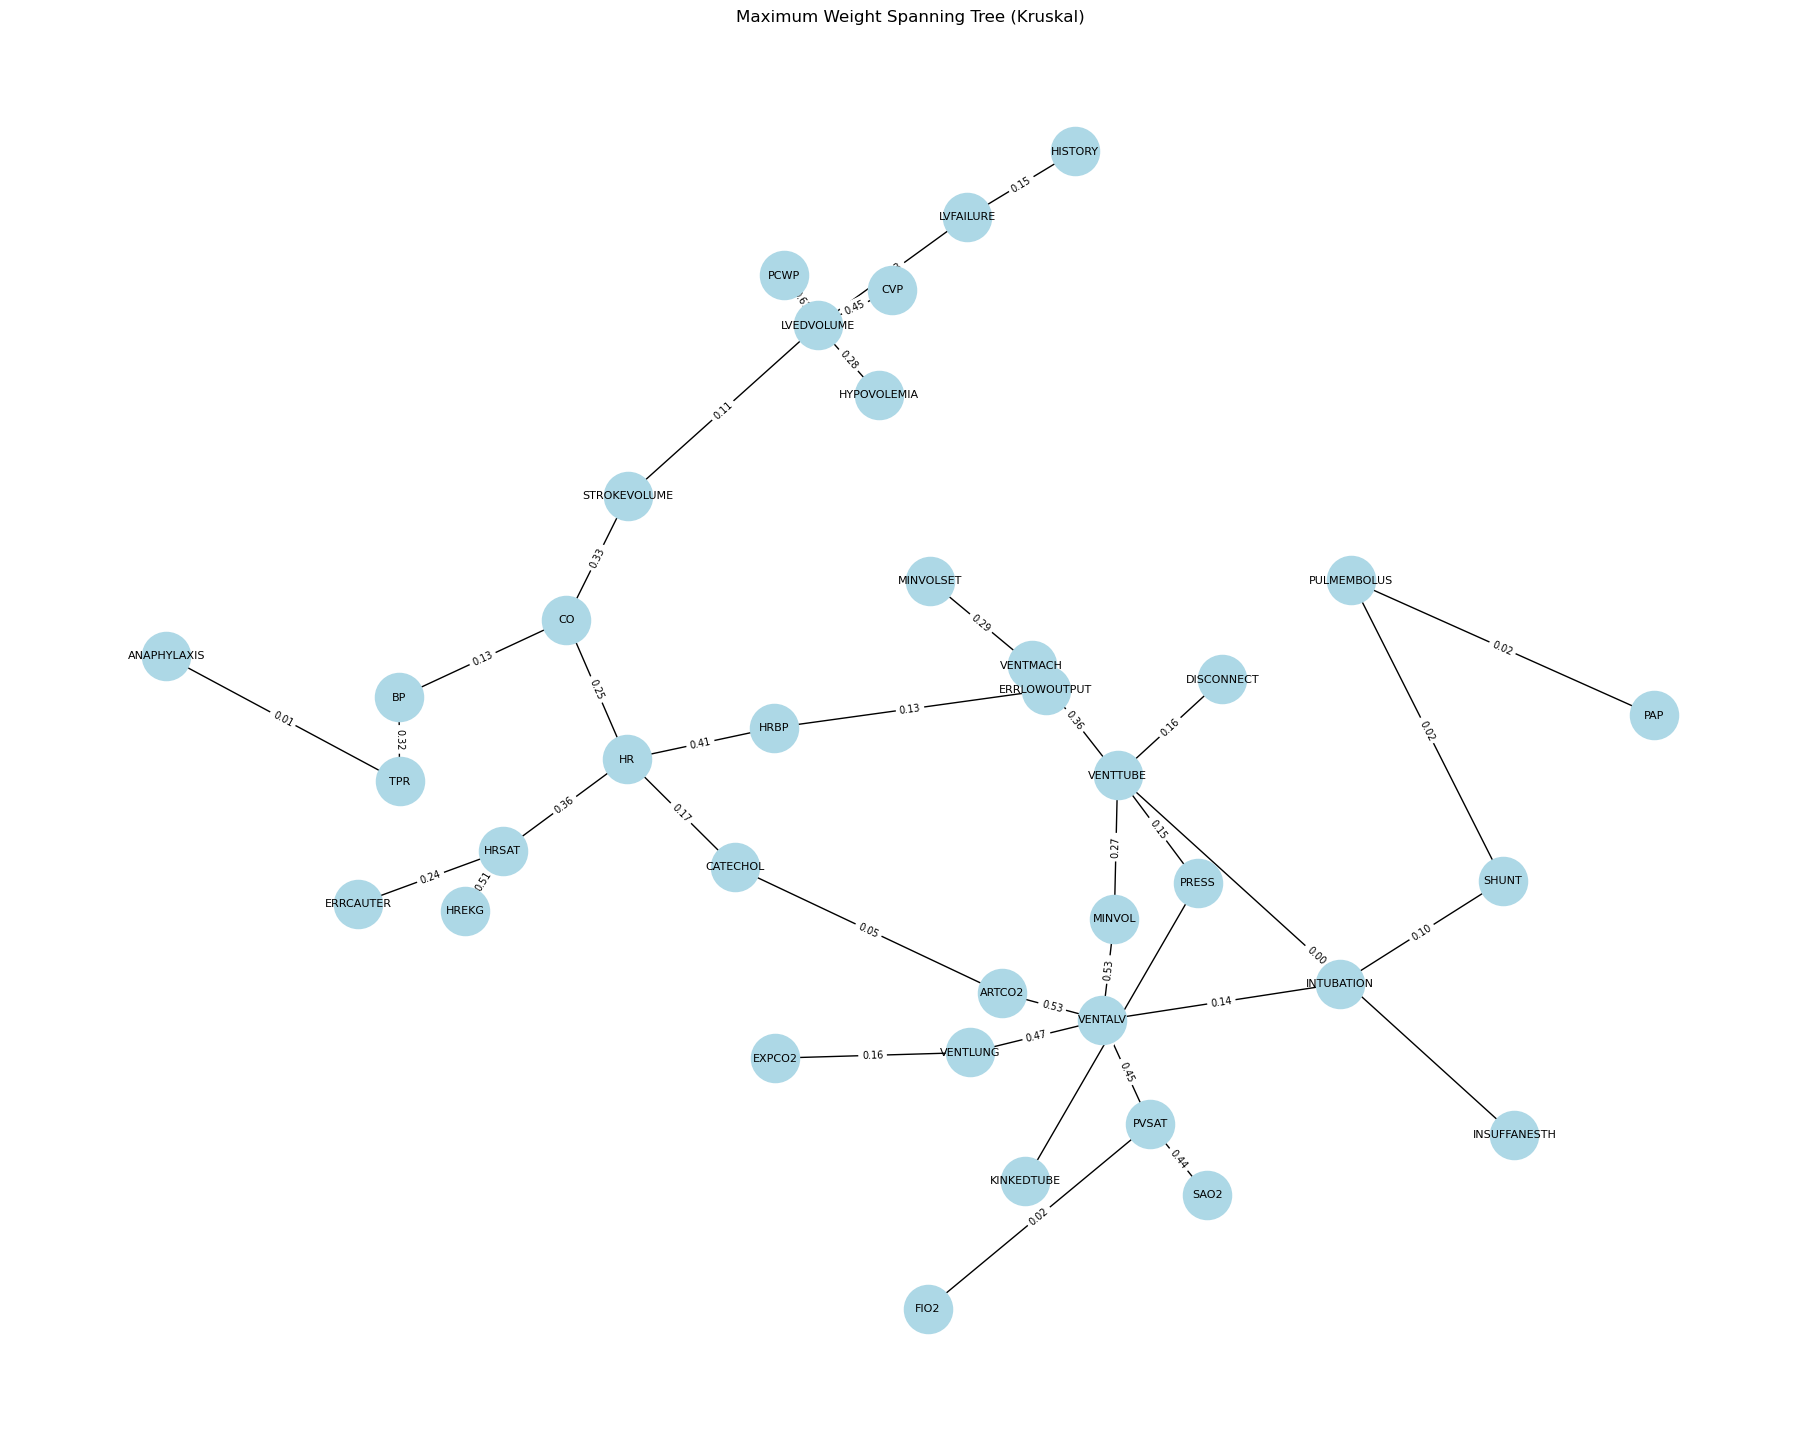

[Saved graph from the original run: '1. GT generations' notebook, cell 25]


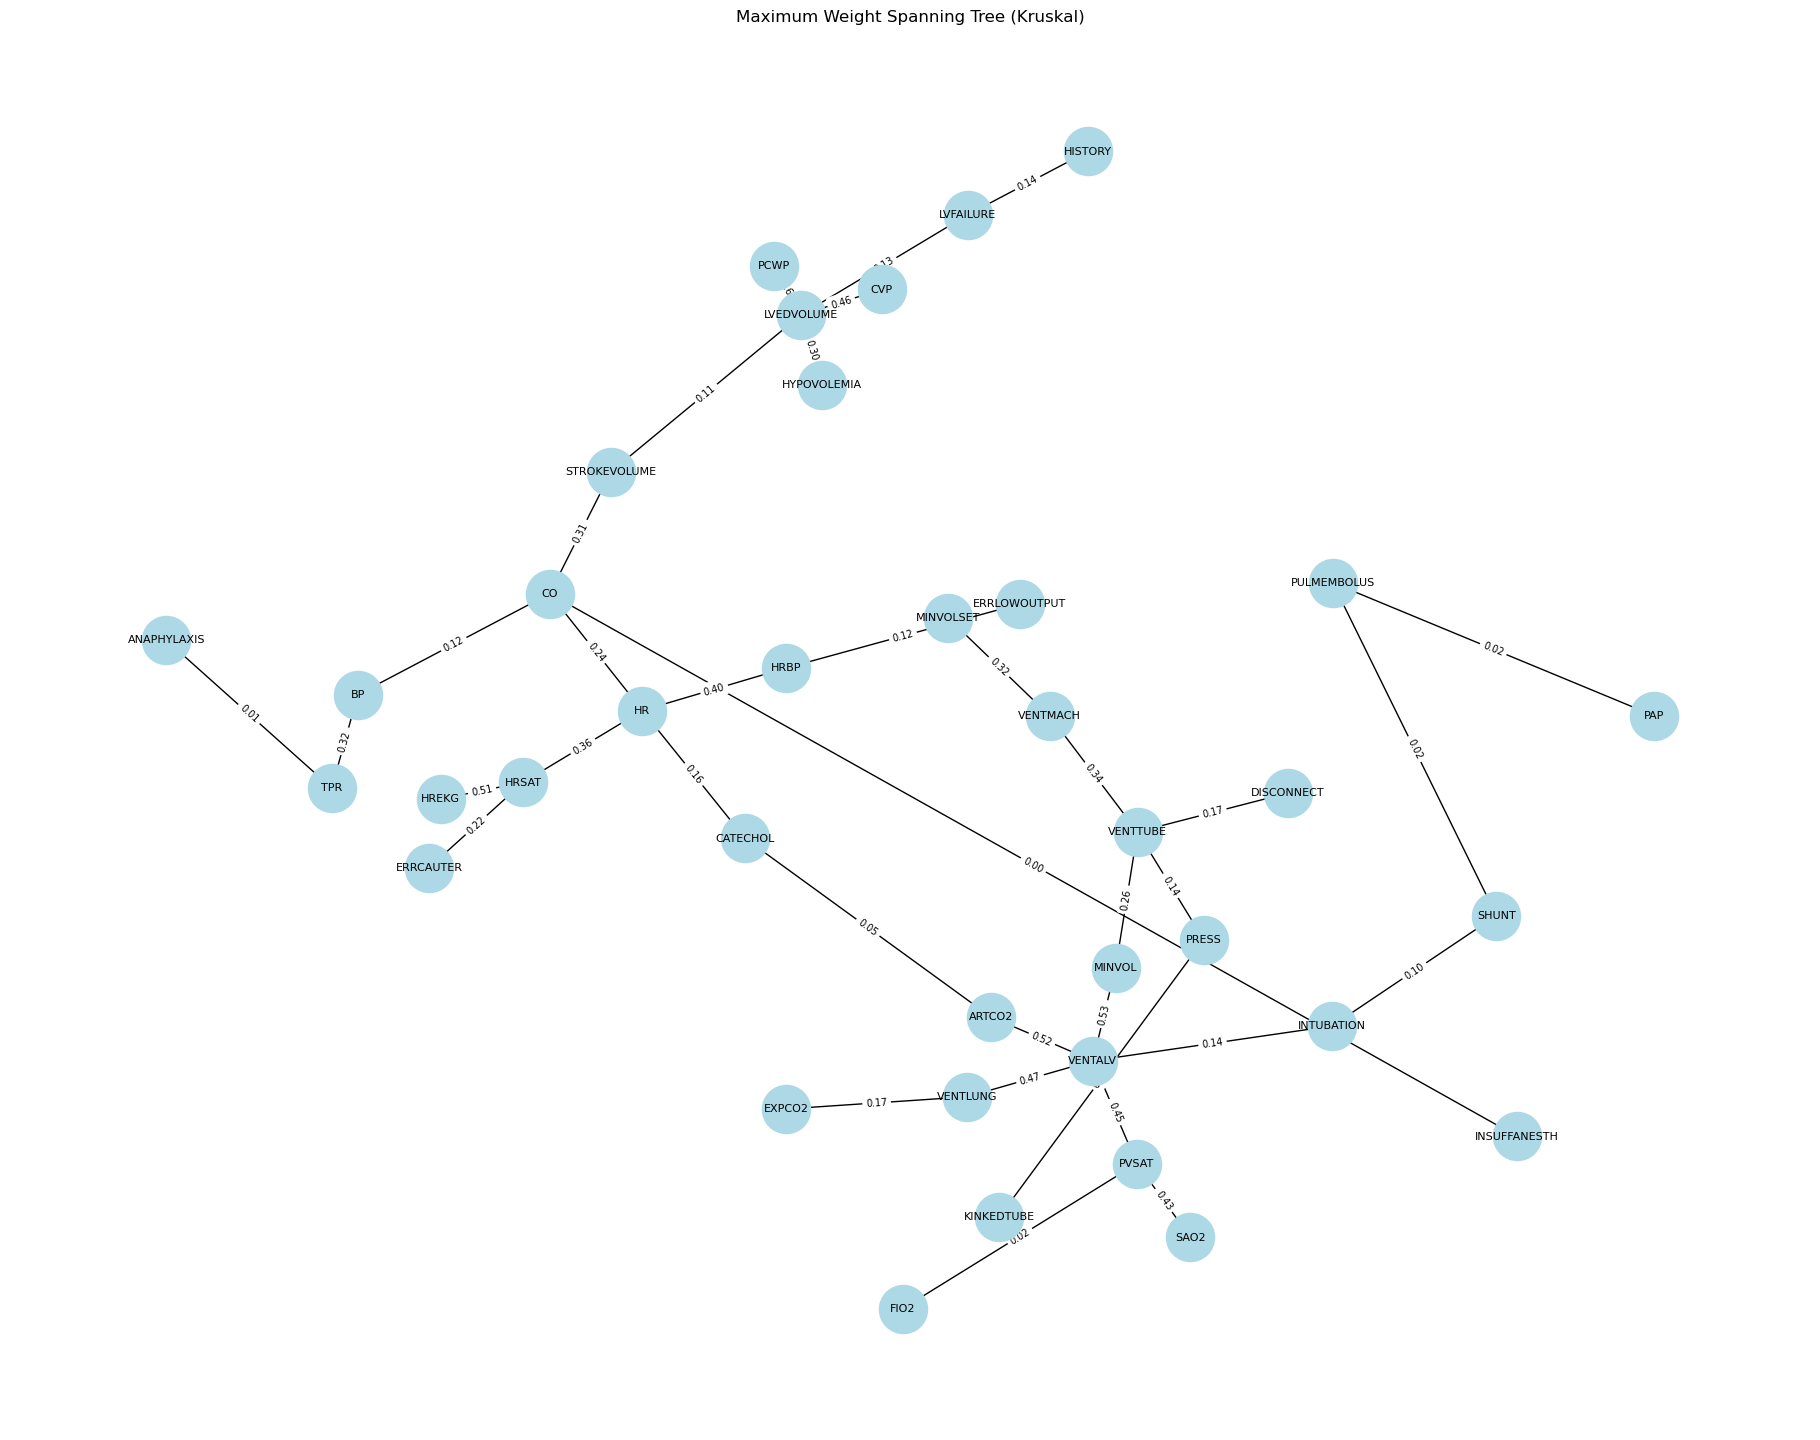

[Saved graph from the original run: '1. GT generations' notebook, cell 27]


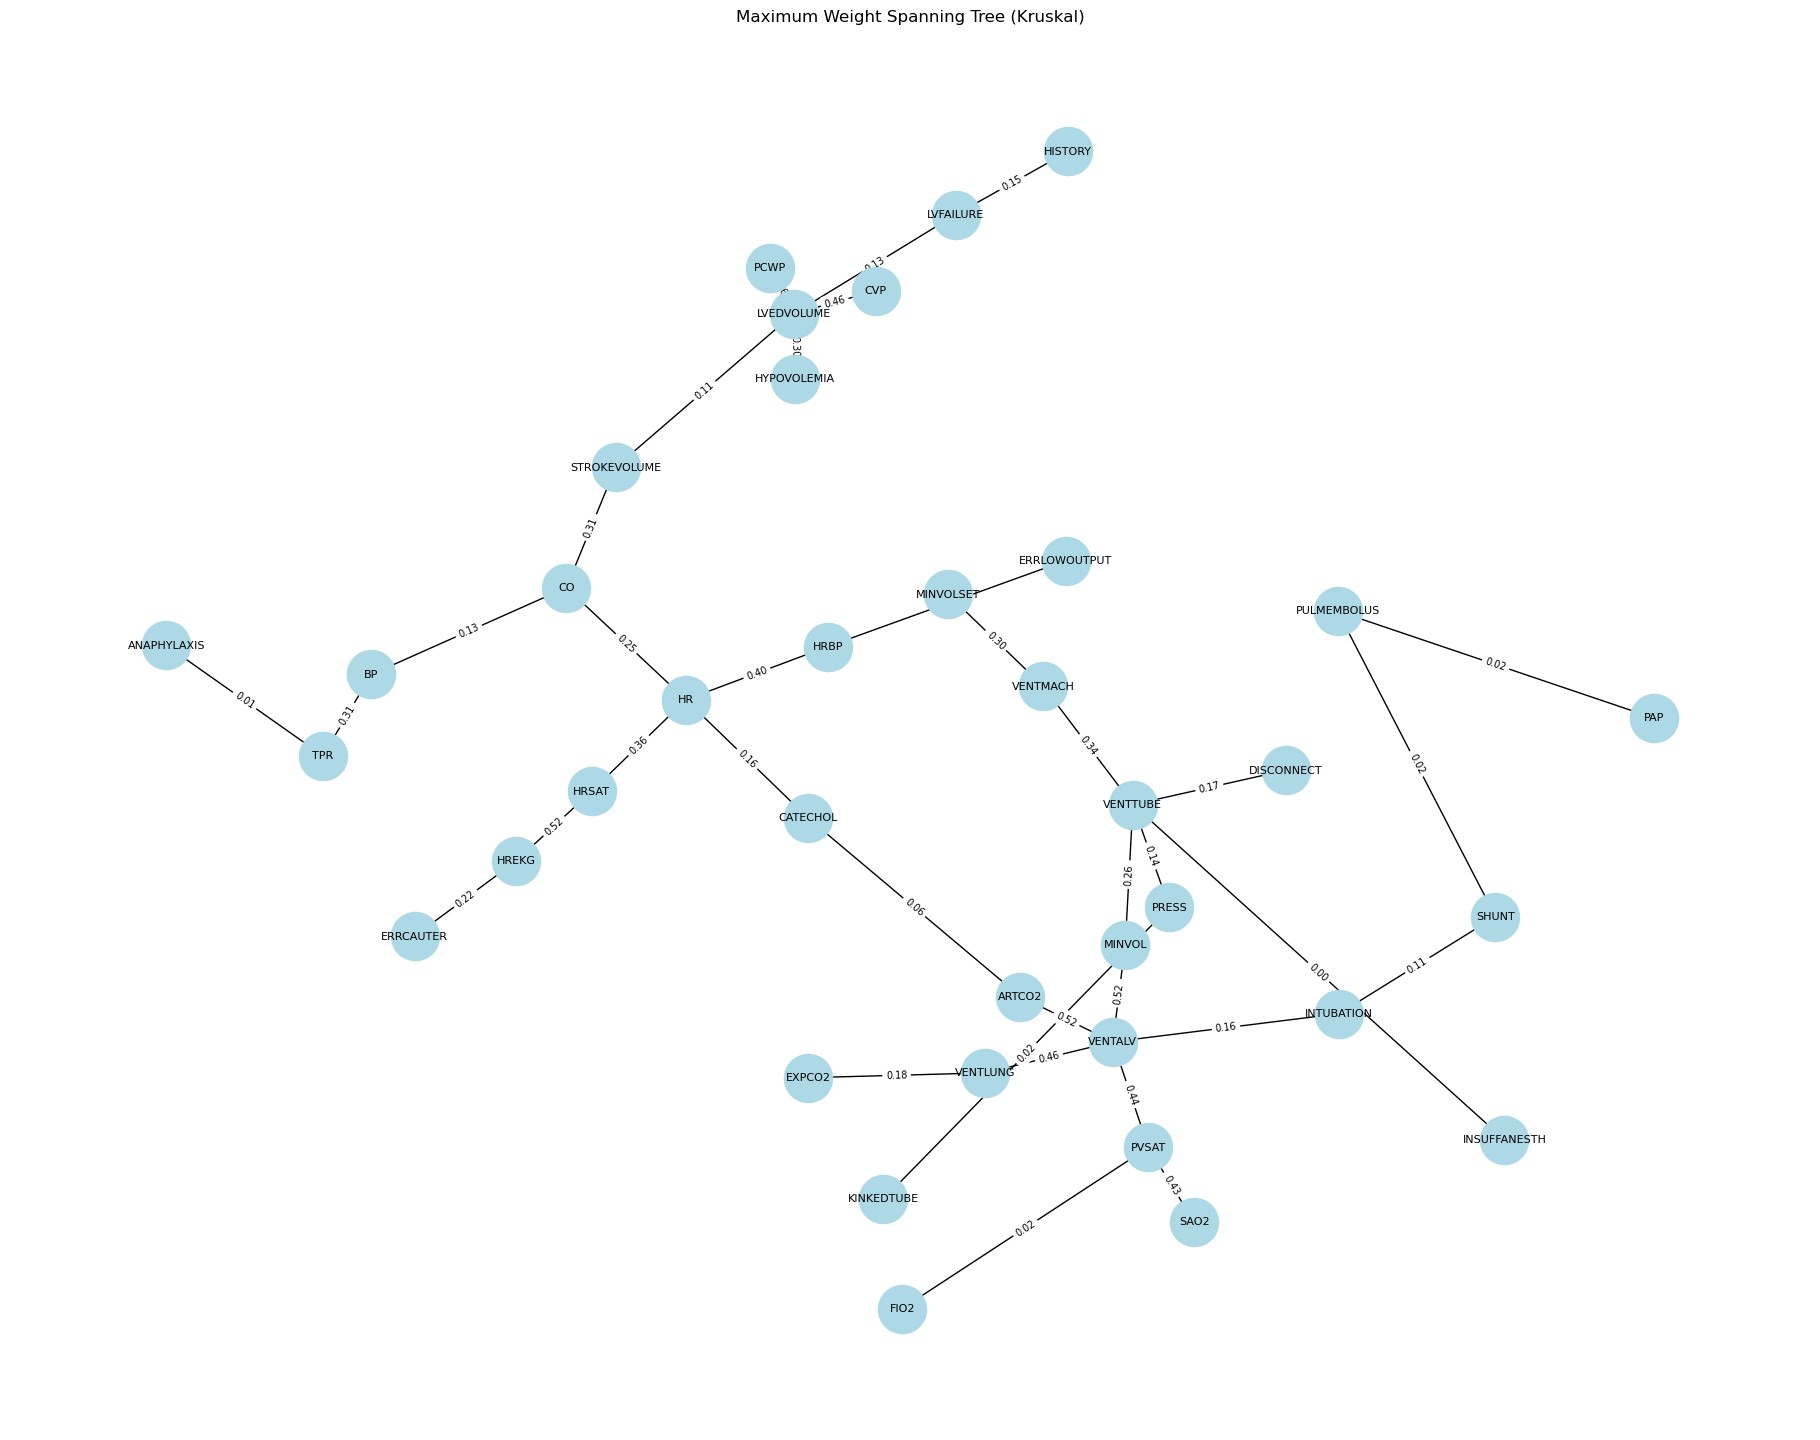

[Saved graph from the original run: '1. GT generations' notebook, cell 29]


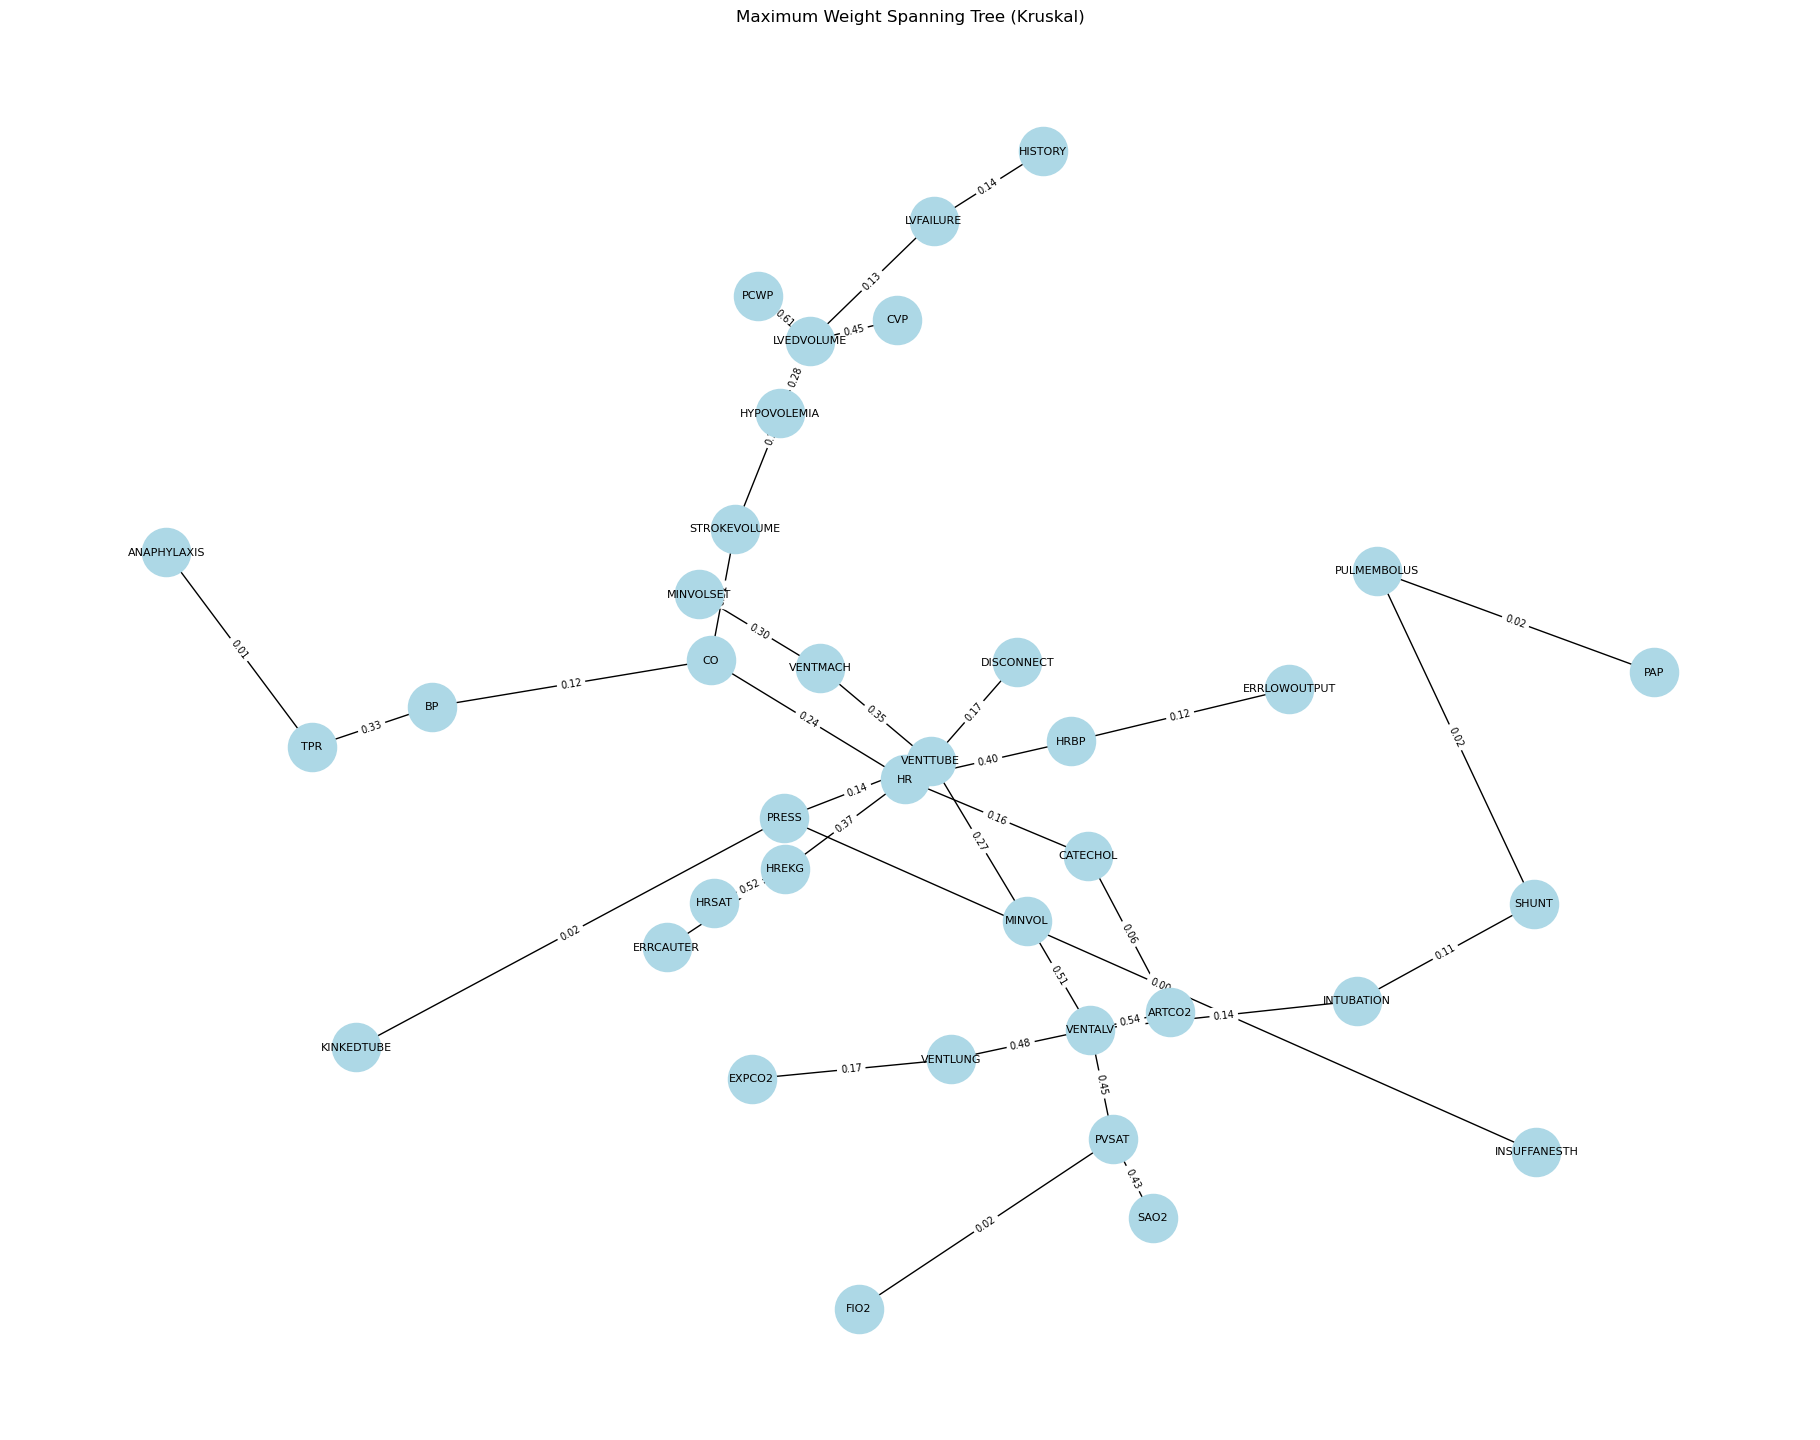

In [ ]:
def step_mi_trees():
    ensure_dir(DIRS["gt_trees"])
    for n in ALARM_SAMPLE_SIZES:
        mi = pd.read_csv(mi_csv(n), index_col=0).apply(pd.to_numeric)
        G = nx.Graph()
        for a in mi.index:
            for b in mi.columns:
                if a < b:
                    G.add_edge(a, b, weight=mi.loc[a, b])
        mst = nx.maximum_spanning_tree(G, algorithm="kruskal")
        nx.write_graphml(mst, mst_graphml(n))
        print("MST saved:", mst_graphml(n))
        draw_network(mst, nx.spring_layout(mst, seed=42), os.path.join(DIRS["gt_trees"], f"MST_{n}.png"),
                     f"Maximum Weight Spanning Tree (Kruskal) - {n} samples", edge_label_attr="weight")

run_step("2.4_mi_trees", step_mi_trees)

## 2.5 Orient the trees (directed ground truths)

Each tree is oriented away from a random root, with `random.seed(42)` reset for every tree, exactly as in the original cell, which was run once per tree.

[Saved graph from the original run: '1. GT generations' notebook, cell 31]


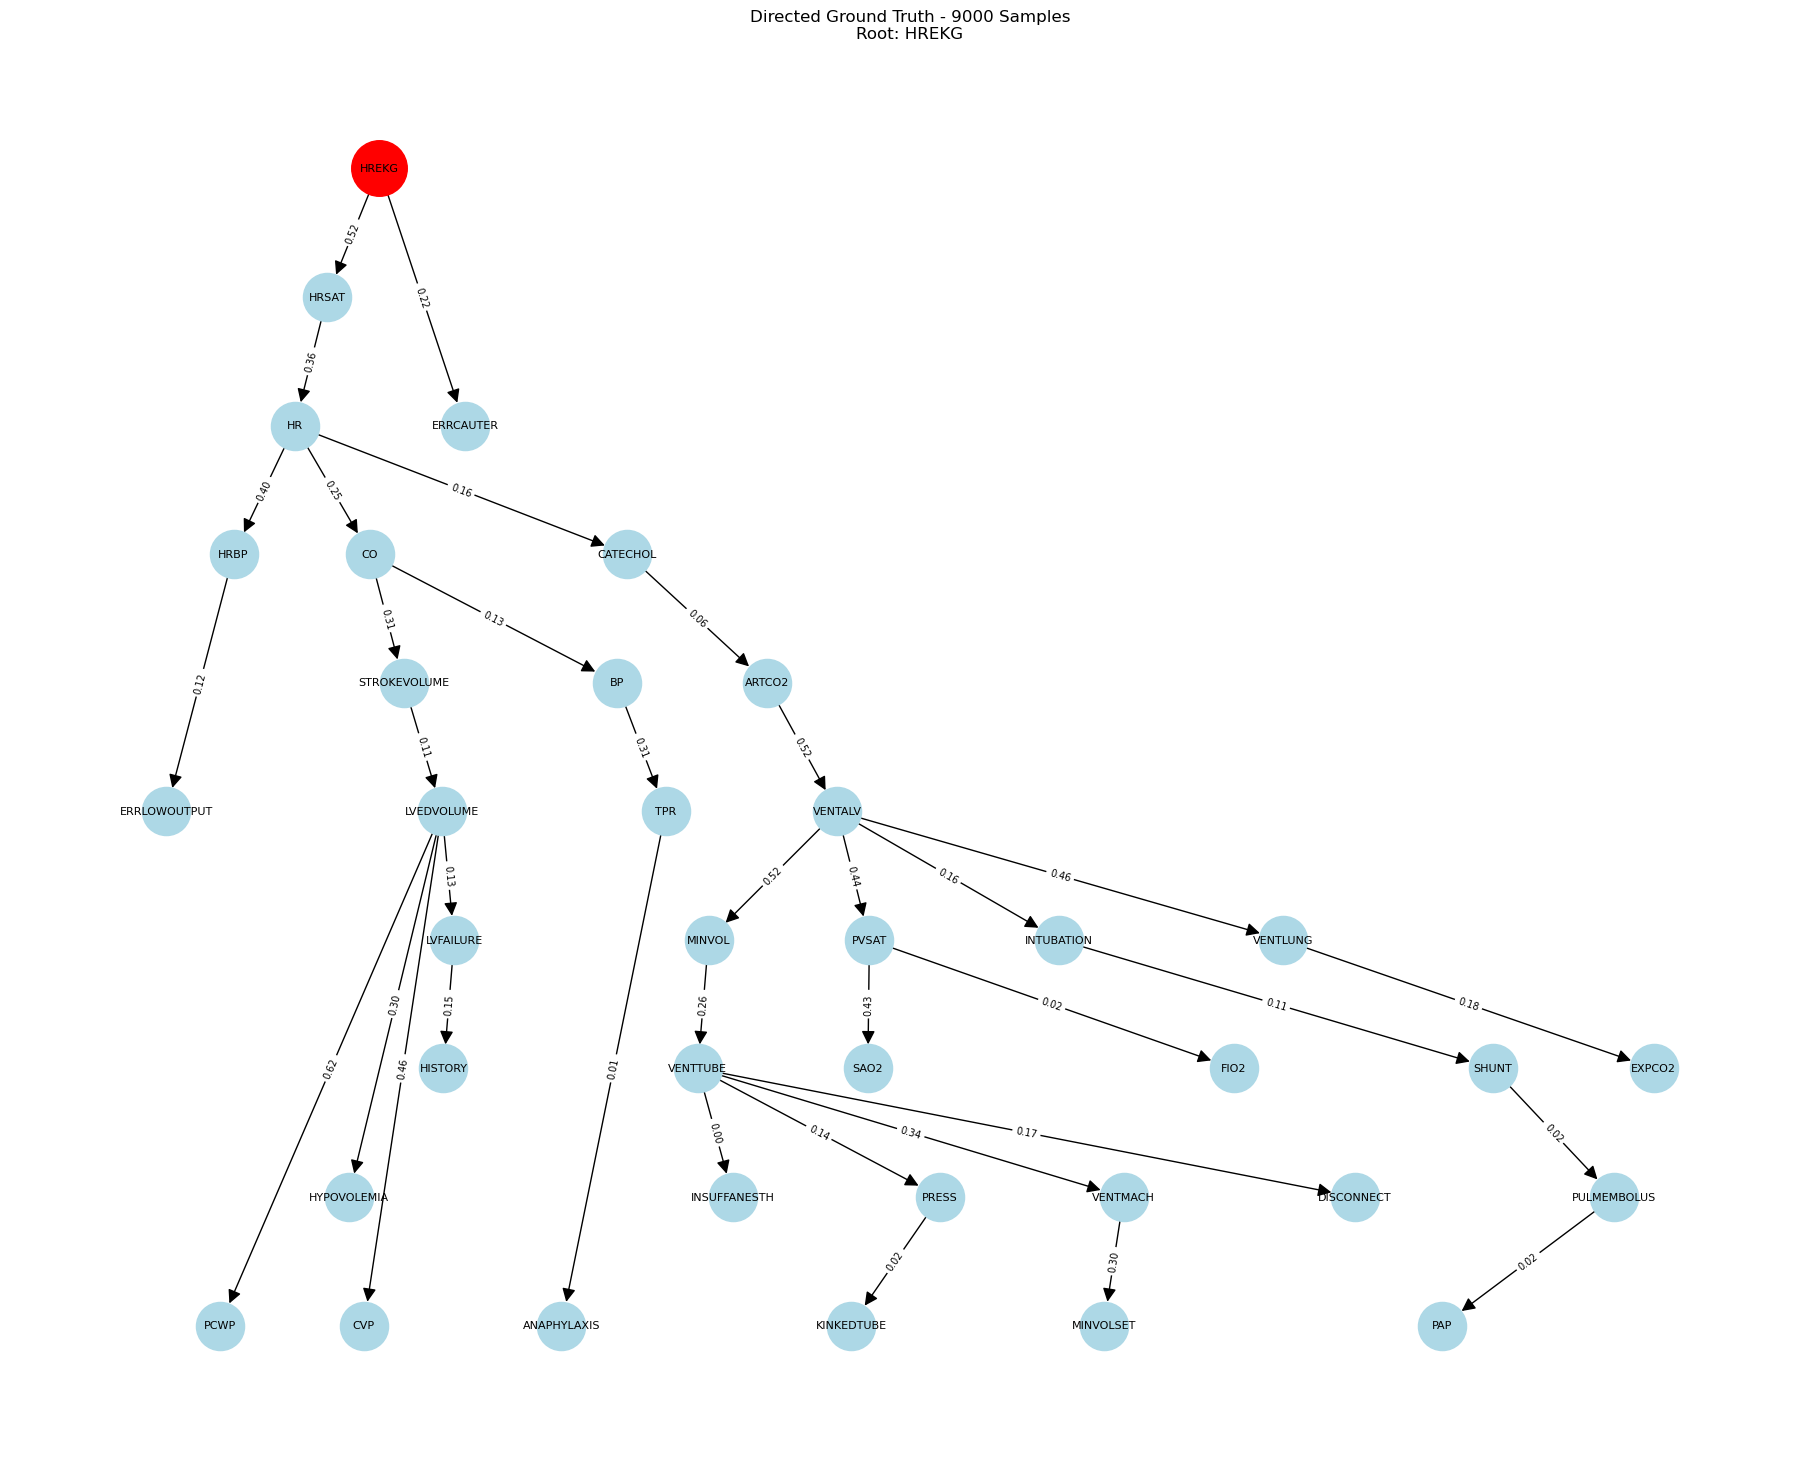

In [ ]:
def step_orient_gt():
    ensure_dir(DIRS["gt_directed"])
    for n in ALARM_SAMPLE_SIZES:
        tree = nx.read_graphml(mst_graphml(n))
        random.seed(SEED_GT_ROOT)
        root = random.choice(list(tree.nodes()))
        dag = nx.bfs_tree(tree, source=root)
        for p, c in dag.edges():
            dag[p][c]["weight"] = tree[p][c]["weight"]
        nx.write_graphml(dag, directed_gt(n))
        with open(os.path.join(DIRS["gt_directed"], f"Root_{n}.txt"), "w") as f:
            f.write(str(root))
        print(f"n={n}: root={root}, edges={dag.number_of_edges()} -> {directed_gt(n)}")
        draw_network(dag, layout(dag), os.path.join(DIRS["gt_directed"], f"Directed_GT_{n}.png"),
                     f"Directed Ground Truth - {n} Samples\nRoot: {root}",
                     edge_label_attr="weight", highlight=[root])

run_step("2.5_orient_gt", step_orient_gt)

## 2.6 Overlay check: directed ground truths vs original ALARM

[Saved graph from the original run: '1.2 OverlayCheck' notebook, cell 1]


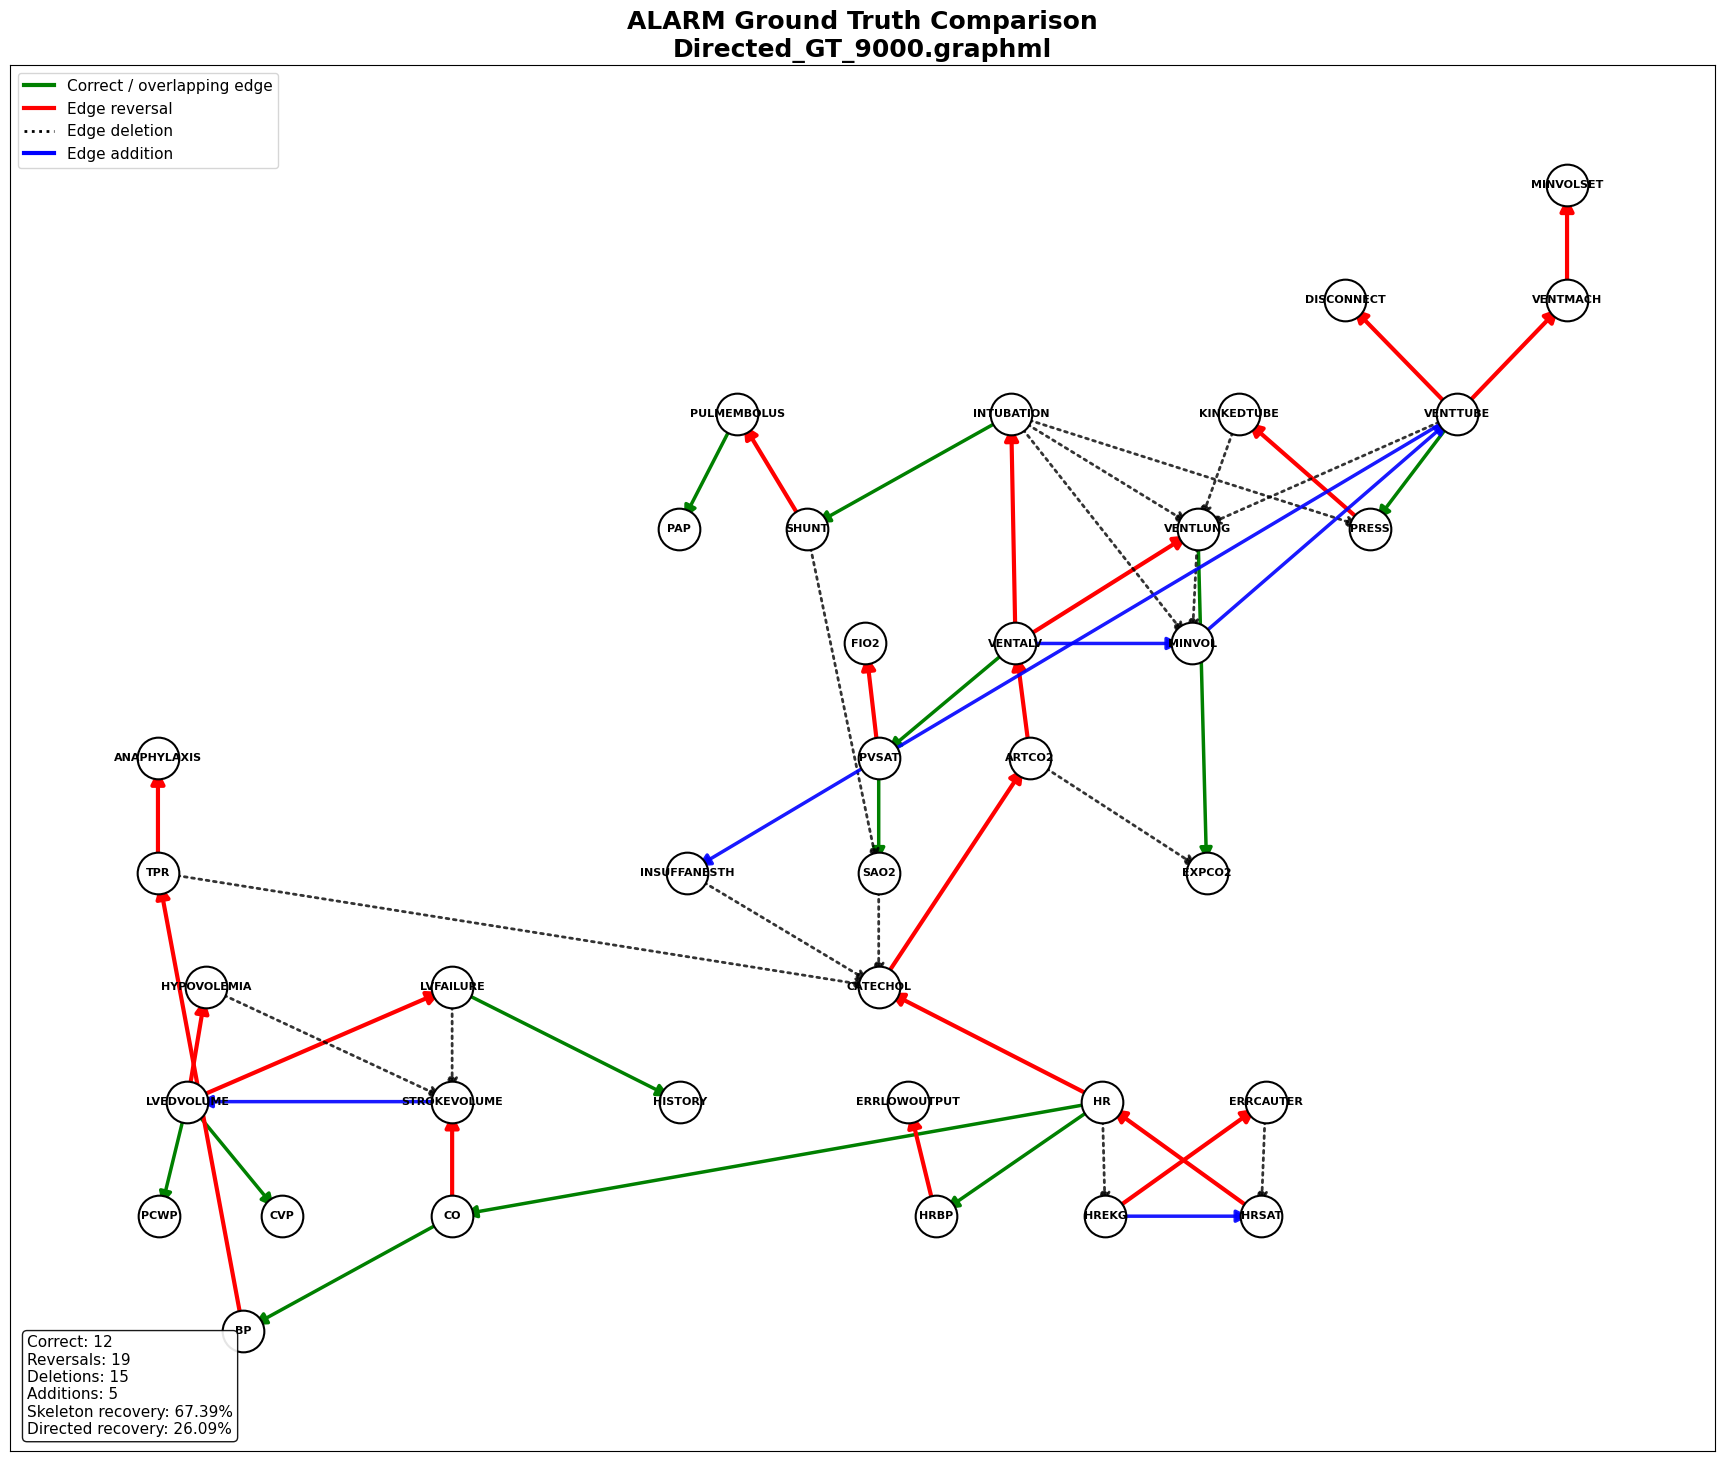

In [ ]:
def step_gt_vs_alarm():
    alarm = read_graph(ORIGINAL_ALARM_GRAPHML)
    pos = layout(alarm)                                   # Graphviz dot of ALARM (= ALARM_POS)
    for n in ALARM_SAMPLE_SIZES:
        stem = f"Directed_GT_{n}"
        banner(f"ALARM vs {stem}")
        compare_and_save(alarm, read_graph(directed_gt(n)), DIRS["gt_compare"],
                         f"ALARM Ground Truth Comparison\n{stem}.graphml",
                         files=dict(summary=f"{stem}_comparison_summary.csv", edges=f"{stem}_edge_classification.csv",
                                    png=f"{stem}_comparison.png", graphml=f"{stem}_comparison.graphml",
                                    pos_json=f"{stem}_node_positions.json", pos_txt=f"{stem}_node_positions.txt"),
                         pos=pos, list_edges=False)

run_step("2.6_gt_vs_alarm", step_gt_vs_alarm)

## 2.7 Random TabularCPDs for every ground truth

`np.random.seed(42)` is reset for every ground truth. The CPDs are reproducible because each column of each CPT is one Dirichlet(1, …, 1) draw, taken in node order.

In [ ]:
def step_tabular_cpd():
    for i in GT_IDS:
        n = gt_n(i)
        G = nx.read_graphml(directed_gt(n))
        G = G if G.is_directed() else G.to_directed()
        missing = [v for v in G.nodes() if v not in ALARM_STATES]
        if missing:
            raise ValueError(f"GT variables missing from ALARM_STATES: {missing}")
        model = BNClass(); model.add_nodes_from(G.nodes()); model.add_edges_from(G.edges())

        np.random.seed(SEED_GT_CPD)
        cpds = []
        for node in model.nodes():
            states = ALARM_STATES[node]; card = len(states)
            parents = list(model.get_parents(node))
            if not parents:
                cpds.append(TabularCPD(node, card, np.random.dirichlet(np.ones(card)).reshape(card, 1),
                                       state_names={node: states}))
                continue
            pcards = [len(ALARM_STATES[p]) for p in parents]
            probs = np.zeros((card, int(np.prod(pcards))))
            for c in range(probs.shape[1]):
                probs[:, c] = np.random.dirichlet(np.ones(card))
            cpds.append(TabularCPD(node, card, probs, evidence=parents, evidence_card=pcards,
                                   state_names={node: states, **{p: ALARM_STATES[p] for p in parents}}))
        model.add_cpds(*cpds)
        if not model.check_model():
            raise ValueError(f"GT{i}: Bayesian Network is invalid.")
        out = ensure_dir(os.path.join(DIRS["tabular"], str(i)))
        write_cpds_txt(cpds, os.path.join(out, f"Directed_GT_{n}_CPDS.txt"))
        save_bn(model, tabular_bif(i))
        print(f"GT{i}: {len(G.nodes())} nodes, {len(G.edges())} edges -> {tabular_bif(i)}")

run_step("2.7_tabular_cpd", step_tabular_cpd)

## 2.8 Forward-sample every synthetic ground truth

In [ ]:
def step_synth_samples():
    for i in GT_IDS:
        model = load_bn(tabular_bif(i))
        if not model.check_model():
            raise ValueError(f"GT{i} invalid")
        sampler = BayesianModelSampling(model)
        ensure_dir(os.path.dirname(synth_csv(i, SAMPLE_SIZES[0])))
        for n in SAMPLE_SIZES:
            sampler.forward_sample(size=n, seed=SEED_SYNTH_SAMPLES).to_csv(synth_csv(i, n), index=False)
        print(f"GT{i}: saved {len(SAMPLE_SIZES)} datasets")

run_step("2.8_synth_samples", step_synth_samples)

# 3. RQ1: Structure and parameter learning on the synthetic ground truths

## 3.1 BIC score trees (Prim and Kruskal)

The asymmetric BIC gain is w(i←j) = BIC(Xᵢ | Xⱼ) − BIC(Xᵢ). The skeleton uses max(w(i←j), w(j←i)), and each edge is oriented in the direction with the larger gain. The undirected-only first version from the BIC notebook ("we don't use this one") is not included.

In [ ]:
def step_bic_trees():
    for i in GT_IDS:
        for j in SAMPLE_SIZES:
            df = pd.read_csv(synth_csv(i, j))
            out = ensure_dir(bic_dir(i, j))
            trees = learn_bic_trees(df)
            for alg, tree in trees.items():
                nx.write_graphml(tree, bic_graph(i, j, alg))
                draw_network(tree, layout(tree), os.path.join(out, f"GT{i}_N{j}_BIC_{alg}.png"),
                             f"BIC Score Tree - GT{i} - N={j} - {alg}", node_size=2500, font_size=9,
                             width=2, edge_label_attr="bic_score", edge_label_size=8, show=False)
            print(f"GT{i} N={j}: " + ", ".join(f"{a} {t.number_of_edges()} edges, DAG={nx.is_directed_acyclic_graph(t)}"
                                             for a, t in trees.items()))

run_step("3.1_bic_trees", step_bic_trees)

## 3.2 BIC trees vs ground truth (comparison pictures)

The original compared against the **undirected** MI tree `4.Ground_Truth_Trees/MST_{i}000`, so its reversal counts depend on the edge order stored in the file. Set `BIC_COMPARE_AGAINST = "DIRECTED_GT"` in the configuration to compare against the directed ground truth instead, which is what the SHAP comparison in 3.4 uses.

In [ ]:
def step_bic_compare():
    for i in GT_IDS:
        ref_path = mst_graphml(gt_n(i)) if BIC_COMPARE_AGAINST == "MST" else directed_gt(gt_n(i))
        ref = read_graph(ref_path)
        for j in SAMPLE_SIZES:
            folder = bic_dir(i, j)
            rows = []
            save_positions(ALARM_POS, json_path=os.path.join(folder, "original_node_positions.json"))
            for alg in ("Prim", "Kruskal"):
                name = f"GT{i}_N{j}_BIC_{alg}"
                banner(name)
                _, summ = compare_and_save(ref, read_graph(bic_graph(i, j, alg)), folder,
                                           f"ALARM Ground Truth Comparison - GT{i} - N={j}\n{name}",
                                           files=dict(edges=f"{name}_edge_classification.csv", png=f"{name}_comparison.png"),
                                           extra=dict(GroundTruth=i, SampleSize=j, Comparison_Graph=name), list_edges=False)
                rows.append(summ)
            pd.concat(rows).to_csv(os.path.join(folder, "all_comparisons_summary.csv"), index=False)

run_step("3.2_bic_compare", step_bic_compare)

## 3.3 SHAP trees (37 XGBoost models per dataset)

### Methodology notes (from the SHAP notebook)

#### The Methodological Fix

Instead of one target, train **one model per variable**.

For every variable $X_i$:

1. Treat $X_i$ as the target.
2. Treat every other variable as predictors.
3. Train XGBoost.
4. Compute SHAP interaction values.

You have 37 variables, so:

| Target Model | Purpose |
|---|---|
| Model 1 predicts `HREKG` | Find variables interacting with `HREKG` |
| Model 2 predicts `HRSAT` | Find variables interacting with `HRSAT` |
| ... | ... |
| Model 37 predicts `PAP` | Find variables interacting with `PAP` |

Now every node gets a chance to be explained.

**This makes your method comparable to BIC**, because every variable participates equally.

> I think this is the strongest version of your methodology.

---

#### How Do You Combine 37 SHAP Outputs?

This is where your interaction matrix comes in.

For target $X_i$, SHAP gives interaction scores:

$$I_i(X_j, X_k)$$

But you're interested in the interaction between the target and another feature.

For target `VENTTUBE`:

| Target | SHAP Interaction Score |
|---|---|
| `VENTTUBE` | $I(\text{VENTTUBE}, \text{MINVOL})$ |
| `VENTTUBE` | $I(\text{VENTTUBE}, \text{PRESS})$ |
| `VENTTUBE` | $I(\text{VENTTUBE}, \text{HR})$ |

Fill a symmetric matrix:

$$
W_{ij} = \frac{|I_i(i,j)| + |I_j(i,j)|}{2}
$$

**Why average?**

Because:
- Model predicting $A$ gives one interaction score.
- Model predicting $B$ gives another.
- Averaging removes target asymmetry.

This is actually a nice methodological contribution, because BIC also produces pairwise weights.

Then Prim/Kruskal receives the same type of matrix — now the comparison is fair.

---

#### Should the Target Be Random?

**I would not make it random.** Here's why.

You said:

> "Choose a seed so it's reproducible."

That gives reproducibility. **It does not give methodological validity.**

Different targets produce different graphs, so randomness introduces variance unrelated to your research question.

| Approach | Verdict |
|---|---|
| Random single target | ❌ Not comparable |
| Always choose same target | ❌ Biased toward one neighbourhood |
| Train every variable once | ✅ Comparable and unbiased |

### Run the SHAP trees

The first single-file version (no orientation, a different way of averaging over classes) was replaced by this looped, oriented version, which produced `11.SHAPLY`.

[Saved graph from the original run: '3. SHAPLY II graphs' notebook, cell 2]


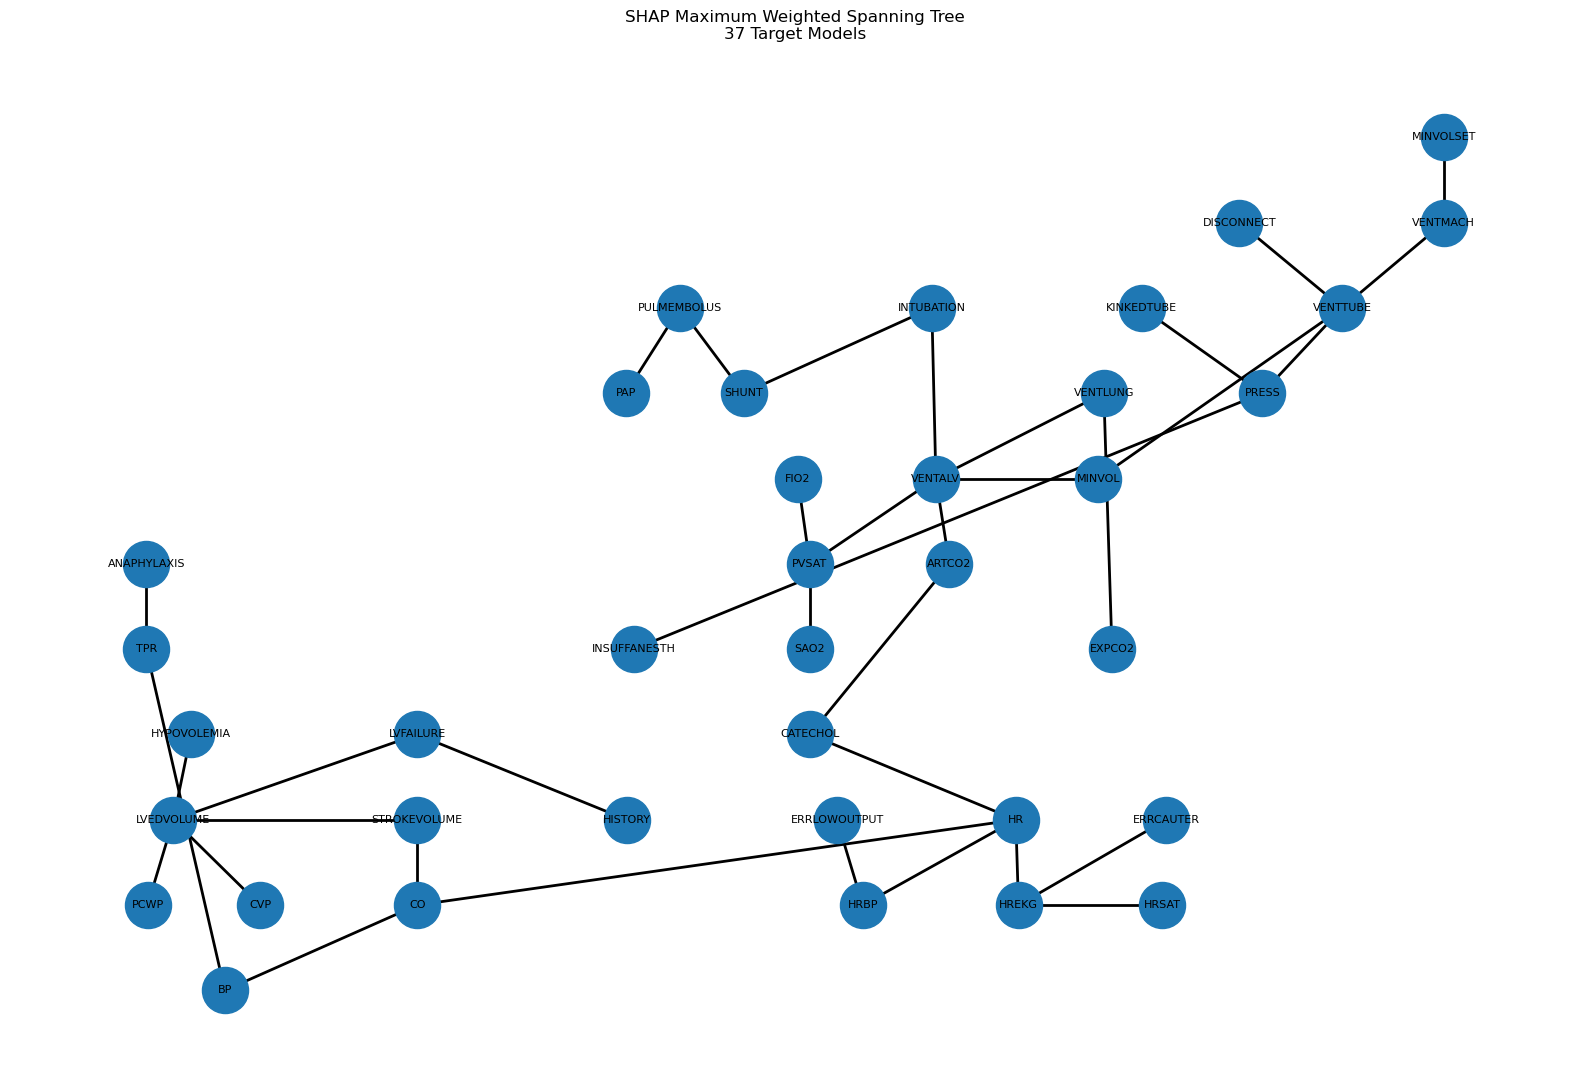

In [ ]:
def save_shap_outputs(res, out, title_suffix):
    """All files the original SHAP pipeline wrote for one dataset."""
    v, n = res["variables"], len(res["variables"])
    for target in v:
        sc = res["target_scores"][target]
        (pd.DataFrame({"Predictor": list(sc), "SHAP_Importance": list(sc.values())})
           .sort_values("SHAP_Importance", ascending=False)
           .to_csv(os.path.join(out, f"SHAP_Scores_Target_{target}.csv"), index=False))
    pd.DataFrame(res["W"], index=v, columns=v).to_csv(os.path.join(out, f"SHAP_{n}x{n}_Weight_Matrix.csv"))
    nx.write_graphml(res["MWST"], os.path.join(out, f"SHAP_MWST_{n}nodes.graphml"))
    (pd.DataFrame([{"Source": a, "Target": b, "Weight": d["weight"]} for a, b, d in res["MWST"].edges(data=True)])
       .sort_values("Weight", ascending=False).to_csv(os.path.join(out, "SHAP_MWST_Edges.csv"), index=False))
    pd.DataFrame([{"Target": t, "Accuracy": r["accuracy"], "Weighted_F1": r["f1"]}
                  for t, r in res["model_results"].items()]).to_csv(
        os.path.join(out, "XGBoost_Model_Performance.csv"), index=False)
    nx.write_graphml(res["DAG"], os.path.join(out, "SHAP_Oriented_DAG.graphml"))
    (pd.DataFrame(res["oriented_edges"]).sort_values("Weight", ascending=False)
       .to_csv(os.path.join(out, "SHAP_Oriented_DAG_Edges.csv"), index=False))
    for G, fname, title in [(res["MWST"], f"SHAP_MWST_{n}nodes.png", "SHAP Maximum Weighted Spanning Tree"),
                            (res["DAG"], f"SHAP_Oriented_DAG_{n}nodes.png", "SHAP Oriented DAG")]:
        draw_network(G, ALARM_POS, os.path.join(out, fname), f"{title} - {title_suffix}\n{n} Target Models",
                     figsize=(16, 11), node_size=1100, node_color="#1f78b4", width=2, show=False)

def step_shap_trees():
    for i in GT_IDS:
        for j in SAMPLE_SIZES:
            banner(f"SHAP tree  GT{i}  N={j}")
            df = pd.read_csv(synth_csv(i, j))
            res = learn_shap_tree(df, seed=SEED_SHAP, evaluate=True)
            save_shap_outputs(res, ensure_dir(shap_dir(i, j)), f"GT{i} - N={j}")

run_step("3.3_shap_trees", step_shap_trees)

## 3.4 SHAP DAG vs directed ground truth

In [ ]:
def step_shap_compare():
    for i in GT_IDS:
        gt = read_graph(directed_gt(gt_n(i)), to_directed=True)
        for j in SAMPLE_SIZES:
            banner(f"SHAP DAG vs GT  GT{i}  N={j}")
            compare_and_save(gt, read_graph(shap_dag(i, j), to_directed=True),
                             os.path.join(shap_dir(i, j), "Comparisons"),
                             f"SHAP Oriented DAG vs Ground Truth - GT{i} - N={j}\nDirected_GT_{gt_n(i)} | sample{j}",
                             files=dict(summary="SHAP_DAG_vs_GT_comparison_summary.csv",
                                        edges="SHAP_DAG_vs_GT_edge_classification.csv",
                                        png="SHAP_DAG_vs_GT_comparison.png", graphml="SHAP_DAG_vs_GT_comparison.graphml",
                                        pos_json="node_positions.json"),
                             extra=dict(GroundTruth=i, SampleSize=j), list_edges=False)

run_step("3.4_shap_compare", step_shap_compare)

## 3.5 Parameter learning for the BIC (Kruskal) and SHAP structures

A single loop handles both methods. The original was one cell that you re-ran after swapping the commented-out paths.

In [ ]:
def load_samples_clean(path):
    data = pd.read_csv(path, dtype=str, keep_default_na=False)
    data.columns = data.columns.str.replace("﻿", "", regex=False).str.strip()
    for col in data.columns:
        data[col] = data[col].astype(str).str.strip()
    return data

def step_param_learning():
    jobs = [("BIC", lambda i, j: bic_graph(i, j, "Kruskal"), bic_cpd_bif, "BIC"),
            ("SHAPLY", shap_dag, shap_cpd_bif, "SHAPLY")]
    for label, struct_fn, out_fn, prefix in jobs:
        for i in GT_IDS:
            for j in SAMPLE_SIZES:
                s_path, d_path = struct_fn(i, j), synth_csv(i, j)
                if not (os.path.exists(s_path) and os.path.exists(d_path)):
                    print(f"[SKIP] {label} GT{i} N={j}: missing input"); continue
                G = nx.read_graphml(s_path); G = G if G.is_directed() else G.to_directed()
                data = load_samples_clean(d_path)
                missing = [v for v in G.nodes() if v not in data.columns]
                if missing:
                    print(f"[SKIP] {label} GT{i} N={j}: nodes missing from samples {missing}"); continue
                try:
                    model, cpds = learn_cpds_pgmpy(G, data)
                except Exception as e:
                    print(f"[ERROR] {label} GT{i} N={j}: {e}"); continue
                out = ensure_dir(os.path.dirname(out_fn(i, j)))
                write_cpds_txt(cpds, os.path.join(out, f"{prefix}_CPDS.txt"))
                save_bn(model, out_fn(i, j))
                print(f"{label} GT{i} N={j}: saved {out_fn(i, j)}")

run_step("3.5_param_learning", step_param_learning)

# 4. RQ1: KL divergence and SHD graphs

## 4.1 KL divergence values: D_KL(GT ‖ learned)

This is a Monte-Carlo estimate from 500,000 samples drawn from the ground truth, with seed 1 for both methods. The two earlier single-dataset test cells (GT1, N = 50 or 1000) are covered by this loop.

In [ ]:
def step_kl_values():
    for i in GT_IDS:
        for j in SAMPLE_SIZES:
            paths = {"GT": tabular_bif(i), "BIC": bic_cpd_bif(i, j), "SHAPLEY": shap_cpd_bif(i, j)}
            if not all(os.path.exists(p) for p in paths.values()):
                print(f"[SKIP] GT{i} N={j}: missing", [k for k, p in paths.items() if not os.path.exists(p)]); continue
            banner(f"KL  GT{i}  N={j}")
            try:
                gt, bic, sha = (load_bn(paths[k]) for k in ("GT", "BIC", "SHAPLEY"))
                kl_b, se_b = kl_divergence_mc(gt, bic)
                kl_s, se_s = kl_divergence_mc(gt, sha)
            except Exception as e:
                print(f"[ERROR] GT{i} N={j}: {e}"); continue
            print(f"D_KL(GT || BIC) = {kl_b:.6f} (SE {se_b:.6f})   D_KL(GT || SHAPLEY) = {kl_s:.6f} (SE {se_s:.6f})")
            ensure_dir(os.path.dirname(kl_rq1_csv(i, j)))
            pd.DataFrame([
                {"GroundTruth": i, "SampleSize": j, "method": "BIC", "kl_divergence": kl_b, "std_error": se_b},
                {"GroundTruth": i, "SampleSize": j, "method": "SHAPLEY", "kl_divergence": kl_s, "std_error": se_s},
            ]).to_csv(kl_rq1_csv(i, j), index=False)

run_step("4.1_kl_values", step_kl_values)

## 4.2 KL divergence graphs

[Saved graph from the original run: '4. RQ1 KL & SHD graphs' notebook, cell 4]


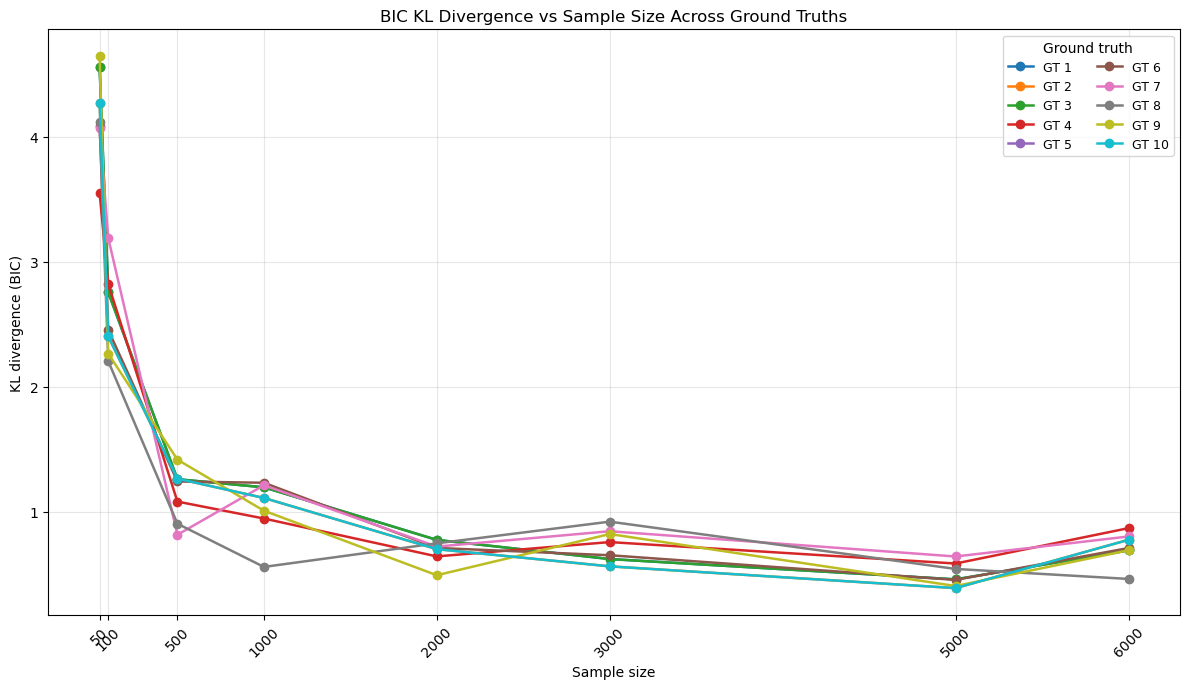

[Saved graph from the original run: '4. RQ1 KL & SHD graphs' notebook, cell 6]


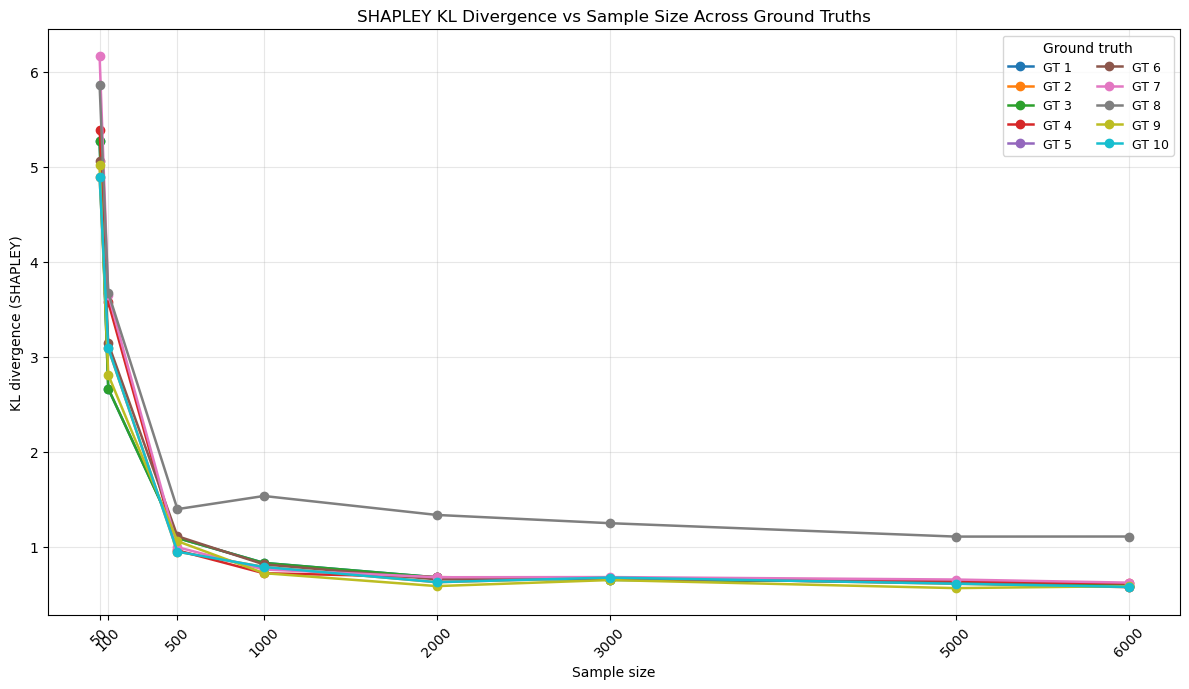

[Saved graph from the original run: '4. RQ1 KL & SHD graphs' notebook, cell 9]


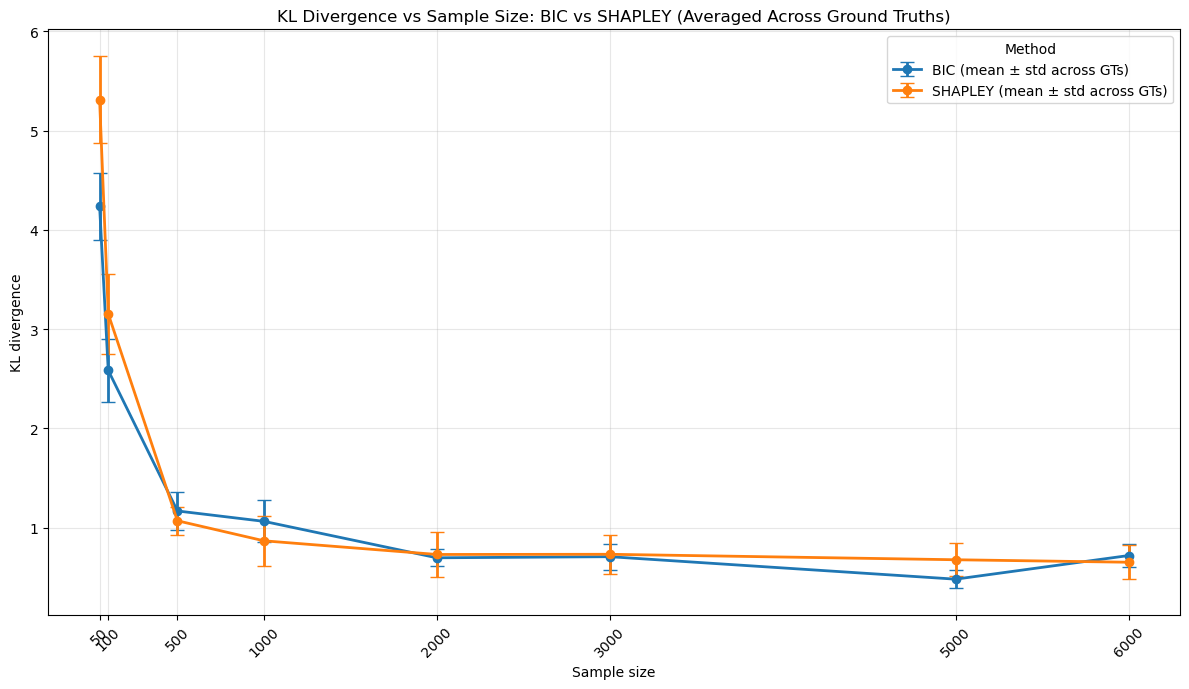

In [ ]:
def collect_rq1_kl():
    rows = []
    for i in GT_IDS:
        for j in SAMPLE_SIZES:
            p = kl_rq1_csv(i, j)
            if not os.path.exists(p):
                print("Missing file:", p); continue
            d = pd.read_csv(p); d["method"] = d["method"].str.upper()
            for m in ("BIC", "SHAPLEY"):
                r = d[d["method"] == m]
                if len(r):
                    rows.append({"GT": i, "n": j, "method": m, "KL": float(r["kl_divergence"].iloc[0])})
    return pd.DataFrame(rows, columns=["GT", "n", "method", "KL"])

def step_kl_graphs():
    kl = collect_rq1_kl()
    kl.to_csv(os.path.join(DIRS["kl_rq1"], "KL_all_GTs_long.csv"), index=False)

    # 1) and 2): one line per ground truth, for each method
    for m in ("BIC", "SHAPLEY"):
        plt.figure(figsize=(12, 7))
        for i in GT_IDS:
            ys = kl[(kl.method == m) & (kl.GT == i)].set_index("n")["KL"].reindex(SAMPLE_SIZES)
            plt.plot(SAMPLE_SIZES, ys.values, marker="o", linewidth=1.8, label=f"GT {i}")
        plt.xlabel("Sample size"); plt.ylabel(f"KL divergence ({m})")
        plt.title(f"{m} KL Divergence vs Sample Size Across Ground Truths")
        plt.xticks(SAMPLE_SIZES, rotation=45); plt.grid(True, alpha=0.3)
        plt.legend(title="Ground truth", ncol=2, fontsize=9); plt.tight_layout()
        save_fig(os.path.join(DIRS["kl_rq1"], f"{m}_KL_divergence_all_GTs.png"))

    # 3) mean +/- std across ground truths
    plt.figure(figsize=(12, 7))
    for m, color in (("BIC", "tab:blue"), ("SHAPLEY", "tab:orange")):
        g = kl[kl.method == m].groupby("n")["KL"]
        means, stds = g.mean().reindex(SAMPLE_SIZES), g.std(ddof=1).reindex(SAMPLE_SIZES)
        print(f"\n{m} summary:"); print(pd.DataFrame({"mean": means, "std": stds}).round(4).to_string())
        plt.errorbar(SAMPLE_SIZES, means.values, yerr=stds.values, marker="o", linewidth=2.0, capsize=5,
                     color=color, label=f"{m} (mean ± std across GTs)")
    plt.xlabel("Sample size"); plt.ylabel("KL divergence")
    plt.title("KL Divergence vs Sample Size: BIC vs SHAPLEY (Averaged Across Ground Truths)")
    plt.xticks(SAMPLE_SIZES, rotation=45); plt.grid(True, alpha=0.3); plt.legend(title="Method", fontsize=10)
    plt.tight_layout()
    save_fig(os.path.join(DIRS["kl_rq1"], "KL_divergence_BIC_vs_SHAPLEY_avg.png"))

run_step("4.2_kl_graphs", step_kl_graphs)

### Notes on the KL results (from the KL notebook)
* SHAP beats BIC at small sample sizes because SHAP finds something closer to the true Markov structure faster. For GT1 it reaches 100% structure recovery quickly, which is why its KL value is lower. BIC catches up between 3000 and 6000 samples, when it recovers more of the directions, and then does much better because it has recovered more structure.
* BIC's values decrease more consistently. For SHAP at 6000 samples the value can go up or down, but BIC reliably goes down.
* For the bigger ground truths (e.g. GT8), BIC recovers the structure very quickly, so there is enough information in the GT and samples to learn it fast.

## 4.3 Structural Hamming distance (with and without orientation)

The SHD is computed directly from the learned graphs: `9.BIC Score Structures/…/GT{i}_N{j}_BIC_Kruskal.graphml` and `11.SHAPLY/…/SHAP_Oriented_DAG.graphml`. This replaces the manual step of copying files into folder 14. The result is identical, because removing the "deletion" edges from the SHAP comparison GraphML leaves exactly the learned DAG.

[Saved graph from the original run: '4. RQ1 KL & SHD graphs' notebook, cell 13]


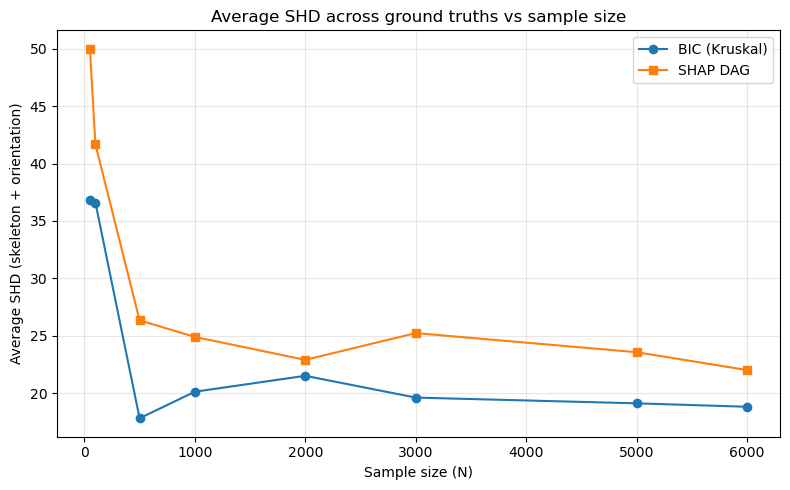

[Saved graph from the original run: '4. RQ1 KL & SHD graphs' notebook, cell 15]


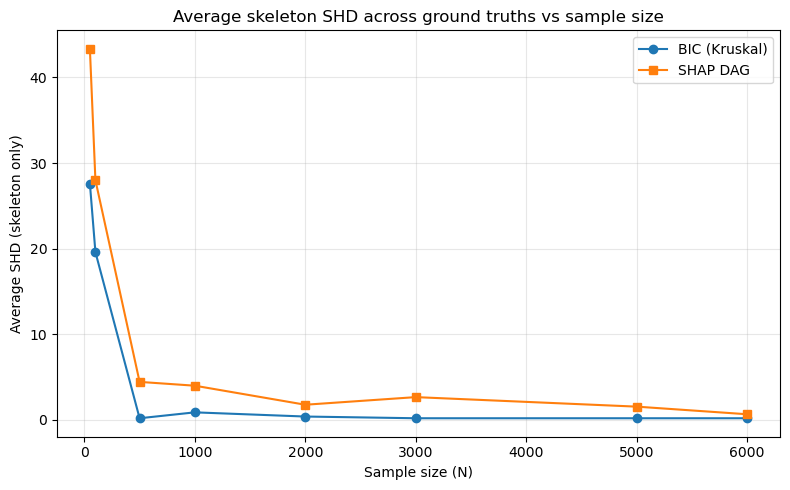

In [ ]:
def step_shd():
    rows = []
    for i in GT_IDS:
        ref = set(read_graph(directed_gt(gt_n(i))).edges())
        for method, fn in (("SHAP_DAG", shap_dag), ("BIC_Kruskal", lambda a, b: bic_graph(a, b, "Kruskal"))):
            for j in SAMPLE_SIZES:
                p = fn(i, j)
                if not os.path.exists(p):
                    print("Missing:", p); continue
                c = shd_counts(ref, read_graph(p).edges())
                rows.append({"GT": i, "method": method, "N": j, "file": os.path.basename(p),
                             "SHD": c["SHD"], "missing": c["deleted"], "extra": c["added"],
                             "reversed": c["reversed"], "SHD_skeleton": c["SHD_skeleton"]})
    shd = pd.DataFrame(rows)
    for i, g in shd.groupby("GT"):
        out = ensure_dir(os.path.join(DIRS["shd_rq1"], str(i)))
        g[["method", "N", "file", "SHD", "missing", "extra", "reversed"]].to_csv(
            os.path.join(out, f"SHD_results_folder{i}.csv"), index=False)
        g[["method", "N", "file", "SHD_skeleton", "missing", "extra"]].to_csv(
            os.path.join(out, f"SHD_skeleton_results_folder{i}.csv"), index=False)
    shd.to_csv(os.path.join(DIRS["shd_rq1"], "SHD_all_GTs_long.csv"), index=False)

    for col, ylabel, title, fname in [
        ("SHD", "Average SHD (skeleton + orientation)", "Average SHD across ground truths vs sample size",
         "Average_SHD_BIC_vs_SHAP.png"),
        ("SHD_skeleton", "Average SHD (skeleton only)", "Average skeleton SHD across ground truths vs sample size",
         "Average_SHD_skeleton_BIC_vs_SHAP.png")]:
        plt.figure(figsize=(8, 5))
        for method, label, marker in (("BIC_Kruskal", "BIC (Kruskal)", "o"), ("SHAP_DAG", "SHAP DAG", "s")):
            m = shd[shd.method == method].groupby("N")[col].mean()
            plt.plot(m.index, m.values, marker=marker, label=label)
        plt.xlabel("Sample size (N)"); plt.ylabel(ylabel); plt.title(title)
        plt.grid(True, alpha=0.3); plt.legend(); plt.tight_layout()
        save_fig(os.path.join(DIRS["shd_rq1"], fname))
    print(shd.groupby(["method", "N"])[["SHD", "SHD_skeleton"]].mean().round(2).to_string())

run_step("4.3_shd", step_shd)

## 4.4 Explaining the KL results: CPT degrees of freedom and edge reversals

These settings in the configuration control this step:
* `DOF_RQ1_SOURCE = "comparison_graphml"` reproduces your figure. Note that the SHAP comparison GraphML **also contains the ground-truth edges SHAP missed** (the "deletion" edges), so SHAP's parent counts and DoF are inflated. `"learned_dag"` uses the SHAP DAG itself.
* `DOF_TRUE_CARDINALITY = False` reproduces your figure, where every node counts as 2 states because the GraphML files carry no cardinality. Setting it to `True` uses the real ALARM state counts.

The KL lines on the second axis are now computed from 4.1's CSVs. Your "Table 5" values are kept below so you can compare.

[Saved graph from the original run: 'Most graphs I could get together' notebook, cell 13]


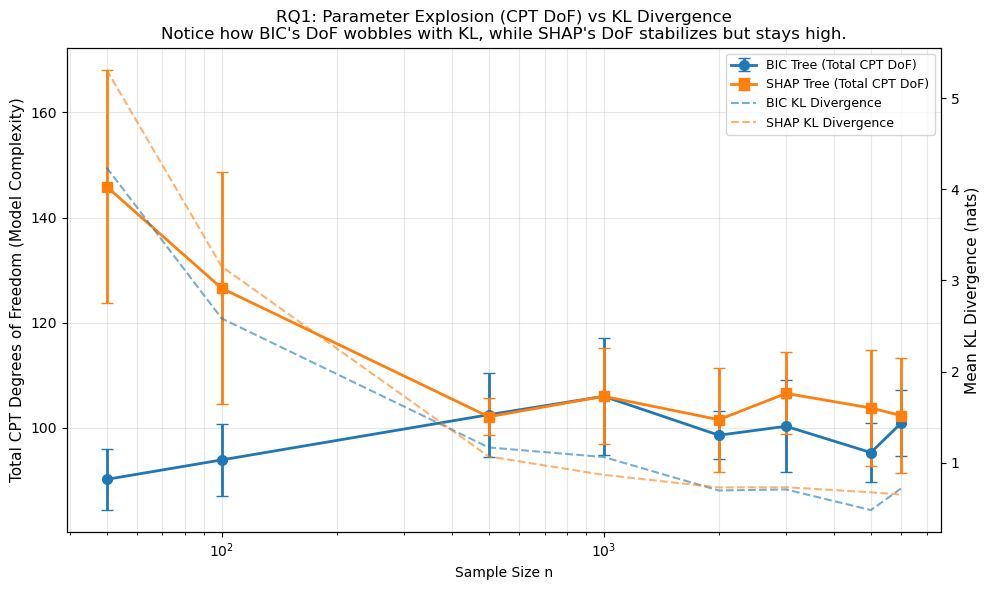

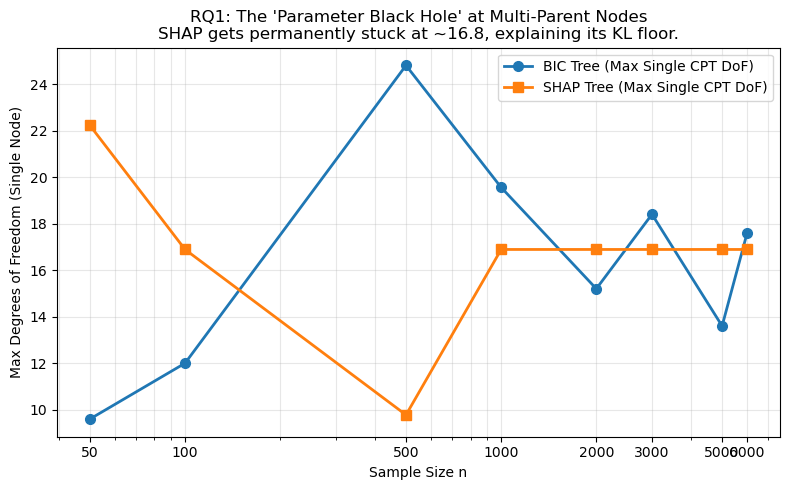

In [ ]:
# Table 5 values that were hard-coded in the original cell (for comparison)
TABLE5_KL_BIC  = {50: 4.2392, 100: 2.5837, 500: 1.1670, 1000: 1.0624, 2000: 0.6950, 3000: 0.7063, 5000: 0.4796, 6000: 0.7177}
TABLE5_KL_SHAP = {50: 5.3127, 100: 3.1528, 500: 1.0682, 1000: 0.8663, 2000: 0.7286, 3000: 0.7304, 5000: 0.6753, 6000: 0.6502}

def step_dof_rq1():
    rows, reversals = [], []
    for i in GT_IDS:
        for j in SAMPLE_SIZES:
            shap_path = shap_cmp_graphml(i, j) if DOF_RQ1_SOURCE == "comparison_graphml" else shap_dag(i, j)
            for method, p in (("BIC", bic_graph(i, j, "Kruskal")), ("SHAP", shap_path)):
                if os.path.exists(p):
                    rows.append(dof_row(nx.DiGraph(nx.read_graphml(p)), GT=i, n=j, method=method))
        # BIC edges that flip direction between n=5000 and n=6000
        p5, p6 = bic_graph(i, 5000, "Kruskal"), bic_graph(i, 6000, "Kruskal")
        if os.path.exists(p5) and os.path.exists(p6):
            G5, G6 = nx.DiGraph(nx.read_graphml(p5)), nx.DiGraph(nx.read_graphml(p6))
            for u, v in G5.edges():
                if G6.has_edge(v, u):
                    cu, cv = node_cardinality(G5, u), node_cardinality(G5, v)
                    reversals.append({"GT": i, "edge_5000": f"{u} -> {v}", "edge_6000": f"{v} -> {u}",
                                      "u_cardinality": cu, "v_cardinality": cv, "combined_cardinality": cu * cv})
    df = pd.DataFrame(rows)
    agg = df.groupby(["method", "n"]).agg(mean_total_dof=("total_cpt_dof", "mean"), std_total_dof=("total_cpt_dof", "std"),
                                          mean_max_cpt=("max_single_cpt_dof", "mean")).reset_index()
    print("=== Mean Total CPT DoF per graph ===\n", agg.to_string(index=False))
    rev = pd.DataFrame(reversals)
    print(f"\n=== BIC edge reversals between n=5000 and n=6000: {len(rev)} ===")
    if len(rev): print(rev.to_string(index=False))

    kl = collect_rq1_kl()
    kl_bic, kl_shap = mean_kl_by_size(kl, "BIC", "n"), mean_kl_by_size(kl, "SHAPLEY", "n")
    print("\nKL means now vs Table 5:")
    print(pd.DataFrame({"BIC_now": kl_bic, "BIC_table5": TABLE5_KL_BIC,
                        "SHAP_now": kl_shap, "SHAP_table5": TABLE5_KL_SHAP}).round(4).to_string())
    plot_dof(agg, kl_bic or TABLE5_KL_BIC, kl_shap or TABLE5_KL_SHAP,
             "RQ1: Parameter Explosion (CPT DoF) vs KL Divergence",
             "RQ1: The 'Parameter Black Hole' at Multi-Parent Nodes",
             os.path.join(DIRS["shd_rq1"], "cpt_dof_vs_kl.png"), os.path.join(DIRS["shd_rq1"], "max_cpt_vs_sample.png"),
             "Mean KL Divergence (nats)")

run_step("4.4_dof", step_dof_rq1)

# 5. RQ2: Recovering the real ALARM network

## 5.1 RQ2 with 10 seeds: are the results consistent?

The real ALARM network is sampled at every sample size with 10 seeds (sample of size n for seed s uses seed s + n). BIC trees, SHAP trees and BIC greedy hill climbing are learned on every sample, CPDs are fitted, and each model is scored with KL divergence and SHD against ALARM.

This merges your two original "all in one go" cells. The first did not run as pasted because of a stray `wia` line and some missing constants. The second added hill climbing. Now each model is trained once, and KL and SHD are computed once for all three methods. The 2-method and 3-method CSVs and figures are both still written, with their original file names.

### 5.1.0 Helpers for this section

In [ ]:
RES = DIRS["results"]
def res_dir(method, j, seed):
    sub = {"SHAPLEY": "SHAPLEY tree algorithm", "BIC": "BIC tree algorithm", "HC": "HC algorithm"}[method]
    return os.path.join(RES, sub, f"seed{seed}", str(j))

def learn_and_save_tree(method, df_path, out, seed, state_names):
    """SHAP or BIC tree -> directed_graph.graphml + learned_model.bif."""
    ensure_dir(out)
    if method == "SHAPLEY":
        dag = learn_shap_tree(pd.read_csv(df_path), seed=seed)["DAG"]
    else:
        dag = learn_bic_trees(load_samples_str(df_path), ("Kruskal",))["Kruskal"]
    nx.write_graphml(dag, os.path.join(out, "directed_graph.graphml"))
    try:
        save_bn(fit_bn(dag, load_samples_str(df_path), state_names), os.path.join(out, "learned_model.bif"))
        print(f"  saved model to {out}")
    except Exception as e:
        print(f"[ERROR] parameter learning {out}: {e}")
    return dag

### 5.1.1 Samples for every seed (seed s + n)

In [ ]:
def step_ten_seed_samples():
    sampler = BayesianModelSampling(load_alarm()); ensure_dir(DIRS["new"])
    for s in SEEDS:
        for n in SAMPLE_SIZES:
            out = new_sample_csv(n, s)
            if os.path.exists(out):
                print("[SKIP] exists:", out); continue
            sampler.forward_sample(size=n, seed=s + n).to_csv(out, index=False); print("saved:", out)

run_step("5.1_ten_seeds", step_ten_seed_samples)

### 5.1.2 SHAP trees and BIC trees for every seed × size

The SHAP models use the experiment seed s for XGBoost and the data splits (not 100).

In [ ]:
def ten_seed_states():
    return alarm_state_names([new_sample_csv(n, s) for s in SEEDS for n in SAMPLE_SIZES])

def step_ten_seed_trees():
    states = ten_seed_states()
    for method in ("SHAPLEY", "BIC"):
        for s in SEEDS:
            for j in SAMPLE_SIZES:
                banner(f"{method}  seed={s}  n={j}")
                learn_and_save_tree(method, new_sample_csv(j, s), res_dir(method, j, s), s, states)

run_step("5.1_ten_seeds", step_ten_seed_trees)

### 5.1.3 Greedy hill climbing with the BIC score, for every seed × size

This is the hand-written hill climber you used for the 10-seed runs. It is a implementation written by hand (not the pgmpy one).

In [ ]:
def greedy_hill_climb(df, variables, N, max_iter=500):
    """Add / delete / reverse with the BIC score; stops when no move improves by > 1e-12."""
    cache = {}
    def score(child, pa):
        key = (child, frozenset(pa))
        if key not in cache:
            cache[key] = bic_local_score(df, child, sorted(pa), N)
        return cache[key]
    edges, parents_of = set(), {v: [] for v in variables}
    dag = nx.DiGraph(); dag.add_nodes_from(variables)
    for _ in range(max_iter):
        best, op = 1e-12, None
        for u in variables:
            for v in variables:
                if u == v or (u, v) in edges or (v, u) in edges or nx.has_path(dag, v, u): continue
                d = score(v, parents_of[v] + [u]) - score(v, parents_of[v])
                if d > best: best, op = d, ("add", u, v)
        for (u, v) in edges:
            d = score(v, [p for p in parents_of[v] if p != u]) - score(v, parents_of[v])
            if d > best: best, op = d, ("delete", u, v)
        for (u, v) in edges:
            temp = dag.copy(); temp.remove_edge(u, v)
            if nx.has_path(temp, u, v): continue
            d = (score(u, parents_of[u] + [v]) + score(v, [p for p in parents_of[v] if p != u])
                 - score(u, parents_of[u]) - score(v, parents_of[v]))
            if d > best: best, op = d, ("reverse", u, v)
        if op is None:
            break
        kind, u, v = op
        if kind == "add":
            edges.add((u, v)); parents_of[v].append(u); dag.add_edge(u, v)
        elif kind == "delete":
            edges.discard((u, v)); parents_of[v] = [p for p in parents_of[v] if p != u]; dag.remove_edge(u, v)
        else:
            edges.discard((u, v)); edges.add((v, u))
            parents_of[v] = [p for p in parents_of[v] if p != u]; parents_of[u].append(v)
            dag.remove_edge(u, v); dag.add_edge(v, u)
    return dag

def step_ten_seed_hc():
    states = ten_seed_states()
    for s in SEEDS:
        for j in SAMPLE_SIZES:
            out = ensure_dir(res_dir("HC", j, s)); banner(f"HC  seed={s}  n={j}")
            df = load_samples_str(new_sample_csv(j, s))
            dag = greedy_hill_climb(df, list(df.columns), len(df))
            print(f"  HC: {dag.number_of_edges()} edges, is_dag={nx.is_directed_acyclic_graph(dag)}")
            nx.write_graphml(dag, os.path.join(out, "directed_graph.graphml"))
            try:
                save_bn(fit_bn(dag, df, states), os.path.join(out, "learned_model.bif"))
            except Exception as e:
                print(f"[ERROR] HC parameter learning seed={s} n={j}: {e}")

run_step("5.1_ten_seeds", step_ten_seed_hc)

### 5.1.4 KL and SHD for all seeds and methods

In [ ]:
TEN_METHODS = ("BIC", "SHAPLEY", "HC")

def step_ten_seed_kl_shd():
    og, ref, log_ref = alarm_reference(); og_edges = set(og.edges())
    kl_rows, shd_rows = [], []
    for s in SEEDS:
        for j in SAMPLE_SIZES:
            for m in TEN_METHODS:
                d = res_dir(m, j, s)
                kl_rows.append({"seed": s, "sample_size": j, "method": m,
                                "KL": kl_to_alarm(os.path.join(d, "learned_model.bif"), og, ref, log_ref, f"seed={s} n={j} {m}")})
                g = os.path.join(d, "directed_graph.graphml")
                c = shd_counts(og_edges, read_graph(g).edges()) if os.path.exists(g) else {}
                shd_rows.append({"seed": s, "sample_size": j, "method": m,
                                 **{k: c.get(k, np.nan) for k in ("correct", "reversed", "added", "deleted", "SHD")}})
    kl, shd = pd.DataFrame(kl_rows), pd.DataFrame(shd_rows)
    two = lambda d: d[d.method.isin(["BIC", "SHAPLEY"])]
    two(kl).to_csv(os.path.join(RES, "KL_to_OG_Alarm_BIC_vs_SHAP_all_seeds.csv"), index=False)
    two(shd).to_csv(os.path.join(RES, "SHD_to_OG_Alarm_BIC_vs_SHAP_all_seeds.csv"), index=False)
    kl.to_csv(os.path.join(RES, "KL_to_OG_Alarm_BIC_vs_SHAP_vs_HC_all_seeds.csv"), index=False)
    shd.to_csv(os.path.join(RES, "SHD_to_OG_Alarm_BIC_vs_SHAP_vs_HC_all_seeds.csv"), index=False)
    print(kl.groupby(["method", "sample_size"])["KL"].agg(["mean", "std"]).round(3).to_string())
    print(shd.groupby(["method", "sample_size"])["SHD"].agg(["mean", "std"]).round(2).to_string())

run_step("5.1_ten_seeds", step_ten_seed_kl_shd)

### 5.1.5 RQ2 KL divergence and SHD graphs

This step only reads the CSVs from 5.1.4, so it is quick to re-run when you just want the graphs.

[Saved graph from the original run: '5. Real ALARM DAG Recovery' notebook, cell 60]


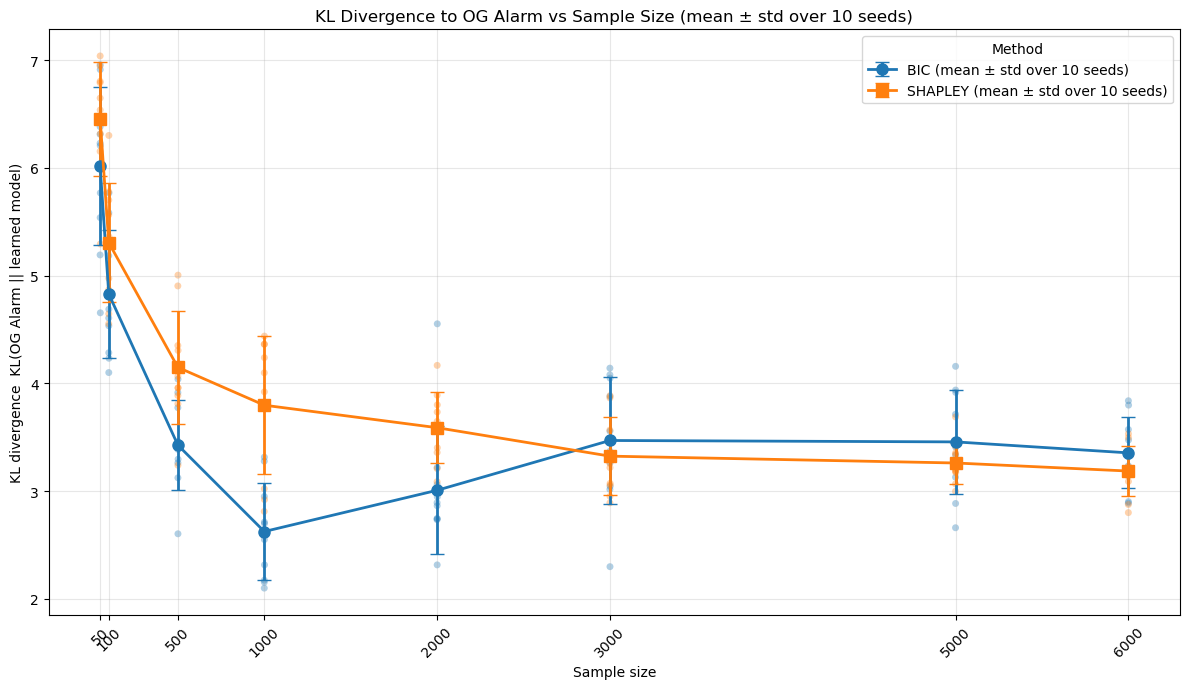

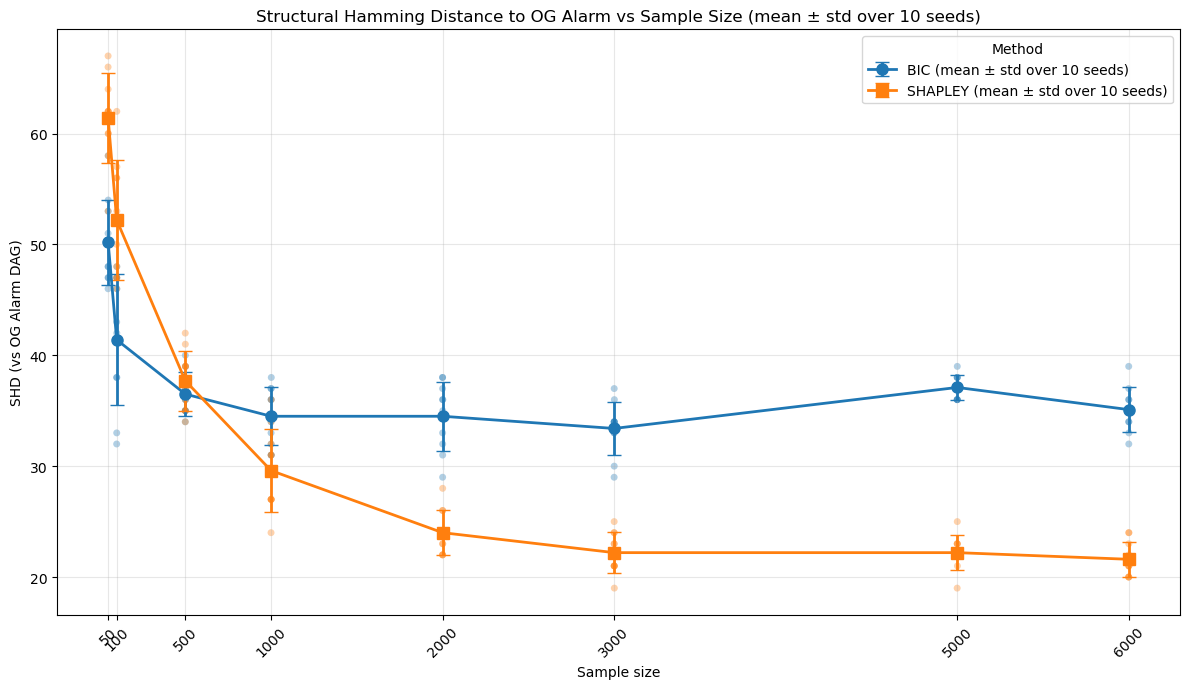

[Saved graph from the original run: 'Most graphs I could get together' notebook, cell 9]


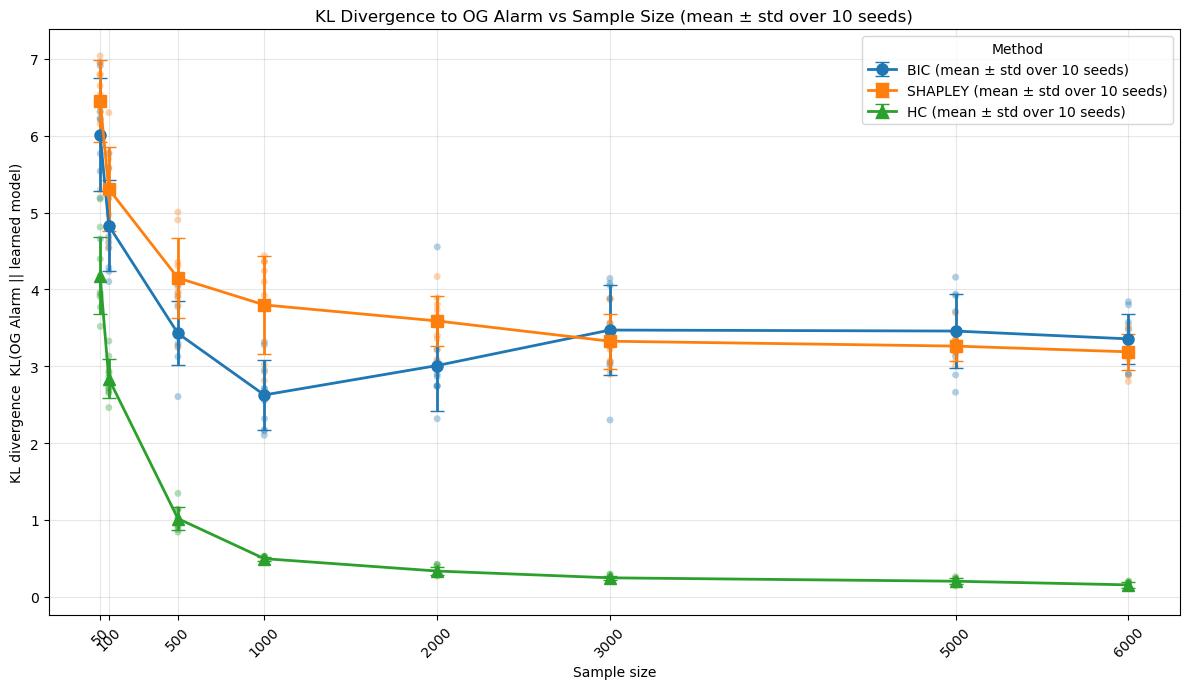

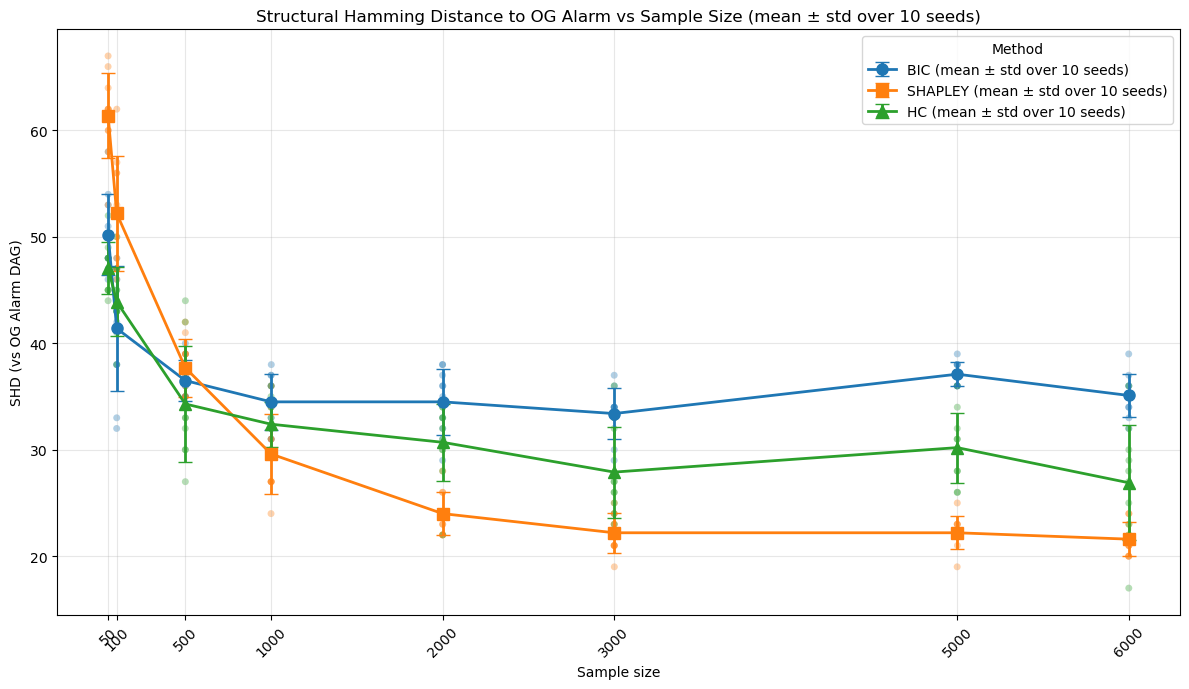

In [ ]:
def step_ten_seed_graphs():
    kl = pd.read_csv(os.path.join(RES, "KL_to_OG_Alarm_BIC_vs_SHAP_vs_HC_all_seeds.csv"))
    shd = pd.read_csv(os.path.join(RES, "SHD_to_OG_Alarm_BIC_vs_SHAP_vs_HC_all_seeds.csv"))
    n = kl["seed"].nunique()
    for methods, suffix in ((("BIC", "SHAPLEY"), "BIC_vs_SHAP_all_seeds"), (TEN_METHODS, "BIC_vs_SHAP_vs_HC_all_seeds")):
        plot_mean_std_over_seeds(kl, "KL", methods, os.path.join(RES, f"KL_to_OG_Alarm_{suffix}.png"),
                                 "KL divergence  KL(OG Alarm || learned model)",
                                 f"KL Divergence to OG Alarm vs Sample Size (mean ± std over {n} seeds)")
        plot_mean_std_over_seeds(shd, "SHD", methods, os.path.join(RES, f"SHD_to_OG_Alarm_{suffix}.png"),
                                 "SHD (vs OG Alarm DAG)",
                                 f"Structural Hamming Distance to OG Alarm vs Sample Size (mean ± std over {n} seeds)")

run_step("5.1_ten_seeds", step_ten_seed_graphs)

## 5.2 RQ2: Explaining KL divergence with double-parent nodes (CPT DoF)

The KL lines are taken from the 5.1 CSV. Your hard-coded "Table 6" values are kept below for comparison. `DOF_TRUE_CARDINALITY` applies here too.

[Saved graph from the original run: 'Most graphs I could get together' notebook, cell 15]


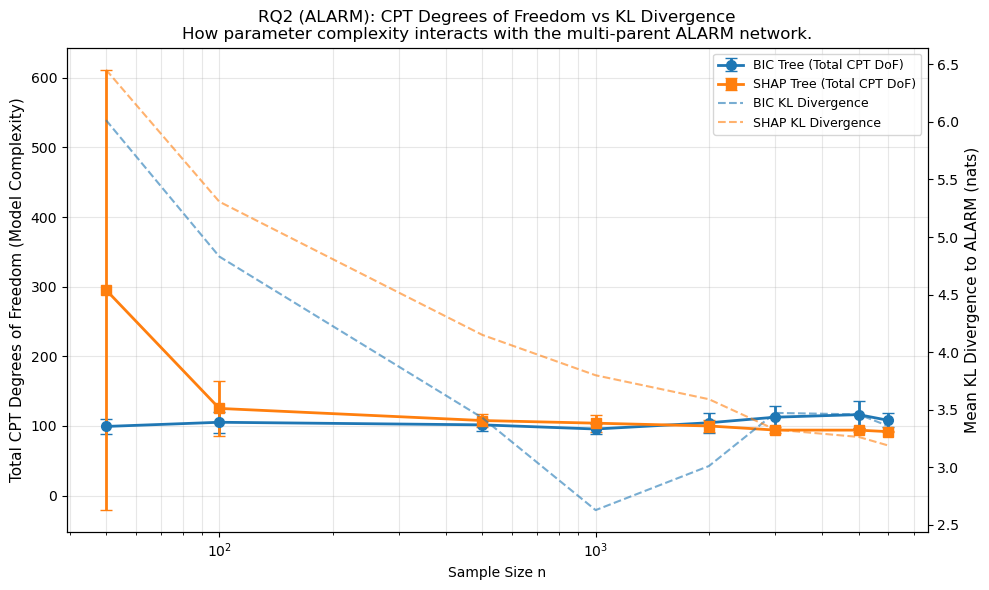

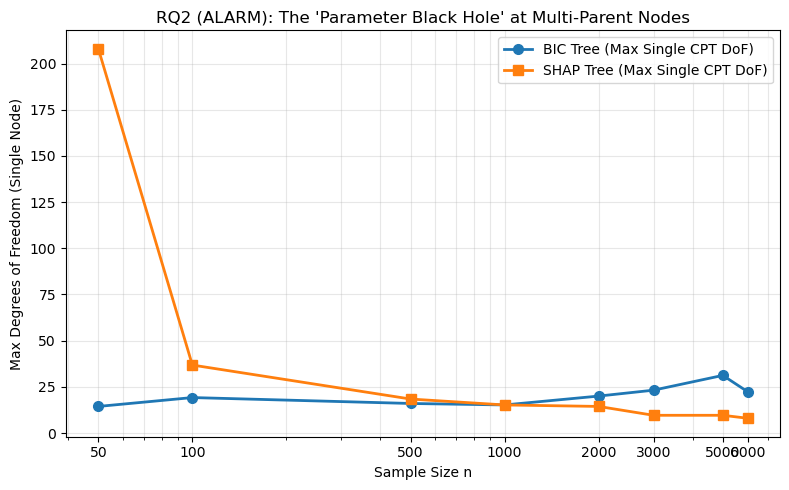

In [ ]:
TABLE6_KL_BIC  = {50: 6.016, 100: 4.830, 500: 3.428, 1000: 2.626, 2000: 3.009, 3000: 3.471, 5000: 3.458, 6000: 3.356}
TABLE6_KL_SHAP = {50: 6.454, 100: 5.307, 500: 4.149, 1000: 3.798, 2000: 3.590, 3000: 3.326, 5000: 3.262, 6000: 3.187}

def step_dof_rq2():
    rows = []
    for s in SEEDS:
        for j in SAMPLE_SIZES:
            for method, m in (("BIC", "BIC"), ("SHAP", "SHAPLEY")):
                p = os.path.join(res_dir(m, j, s), "directed_graph.graphml")
                if not os.path.exists(p):
                    print("Missing file:", p); continue
                rows.append(dof_row(nx.DiGraph(nx.read_graphml(p)), seed=s, n=j, method=method))
    df = pd.DataFrame(rows)
    agg = df.groupby(["method", "n"]).agg(mean_total_dof=("total_cpt_dof", "mean"), std_total_dof=("total_cpt_dof", "std"),
                                          mean_max_cpt=("max_single_cpt_dof", "mean"),
                                          mean_multi_parents=("num_multi_parent_nodes", "mean")).reset_index()
    print("=== RQ2: Mean Total CPT DoF ===\n", agg.to_string(index=False))
    klp = os.path.join(RES, "KL_to_OG_Alarm_BIC_vs_SHAP_all_seeds.csv")
    kl = pd.read_csv(klp) if os.path.exists(klp) else pd.DataFrame(columns=["method", "sample_size", "KL"])
    kl_bic, kl_shap = mean_kl_by_size(kl, "BIC", "sample_size"), mean_kl_by_size(kl, "SHAPLEY", "sample_size")
    print("\nKL means now vs Table 6:")
    print(pd.DataFrame({"BIC_now": kl_bic, "BIC_table6": TABLE6_KL_BIC,
                        "SHAP_now": kl_shap, "SHAP_table6": TABLE6_KL_SHAP}).round(3).to_string())
    plot_dof(agg, kl_bic or TABLE6_KL_BIC, kl_shap or TABLE6_KL_SHAP,
             "RQ2 (ALARM): CPT Degrees of Freedom vs KL Divergence",
             "RQ2 (ALARM): The 'Parameter Black Hole' at Multi-Parent Nodes",
             os.path.join(RES, "RQ2_cpt_dof_vs_kl.png"), os.path.join(RES, "RQ2_max_cpt_vs_sample.png"),
             "Mean KL Divergence to ALARM (nats)")

run_step("5.2_dof", step_dof_rq2)